# 27_04 — Evaluación predictiva · Australia del Sur (SA1) 5 min · precio spot · **barrido en $M$**

Paso **3b** del ciclo. Supone que `27_03_convergencia` dio veredicto OK **en
cada punto del barrido**; si las cadenas de un $M$ no convergieron, sus cifras
aquí no significan nada.

## Qué se reporta

- Predicción funcional a $h=1$ y su intervalo de credibilidad — se PERSISTEN, es lo que consume `27_05`
- **Bloque A** (MAE, RMSE, error máximo) sobre la ventana móvil
- **Bloque B** (Winkler, cobertura simultánea, cobertura puntual, MPIW) sobre la ventana móvil
- Muestra de predicciones: extractos regulares del test y las peores ventanas, con la curva anterior al lado
- Probabilidades posteriores de inclusión (PIP)
- Cuadro resumen: mínimo, máximo y promedio de cada métrica sobre la ventana
- Monitoreo univariado por componente FPCA
- **§10: evaluación puntual de los scores (coeficientes)** — banda de credibilidad de cada $\xi_k$, métricas de intervalo sobre ella, y dispersión $\hat\xi$ contra $\xi$

Todo el cálculo vive en `fit/` y todo el dibujo en `graphics/`: este notebook
sólo orquesta.



## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
)
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 27_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "sa1_precio", 2   # ventana 2: entrena 2022-2024, prueba 2025 (27_01 §1.1)
M_FPCA_LIST = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto de 27_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria; G = 288)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# §7: dispersión entre cadenas del PIP que se avisa.
SD_PIP_MAX = 0.15

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : real_sa1_precio_v02
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True, dominio=DOMINIO)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_obs, X_suav = DIS["grilla"], DIS["X_obs"], DIS["X_suav"]

  M  comp  cadenas  covariables  seed_base
  1     1        3            1  41232
  2     2        3            2  41232
  3     3        3            3  41232
  4     4        3            4  41232
  5     5        3            5  41232
  6     6        3            6  41232
  7     7        3            7  41232
  8     8        3            8  41232
  9     9        3            9  41232
 10    10        3           10  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=1  FPCA M=1 K=29  var. explicada=64.3697%  ·  curvas (1461, 288)
M=2  FPCA M=2 K=29  var. explicada=74.1819%  ·  curvas (1461, 288)
M=3  FPCA M=3 K=29  var. explicada=81.7499%  ·  curvas (1461, 288)
M=4  FPCA M=4 K=29  var. explicada=86.7709%  ·  curvas (1461, 288)
M=5  FPCA M=5 K=29  var. explicada=89.8083%  ·  curvas (1461, 288)
M=6  FPCA M=6 K=29  var. explicada=91.4054%  ·  curvas (1461, 288)
M=7  FPCA M=7 K=29  var. explicada=92.8710%  ·  curvas (1461, 288)
M=8  FPCA M=

## 2. Trazas MCMC

Una lectura por punto del barrido. El `feature_names` del `.mat` se verifica
contra las columnas del dataset: con $M$ distintos el número de covariables
cambia, y un `.mat` del punto equivocado se detectaría aquí y no más adelante
como un resultado raro.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS)     # los M efectivamente disponibles

OK M=1: 1 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=2: 2 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=7: 7 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=8: 8 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=9: 9 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=10: 10 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Predicción a $h=1$ sobre la serie completa


In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED)

origenes evaluados: 1460  (train 1095 · test 365)
SC_draws de TODO el barrido: 1927 MB en float32
M=1: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 35 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.145823   <- distancia del objetivo a su propia proyeccion en M
M=2: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 70 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.101679   <- distancia del objetivo a su propia proyeccion en M
M=3: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 105 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.067680   <- distancia del objetivo a su propia proyeccion en M
M=4: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 140 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.051501   <- distancia del objetivo a su propia proyeccion en M
M=5: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 175 MB
       MISE del TRUNCAMIENTO FPCA (test) =

### 3.1 Persistencia

La banda y la predicción puntual se guardan en `predict/` -no en `reports/`,
es un objeto de datos y no una salida de lectura- porque `27_05` las necesita
para calcular el Winkler del PSBPM-FD sobre su propia ventana móvil sin volver
a muestrear la predictiva completa.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG)

[M=1] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=2] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=3] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=4] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=5] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=6] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=7] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=8] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=9] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
[M=10] banda funcional -> banda_funcional_psbp.npz  (4.5 MB, (1460, 288))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


## 4. Bloque A: error puntual sobre la ventana móvil

Las tres normas del MISMO error $e_t(\tau) = X_t(\tau) - \hat X_t(\tau)$:

| | qué estima | qué añade |
|---|---|---|
| **MAE** ($L^1$) | mediana condicional | robusta: un origen catastrófico no la mueve |
| **RMSE** ($L^2$) | media condicional | la que usa el PSBPM-FD y el resto del capítulo |
| **Error máximo** ($L^\infty$, promedio por curva) | peor caso | por curva, $\max_\tau \lvert e_t(\tau)\rvert$; sobre la ventana, el promedio de esos $w$ máximos |

Todo se calcula UNA vez por M en `tablas_fun` -la misma tabla que consume el
Bloque B de §5- y se dibuja aquí SOLO el Bloque A.

[ventana_movil_funcional[w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=5.3s  t=16 [train] mise=0.2695
  71/1431 ( 5.0%) t=0.0s eta=0.5s  t=86 [train] mise=0.2312
  142/1431 ( 9.9%) t=0.0s eta=0.4s  t=157 [train] mise=0.5156
  213/1431 (14.9%) t=0.1s eta=0.4s  t=228 [train] mise=0.4464
  284/1431 (19.8%) t=0.1s eta=0.4s  t=299 [train] mise=0.3924
  355/1431 (24.8%) t=0.1s eta=0.3s  t=370 [train] mise=0.2486
  426/1431 (29.8%) t=0.1s eta=0.3s  t=441 [train] mise=0.213
  497/1431 (34.7%) t=0.2s eta=0.3s  t=512 [train] mise=0.4795
  568/1431 (39.7%) t=0.2s eta=0.3s  t=583 [train] mise=0.5209
  639/1431 (44.7%) t=0.2s eta=0.3s  t=654 [train] mise=0.167
  710/1431 (49.6%) t=0.3s eta=0.3s  t=725 [train] mise=0.2016
  781/1431 (54.6%) t=0.3s eta=0.2s  t=796 [train] mise=0.2334
  852/1431 (59.5%) t=0.3s eta=0.2s  t=867 [train] mise=0.2082
  923/1431 (64.5%) t=0.4s eta=0.2s  t=938 [train] mise=0.6137
  994/1431 (69.5%) t=0.4s eta=0.2s  t=1009 [train] mise=0.2962
  1065/1431 (74.4%) t=0.

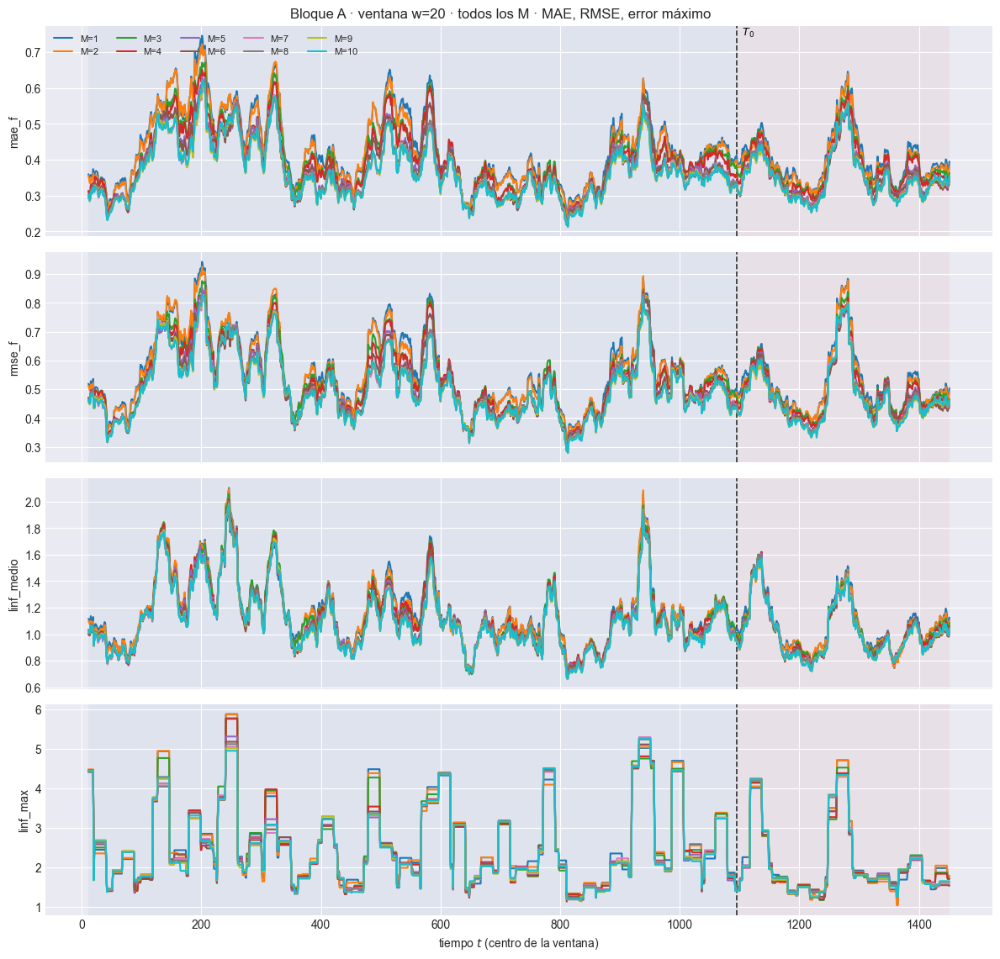

[plot_ventana_movil] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  mae_f: w=30 train=0.3771  w=30 test=0.3496
  2/4 (50.0%) t=0.1s eta=0.1s  rmse_f: w=30 train=0.5153  w=30 test=0.4586
  3/4 (75.0%) t=0.2s eta=0.1s  linf_medio: w=30 train=1.095  w=30 test=0.9753
  4/4 (100.0%) t=0.2s eta=0.0s  linf_max: w=30 train=2.602  w=30 test=1.832
[plot_ventana_movil] listo: 4 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_barrido_M\85_bloqueA_w30.png


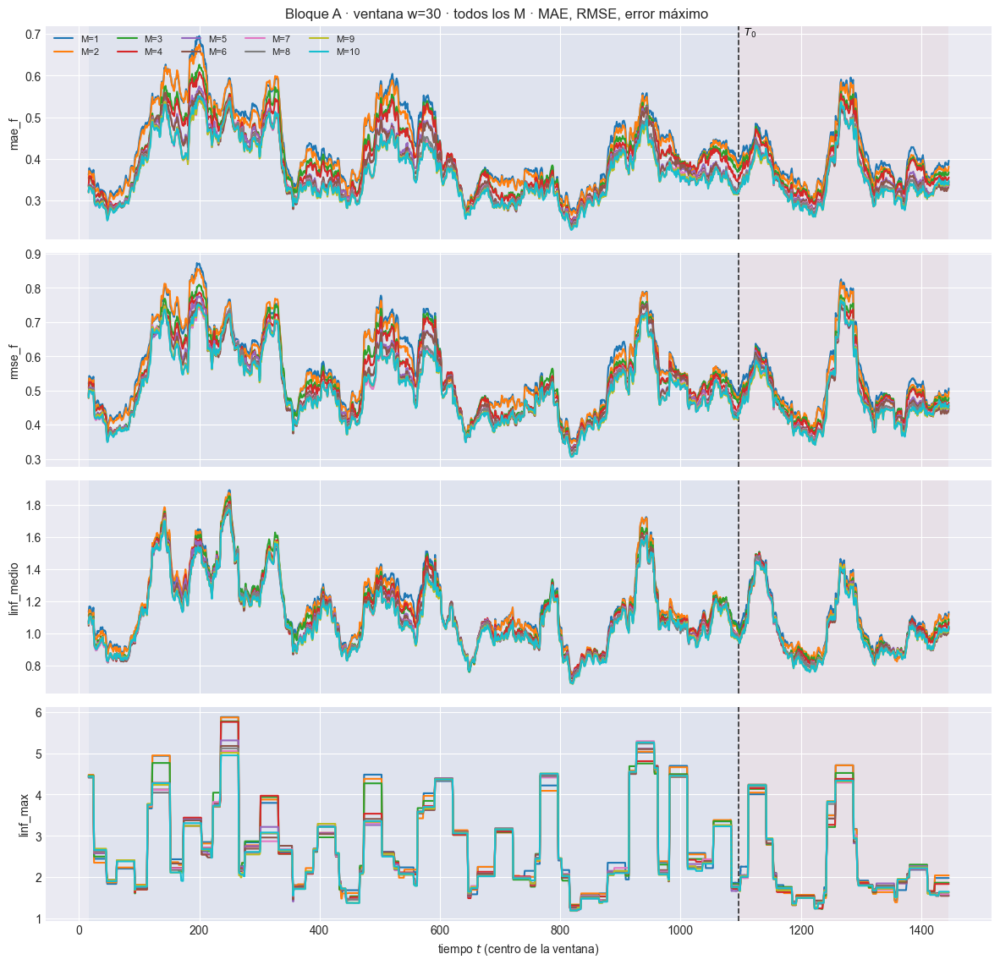

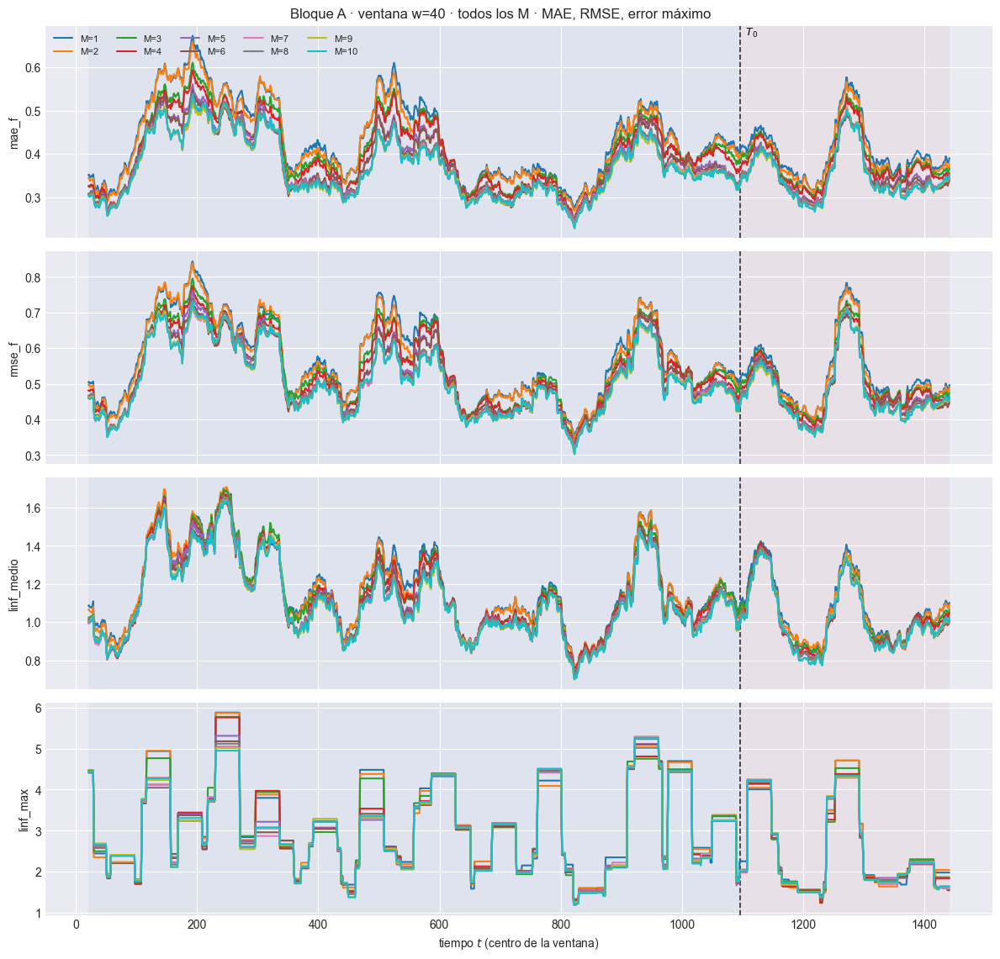

In [7]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?


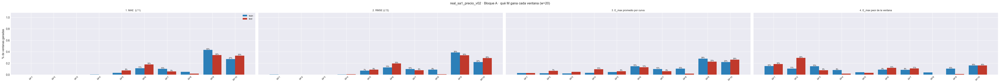

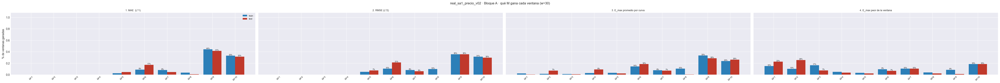

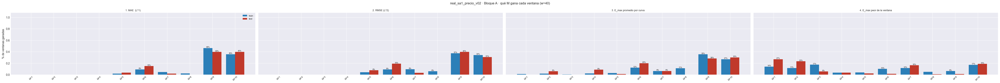

In [8]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

## 5. Bloque B: intervalos de predicción, en una sola vista

Cuatro cifras del intervalo, ninguna "primaria" en esta vista -el Winkler es
la única regla de puntuación propia y por eso es la que ordena modelos cuando
hace falta ordenar, pero aquí se muestran las cuatro juntas-:

| | qué es | de qué es |
|---|---|---|
| **Winkler** | interval score | penaliza ancho Y cobertura a la vez |
| **Cobertura simultánea** | de $w$ curvas, cuántas quedan COMPLETAS dentro de su banda (1/0 por curva) | fracción de CURVAS |
| **Cobertura puntual (PICP)** | de una curva, qué fracción de $\tau$ cae dentro | promedio de esa fracción sobre la ventana |
| **MPIW** | ancho medio de la banda | — |

La cobertura simultánea es SIEMPRE $\le$ la puntual: basta un $\tau$ fuera
para que la curva entera cuente como no cubierta.

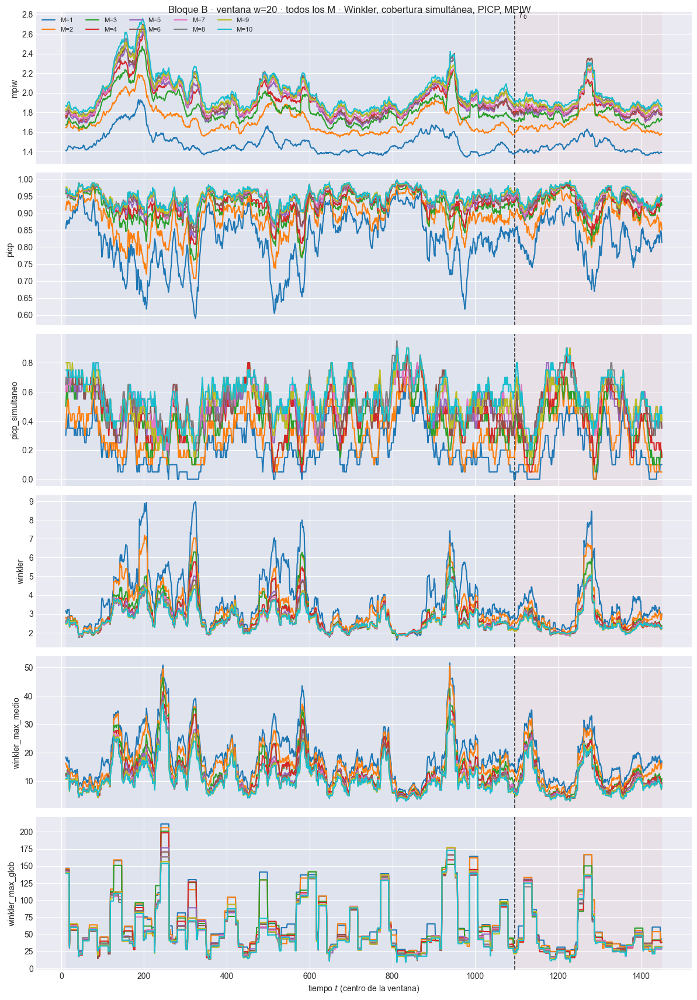

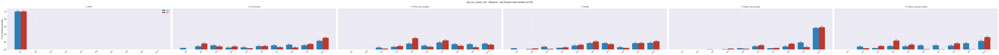

[plot_ventana_movil] inicio (6 pasos)
  1/6 (16.7%) t=0.0s eta=0.2s  mpiw: w=30 train=1.87  w=30 test=1.829
  2/6 (33.3%) t=0.1s eta=0.1s  picp: w=30 train=0.936  w=30 test=0.9337
  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.4667  w=30 test=0.4667
  4/6 (66.7%) t=0.1s eta=0.1s  winkler: w=30 train=2.754  w=30 test=2.419
  5/6 (83.3%) t=0.2s eta=0.0s  winkler_max_medio: w=30 train=12.07  w=30 test=9.29
  6/6 (100.0%) t=0.2s eta=0.0s  winkler_max_glob: w=30 train=62.34  w=30 test=38.18
[plot_ventana_movil] listo: 6 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_barrido_M\86_bloqueB_w30.png


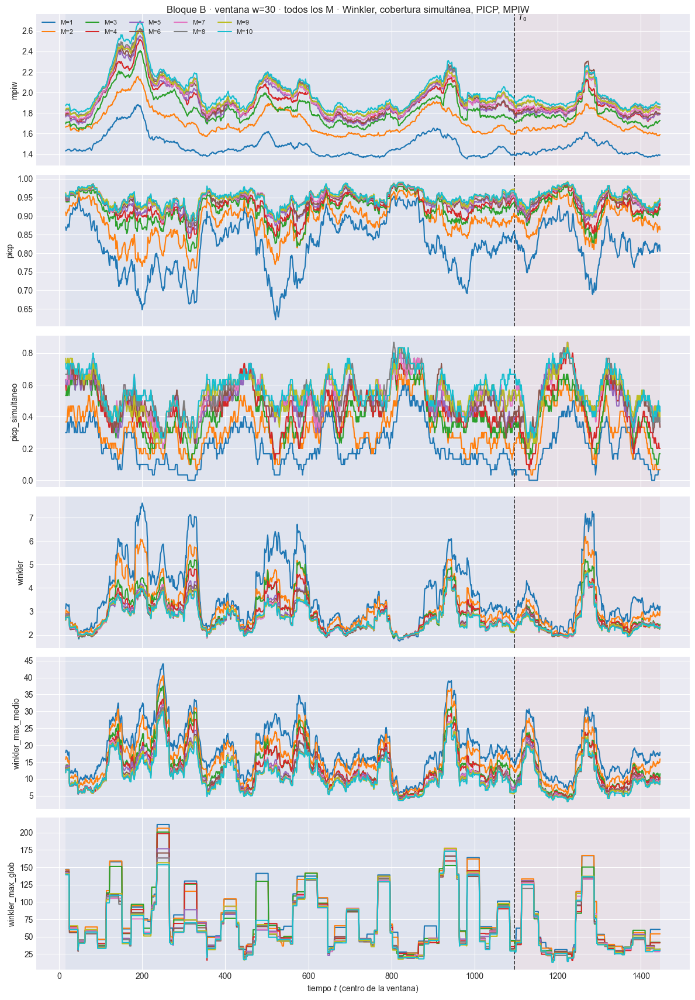

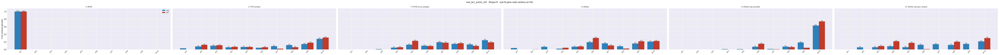

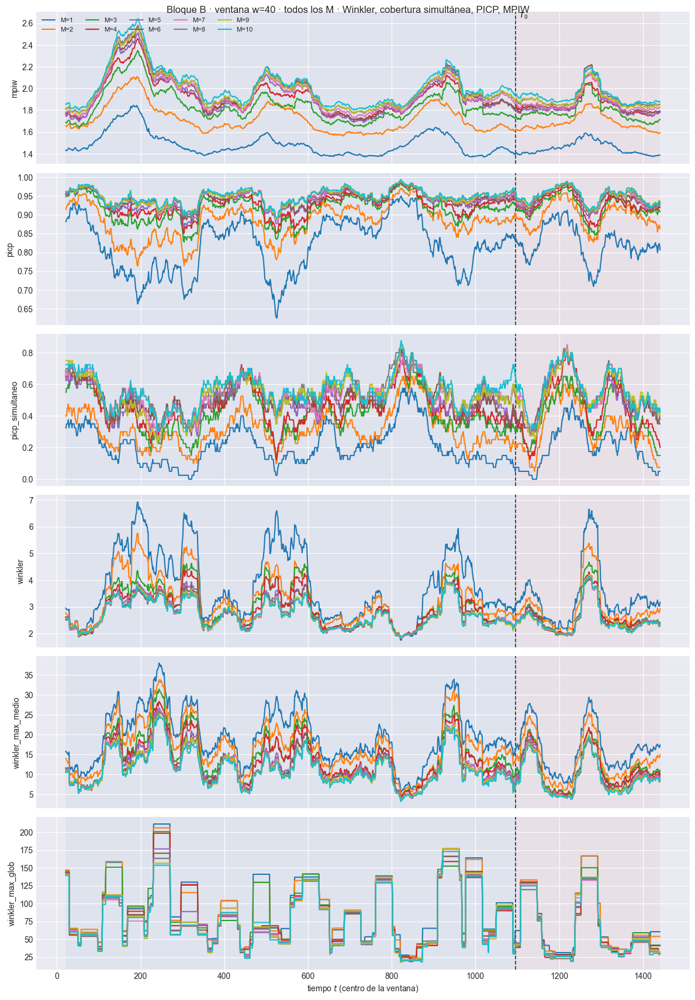

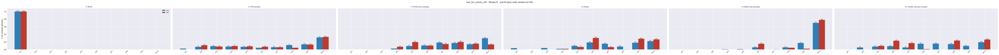

In [9]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

## 6. Muestra de predicciones

Dos vistas: un extracto regular del bloque de **prueba** (para no mezclar con
in-sample), y las ventanas con **peor** valor de `METRICA_PEORES` ([CONFIG]).
En la segunda se agrega la curva **anterior** ($t-1$, gris punteada): es el
primer diagnóstico de POR QUÉ el modelo se equivocó -¿la curva de partida ya
era atípica?-.

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.0s  t=1097 [test] cob=0.635 rmse=0.7699
  2/13 (15.4%) t=0.0s eta=0.1s  t=1127 [test] cob=0.955 rmse=0.269
  3/13 (23.1%) t=0.0s eta=0.1s  t=1157 [test] cob=0.615 rmse=0.79
  4/13 (30.8%) t=0.1s eta=0.1s  t=1187 [test] cob=0.927 rmse=0.4203
  5/13 (38.5%) t=0.1s eta=0.1s  t=1217 [test] cob=1.000 rmse=0.2922
  6/13 (46.2%) t=0.1s eta=0.1s  t=1247 [test] cob=1.000 rmse=0.2098
  7/13 (53.8%) t=0.1s eta=0.1s  t=1277 [test] cob=0.976 rmse=0.4043
  8/13 (61.5%) t=0.1s eta=0.1s  t=1307 [test] cob=1.000 rmse=0.242
  9/13 (69.2%) t=0.1s eta=0.0s  t=1337 [test] cob=0.670 rmse=0.3981
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.3003
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=0.986 rmse=0.2638
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.882 rmse=0.3539
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.2119
[plot_extractos_curvas] listo: 13 pasos en 1.5s  cob media train=nan test

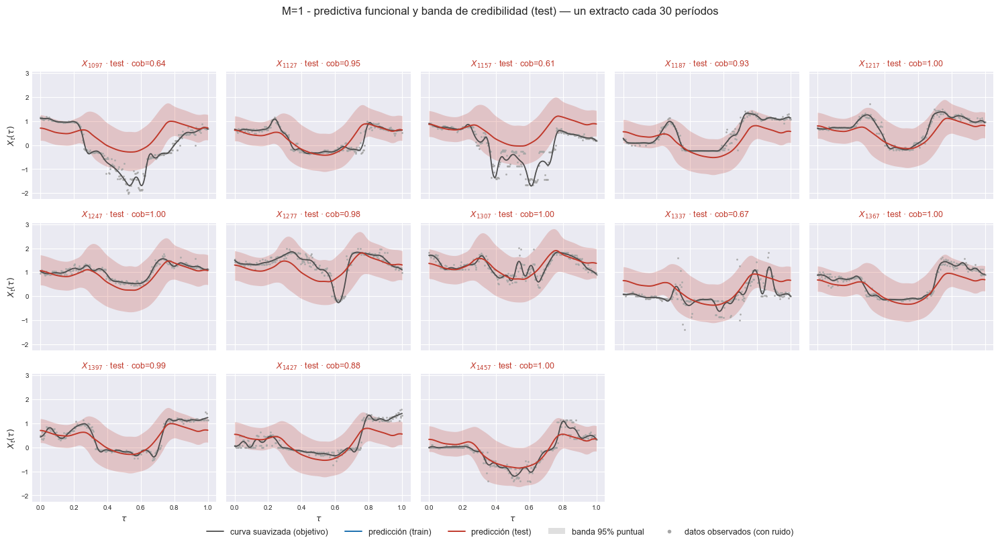

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.0s  t=1097 [test] cob=0.740 rmse=0.6847
  2/13 (15.4%) t=0.0s eta=0.1s  t=1127 [test] cob=0.965 rmse=0.2585
  3/13 (23.1%) t=0.0s eta=0.1s  t=1157 [test] cob=0.740 rmse=0.7287
  4/13 (30.8%) t=0.0s eta=0.0s  t=1187 [test] cob=1.000 rmse=0.3572
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.3175
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.186
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4039
  8/13 (61.5%) t=0.0s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2411
  9/13 (69.2%) t=0.0s eta=0.0s  t=1337 [test] cob=0.882 rmse=0.4144
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=0.969 rmse=0.3253
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=1.000 rmse=0.2856
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.858 rmse=0.3429
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=0.986 rmse=0.2008
[plot_extractos_curvas] listo: 13 pasos en 1.5s  cob media train=nan t

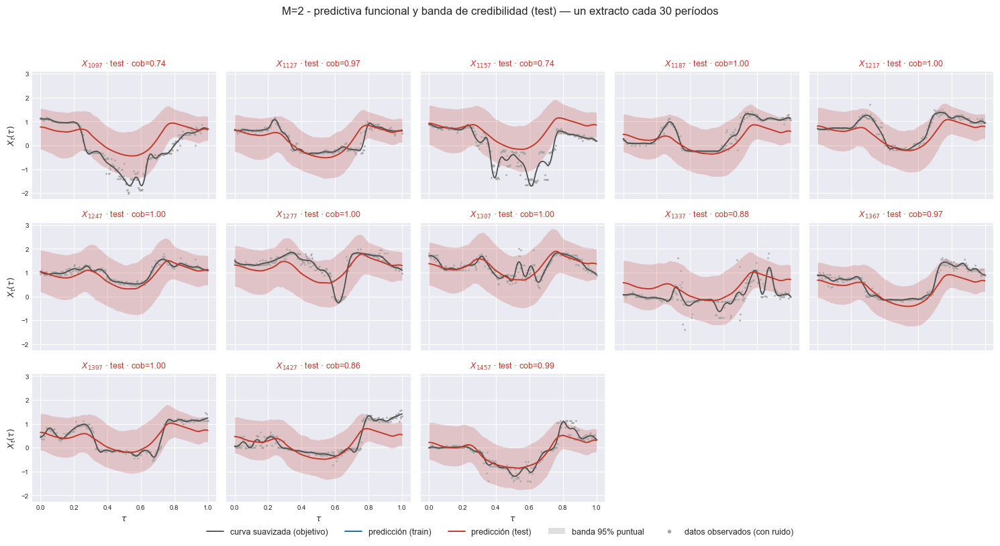

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.0s  t=1097 [test] cob=0.774 rmse=0.6775
  2/13 (15.4%) t=0.0s eta=0.1s  t=1127 [test] cob=0.990 rmse=0.2731
  3/13 (23.1%) t=0.0s eta=0.1s  t=1157 [test] cob=0.774 rmse=0.6565
  4/13 (30.8%) t=0.0s eta=0.0s  t=1187 [test] cob=0.931 rmse=0.4545
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.2918
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.2469
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4571
  8/13 (61.5%) t=0.0s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2601
  9/13 (69.2%) t=0.1s eta=0.0s  t=1337 [test] cob=0.993 rmse=0.3697
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.3584
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=0.972 rmse=0.4304
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.840 rmse=0.4398
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.2153
[plot_extractos_curvas] listo: 13 pasos en 1.4s  cob media train=nan 

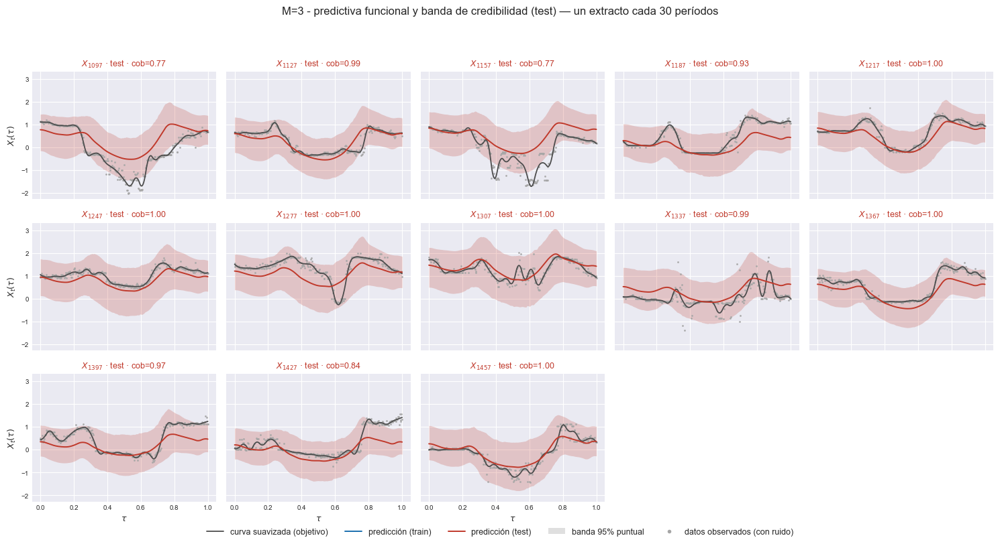

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.0s  t=1097 [test] cob=0.826 rmse=0.6525
  2/13 (15.4%) t=0.0s eta=0.0s  t=1127 [test] cob=0.993 rmse=0.2677
  3/13 (23.1%) t=0.0s eta=0.0s  t=1157 [test] cob=0.826 rmse=0.6571
  4/13 (30.8%) t=0.0s eta=0.0s  t=1187 [test] cob=0.955 rmse=0.4581
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.2801
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.2536
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4673
  8/13 (61.5%) t=0.0s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2483
  9/13 (69.2%) t=0.0s eta=0.0s  t=1337 [test] cob=0.976 rmse=0.3735
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=0.944 rmse=0.3603
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=0.986 rmse=0.4401
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.868 rmse=0.4593
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.219
[plot_extractos_curvas] listo: 13 pasos en 1.4s  cob media train=nan t

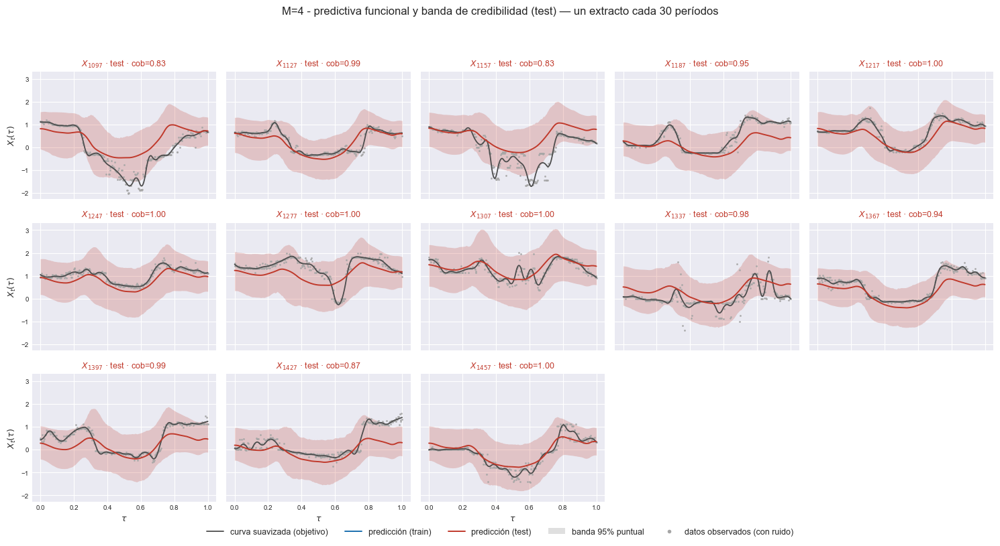

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.1s  t=1097 [test] cob=0.806 rmse=0.6329
  2/13 (15.4%) t=0.0s eta=0.1s  t=1127 [test] cob=1.000 rmse=0.2319
  3/13 (23.1%) t=0.0s eta=0.1s  t=1157 [test] cob=0.812 rmse=0.656
  4/13 (30.8%) t=0.0s eta=0.0s  t=1187 [test] cob=1.000 rmse=0.4694
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.2751
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.2462
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4638
  8/13 (61.5%) t=0.0s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2501
  9/13 (69.2%) t=0.1s eta=0.0s  t=1337 [test] cob=0.983 rmse=0.3794
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.3391
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=1.000 rmse=0.4515
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.910 rmse=0.419
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.2042
[plot_extractos_curvas] listo: 13 pasos en 1.4s  cob media train=nan te

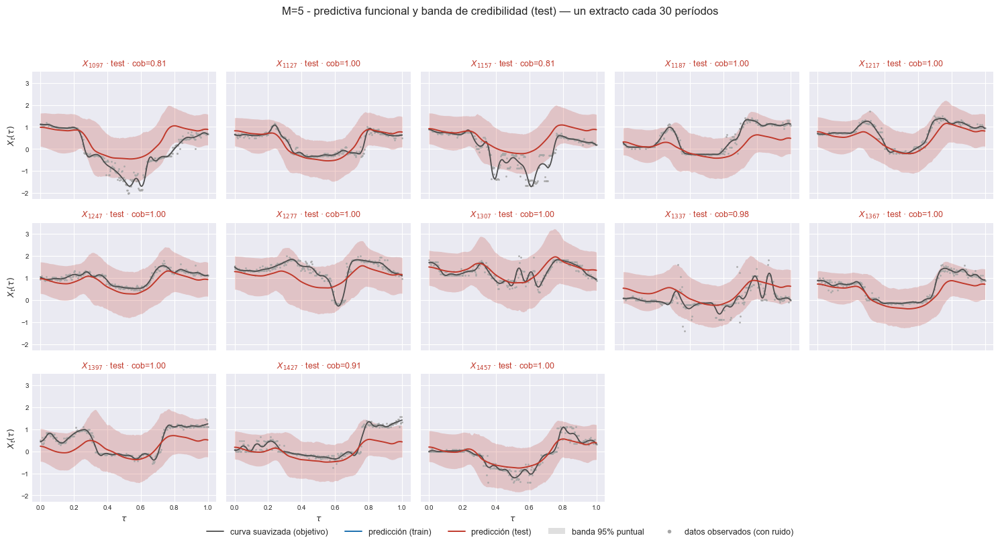

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.1s  t=1097 [test] cob=0.806 rmse=0.6358
  2/13 (15.4%) t=0.0s eta=0.1s  t=1127 [test] cob=1.000 rmse=0.2281
  3/13 (23.1%) t=0.0s eta=0.1s  t=1157 [test] cob=0.830 rmse=0.6456
  4/13 (30.8%) t=0.0s eta=0.1s  t=1187 [test] cob=1.000 rmse=0.4591
  5/13 (38.5%) t=0.0s eta=0.1s  t=1217 [test] cob=1.000 rmse=0.281
  6/13 (46.2%) t=0.0s eta=0.1s  t=1247 [test] cob=1.000 rmse=0.2378
  7/13 (53.8%) t=0.1s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4499
  8/13 (61.5%) t=0.1s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2568
  9/13 (69.2%) t=0.1s eta=0.0s  t=1337 [test] cob=1.000 rmse=0.3829
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.3395
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=1.000 rmse=0.3938
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.910 rmse=0.4324
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.2061
[plot_extractos_curvas] listo: 13 pasos en 1.6s  cob media train=nan t

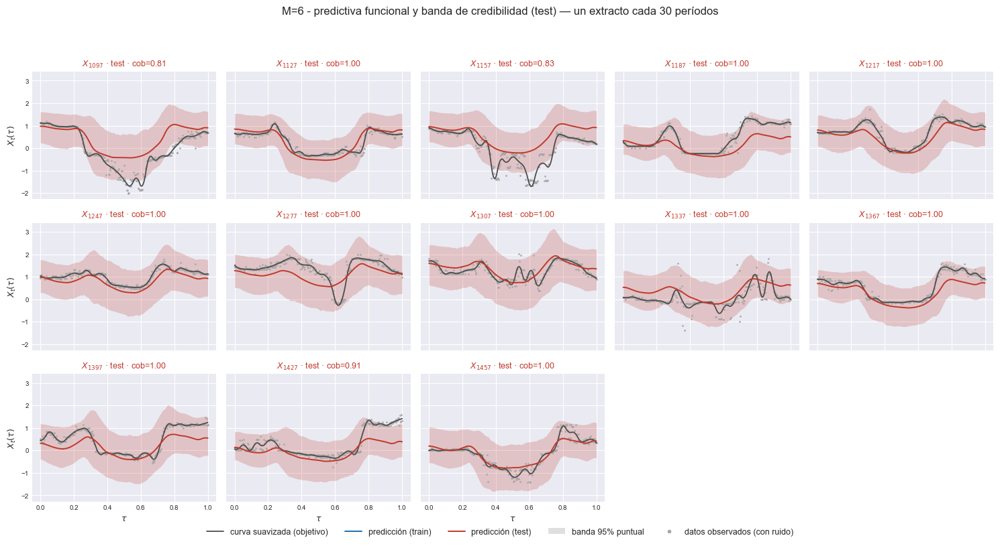

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.1s  t=1097 [test] cob=0.774 rmse=0.6712
  2/13 (15.4%) t=0.0s eta=0.1s  t=1127 [test] cob=1.000 rmse=0.2265
  3/13 (23.1%) t=0.0s eta=0.1s  t=1157 [test] cob=0.844 rmse=0.7098
  4/13 (30.8%) t=0.0s eta=0.1s  t=1187 [test] cob=1.000 rmse=0.4457
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.3072
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.2179
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4369
  8/13 (61.5%) t=0.1s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.291
  9/13 (69.2%) t=0.1s eta=0.0s  t=1337 [test] cob=1.000 rmse=0.3493
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.3169
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=1.000 rmse=0.3892
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.892 rmse=0.4139
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.2238
[plot_extractos_curvas] listo: 13 pasos en 1.6s  cob media train=nan t

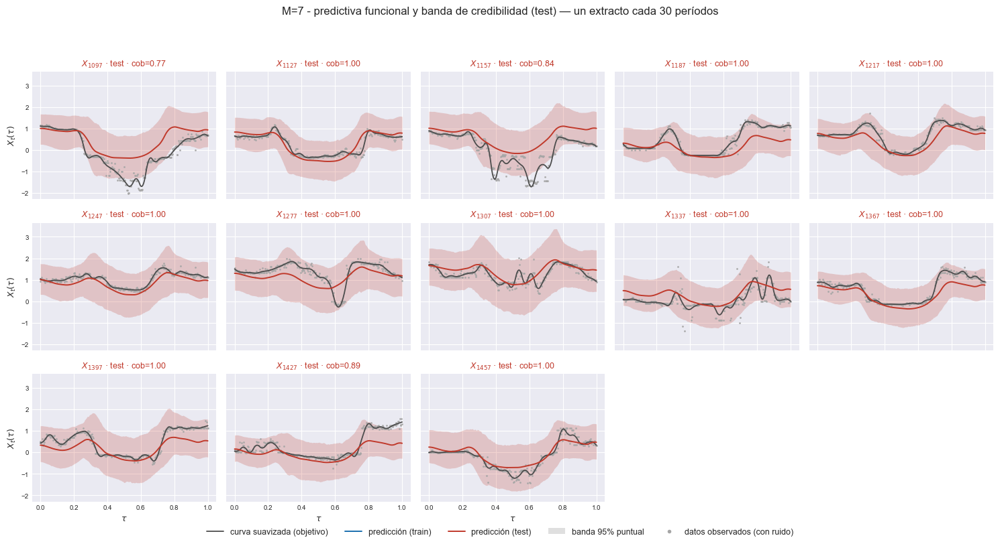

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.0s  t=1097 [test] cob=0.792 rmse=0.674
  2/13 (15.4%) t=0.0s eta=0.0s  t=1127 [test] cob=1.000 rmse=0.2282
  3/13 (23.1%) t=0.0s eta=0.0s  t=1157 [test] cob=0.830 rmse=0.7276
  4/13 (30.8%) t=0.0s eta=0.1s  t=1187 [test] cob=1.000 rmse=0.4555
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.2995
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.2135
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4427
  8/13 (61.5%) t=0.1s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2753
  9/13 (69.2%) t=0.1s eta=0.0s  t=1337 [test] cob=1.000 rmse=0.347
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.3071
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=1.000 rmse=0.4047
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.875 rmse=0.4047
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.227
[plot_extractos_curvas] listo: 13 pasos en 1.3s  cob media train=nan tes

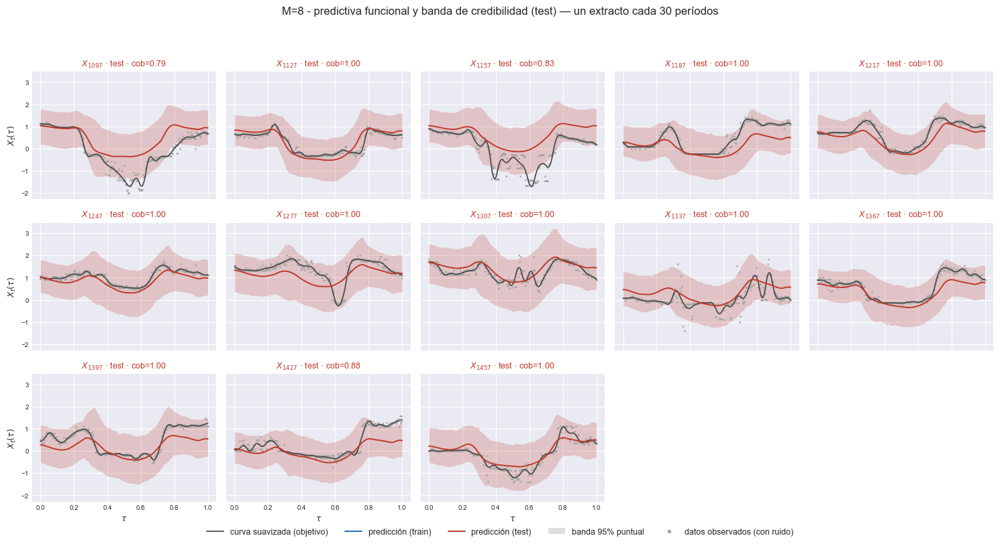

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.0s  t=1097 [test] cob=0.826 rmse=0.6347
  2/13 (15.4%) t=0.0s eta=0.1s  t=1127 [test] cob=1.000 rmse=0.228
  3/13 (23.1%) t=0.0s eta=0.1s  t=1157 [test] cob=0.823 rmse=0.7162
  4/13 (30.8%) t=0.0s eta=0.1s  t=1187 [test] cob=0.986 rmse=0.4483
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.2708
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.1834
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=1.000 rmse=0.4441
  8/13 (61.5%) t=0.0s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2727
  9/13 (69.2%) t=0.1s eta=0.0s  t=1337 [test] cob=1.000 rmse=0.3418
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.298
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=1.000 rmse=0.3849
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.910 rmse=0.4125
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.2299
[plot_extractos_curvas] listo: 13 pasos en 1.6s  cob media train=nan te

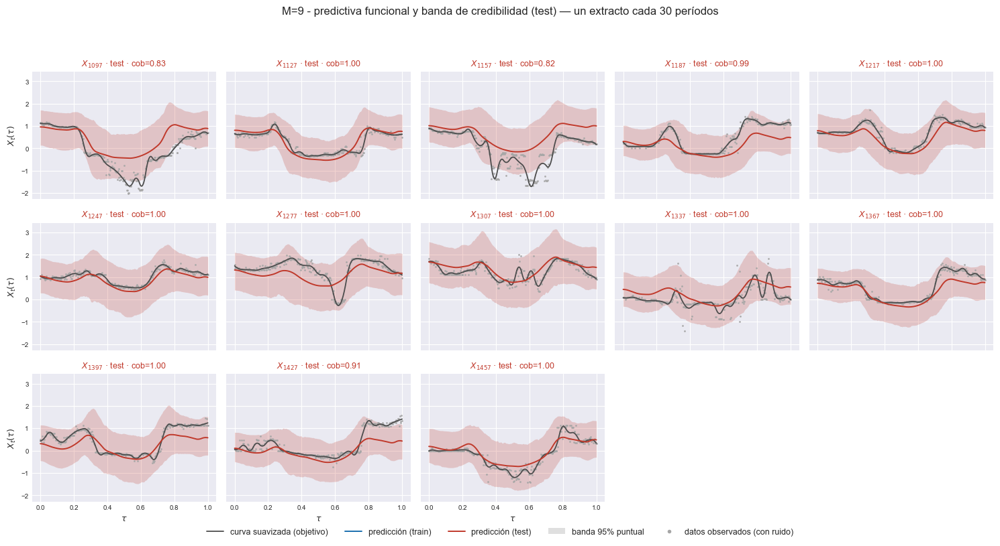

[plot_extractos_curvas] inicio (13 pasos)
  1/13 ( 7.7%) t=0.0s eta=0.0s  t=1097 [test] cob=0.830 rmse=0.6414
  2/13 (15.4%) t=0.0s eta=0.0s  t=1127 [test] cob=1.000 rmse=0.2237
  3/13 (23.1%) t=0.0s eta=0.0s  t=1157 [test] cob=0.812 rmse=0.7409
  4/13 (30.8%) t=0.0s eta=0.0s  t=1187 [test] cob=1.000 rmse=0.441
  5/13 (38.5%) t=0.0s eta=0.0s  t=1217 [test] cob=1.000 rmse=0.2736
  6/13 (46.2%) t=0.0s eta=0.0s  t=1247 [test] cob=1.000 rmse=0.1898
  7/13 (53.8%) t=0.0s eta=0.0s  t=1277 [test] cob=0.990 rmse=0.4434
  8/13 (61.5%) t=0.0s eta=0.0s  t=1307 [test] cob=1.000 rmse=0.2634
  9/13 (69.2%) t=0.0s eta=0.0s  t=1337 [test] cob=1.000 rmse=0.3435
  10/13 (76.9%) t=0.1s eta=0.0s  t=1367 [test] cob=1.000 rmse=0.2869
  11/13 (84.6%) t=0.1s eta=0.0s  t=1397 [test] cob=1.000 rmse=0.3614
  12/13 (92.3%) t=0.1s eta=0.0s  t=1427 [test] cob=0.927 rmse=0.3964
  13/13 (100.0%) t=0.1s eta=0.0s  t=1457 [test] cob=1.000 rmse=0.2148
[plot_extractos_curvas] listo: 13 pasos en 1.4s  cob media train=nan t

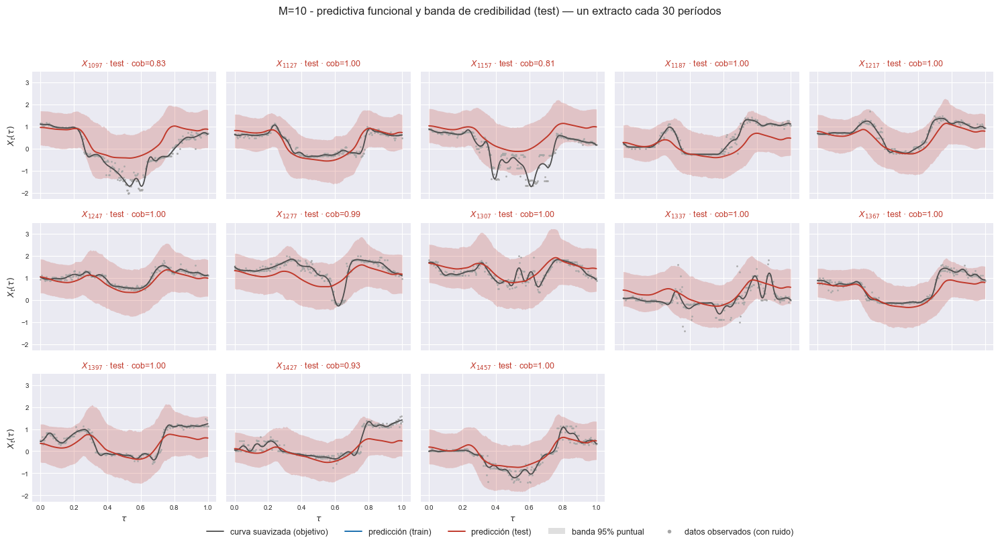

In [10]:
# Extractos regulares, SOLO del bloque de prueba.
mask_test = ~es_train
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[mask_test], e["X_pred"][mask_test], e["li_f"][mask_test], e["ls_f"][mask_test],
        grilla, T0, t=t_orig[mask_test], cada=CADA, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[mask_test],
        title=f"M={M} - predictiva funcional y banda de credibilidad (test)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=0.972 rmse=0.3552
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=0.958 rmse=0.3392
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=0.955 rmse=0.3054
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.771 rmse=0.5362
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.635 rmse=0.7699
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=0.986 rmse=0.3283
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.771 rmse=0.4993
[plot_extractos_curvas] listo: 7 pasos en 0.9s  cob media train=0.914 test=0.797 (nominal 0.95)


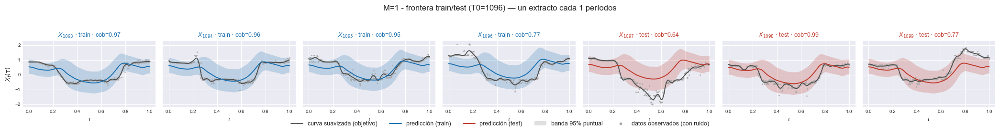

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=0.962 rmse=0.3914
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.333
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=0.972 rmse=0.3049
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.917 rmse=0.5011
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.740 rmse=0.6847
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2726
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.726 rmse=0.5227
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.963 test=0.822 (nominal 0.95)


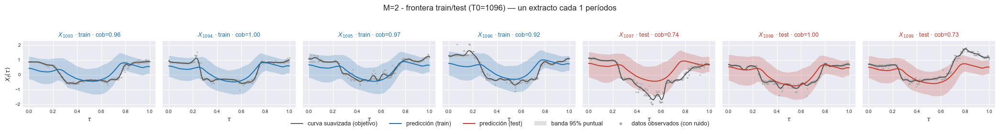

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3982
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.3373
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.2871
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.920 rmse=0.5113
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.774 rmse=0.6775
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.3014
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.851 rmse=0.4814
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.980 test=0.875 (nominal 0.95)


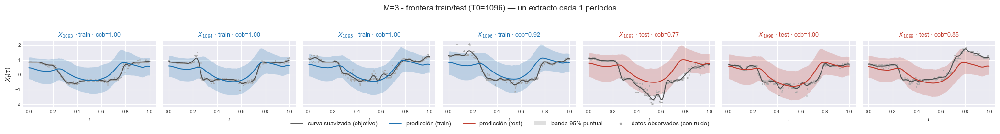

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3989
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2954
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.2476
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.955 rmse=0.4614
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.826 rmse=0.6525
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2782
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.816 rmse=0.4753
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.989 test=0.881 (nominal 0.95)


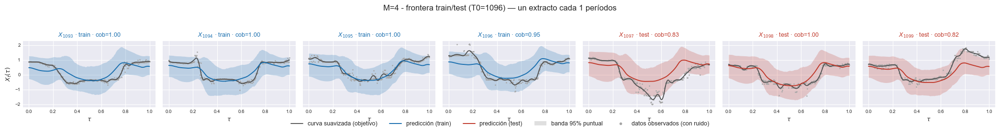

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3056
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.1828
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1558
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.979 rmse=0.409
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.806 rmse=0.6329
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2529
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.892 rmse=0.4658
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.995 test=0.899 (nominal 0.95)


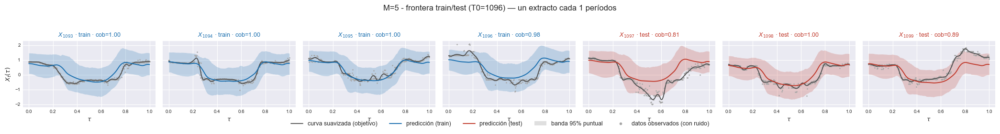

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.2977
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.1877
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1578
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.976 rmse=0.4065
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.806 rmse=0.6358
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2425
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.955 rmse=0.4663
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.994 test=0.920 (nominal 0.95)


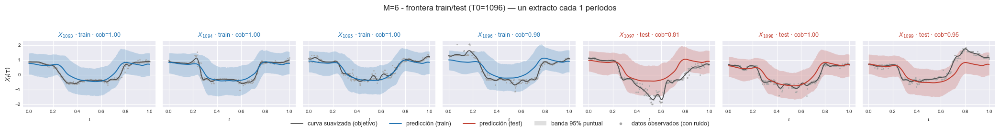

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3266
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2003
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1558
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.4347
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.774 rmse=0.6712
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2856
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.962 rmse=0.4415
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=1.000 test=0.912 (nominal 0.95)


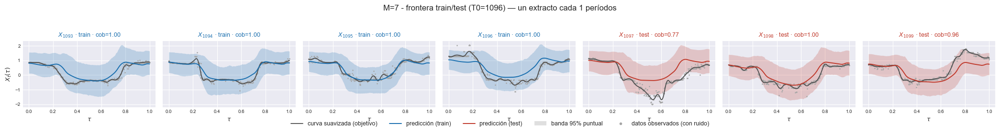

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.314
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2088
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1555
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.433
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.792 rmse=0.674
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.3141
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.972 rmse=0.4383
[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=1.000 test=0.921 (nominal 0.95)


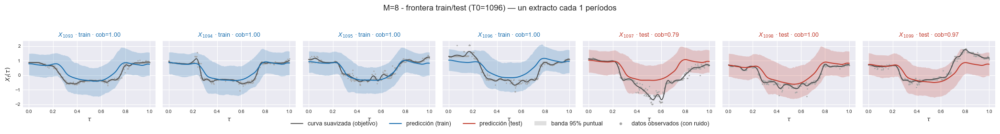

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3122
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2108
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1678
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.4217
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.826 rmse=0.6347
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2968
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.962 rmse=0.4489
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=1.000 test=0.929 (nominal 0.95)


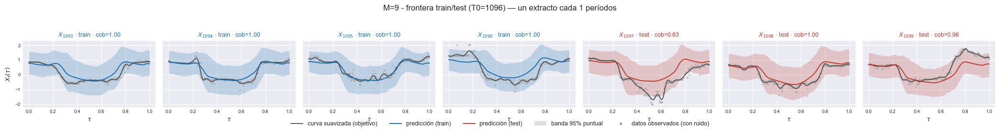

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3063
  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2095
  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1642
  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.4246
  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.830 rmse=0.6414
  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2952
  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=1.000 rmse=0.4556
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=1.000 test=0.943 (nominal 0.95)


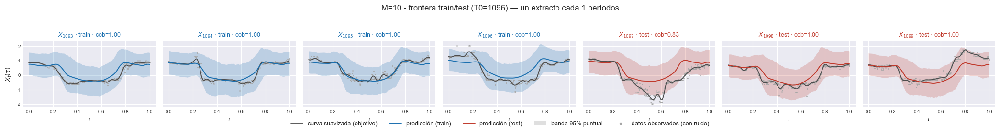

In [11]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=1] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.825109


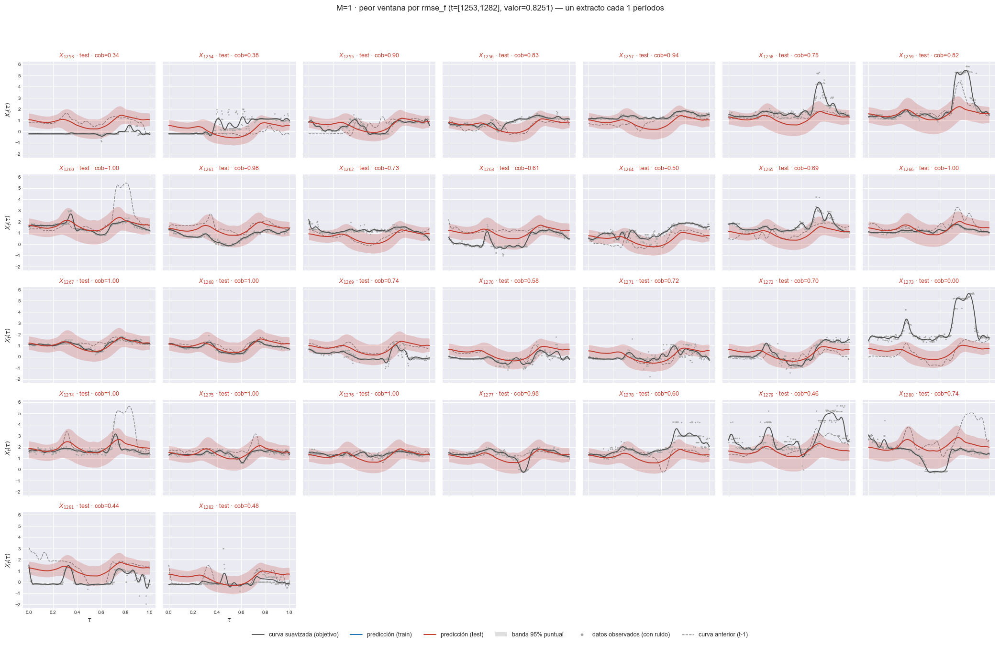

    t=[1252, 1281]  rmse_f=0.821358


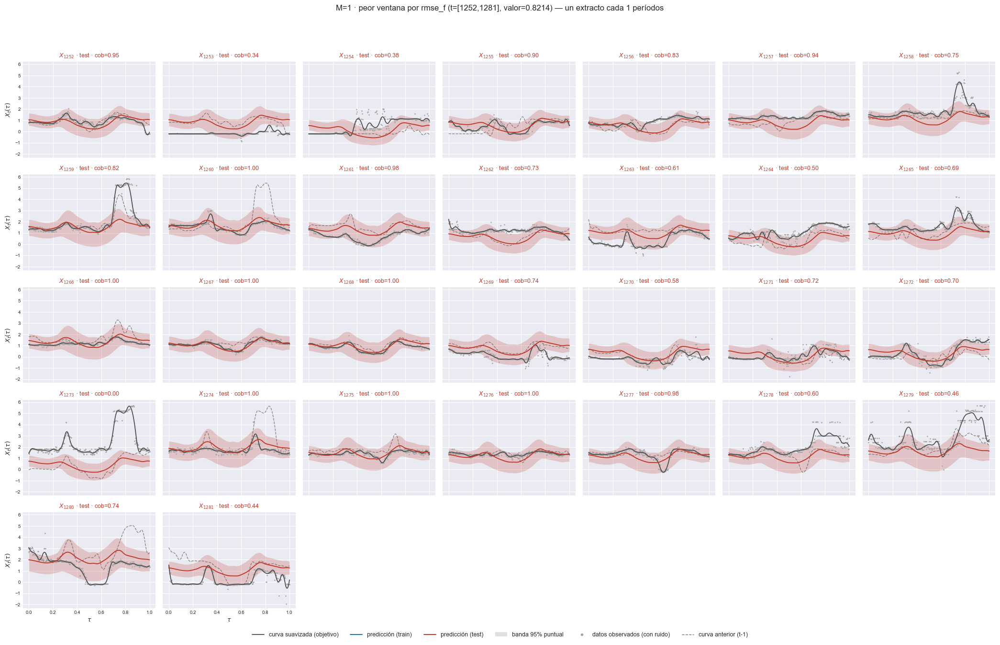

    t=[1257, 1286]  rmse_f=0.816109


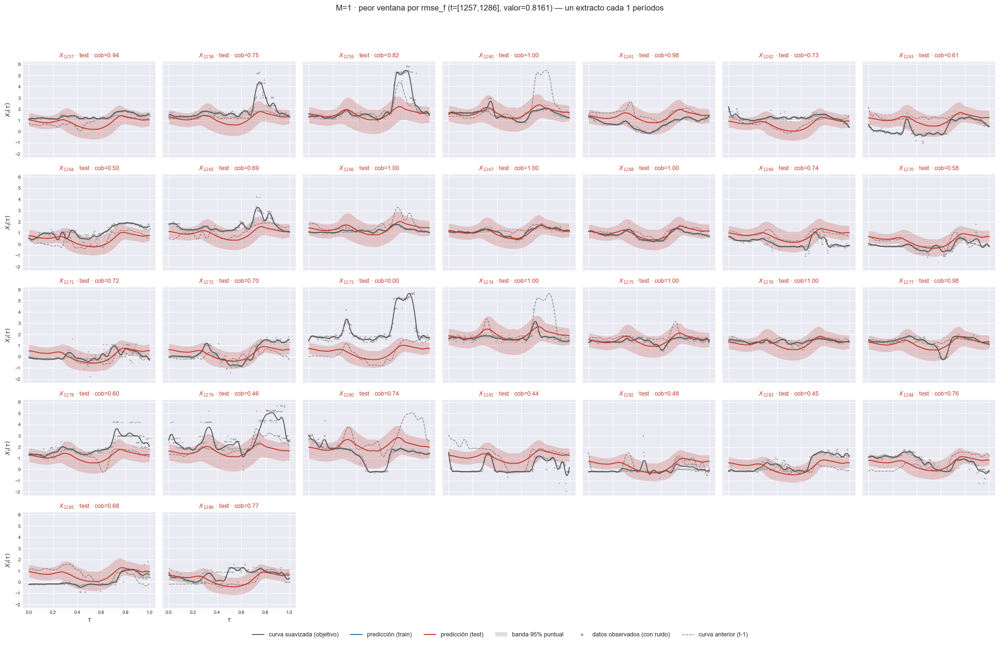

    t=[1258, 1287]  rmse_f=0.813166


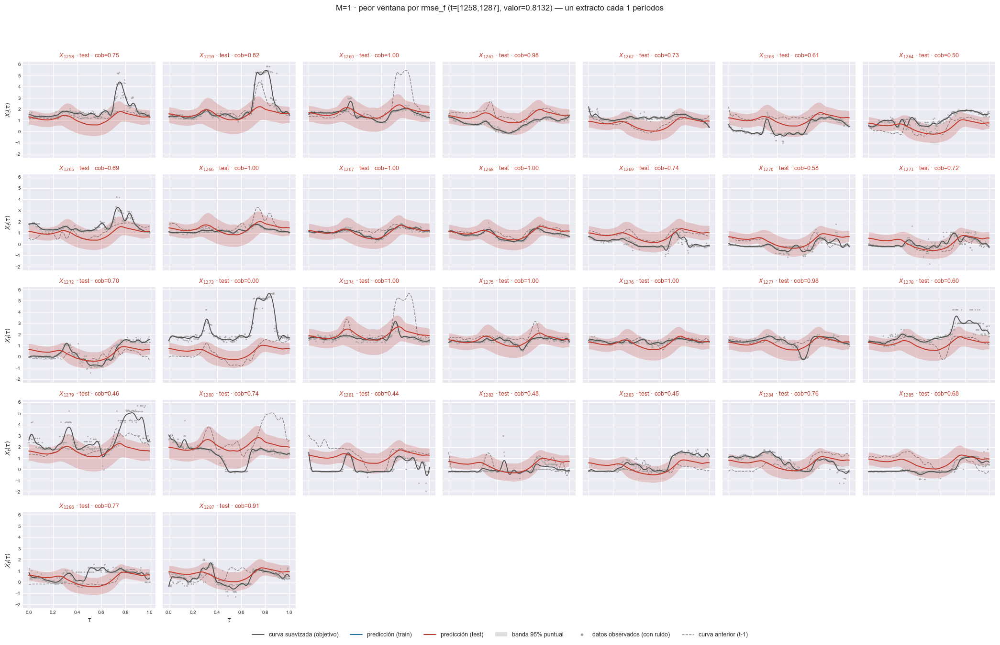

    t=[1256, 1285]  rmse_f=0.811707


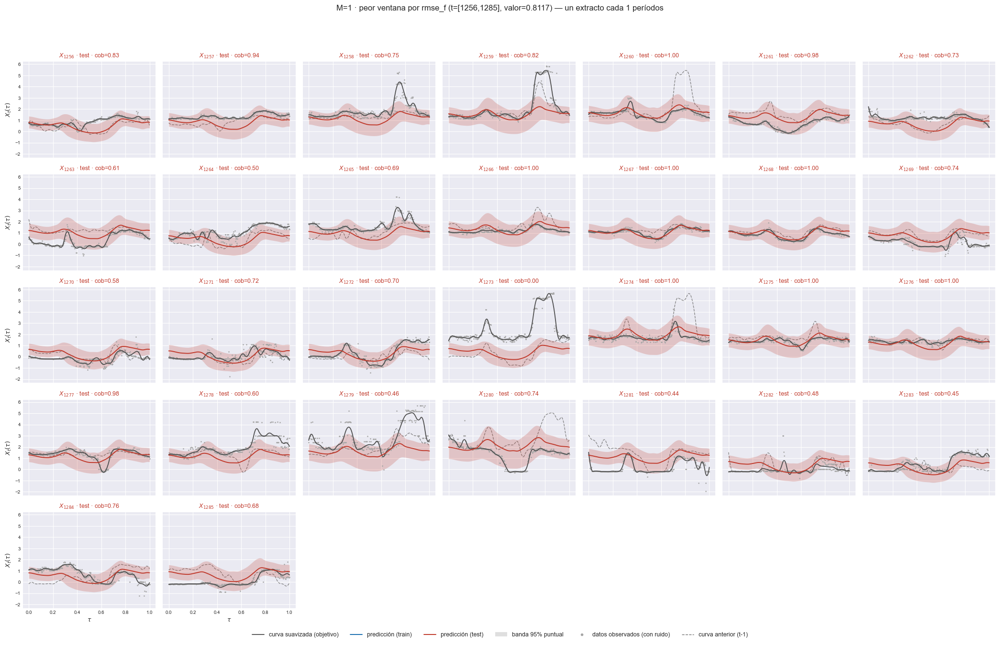

[M=2] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.816734


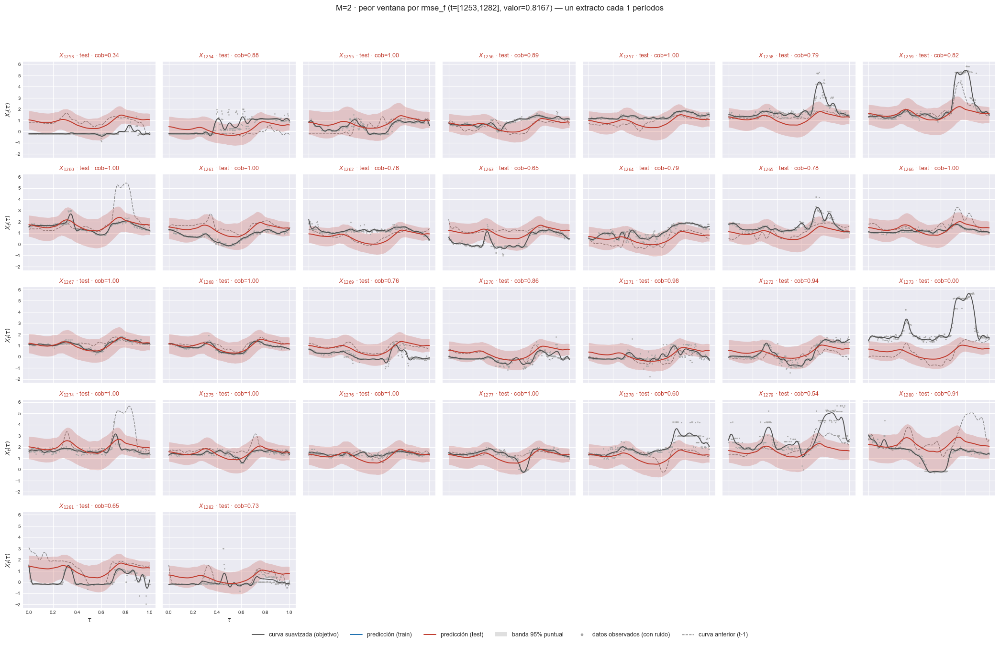

    t=[1252, 1281]  rmse_f=0.812516


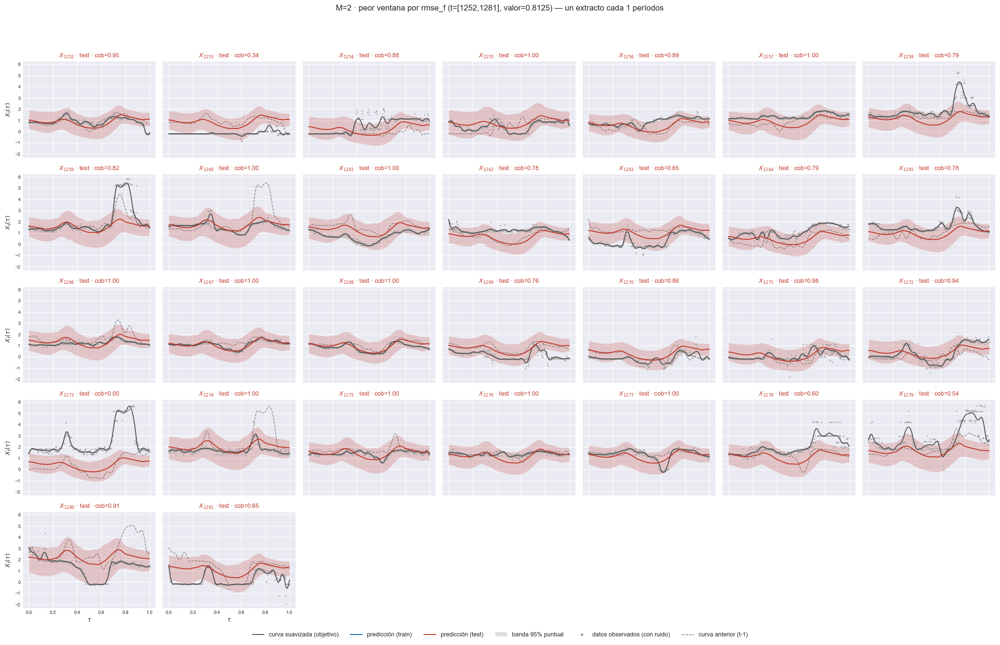

    t=[1258, 1287]  rmse_f=0.806430


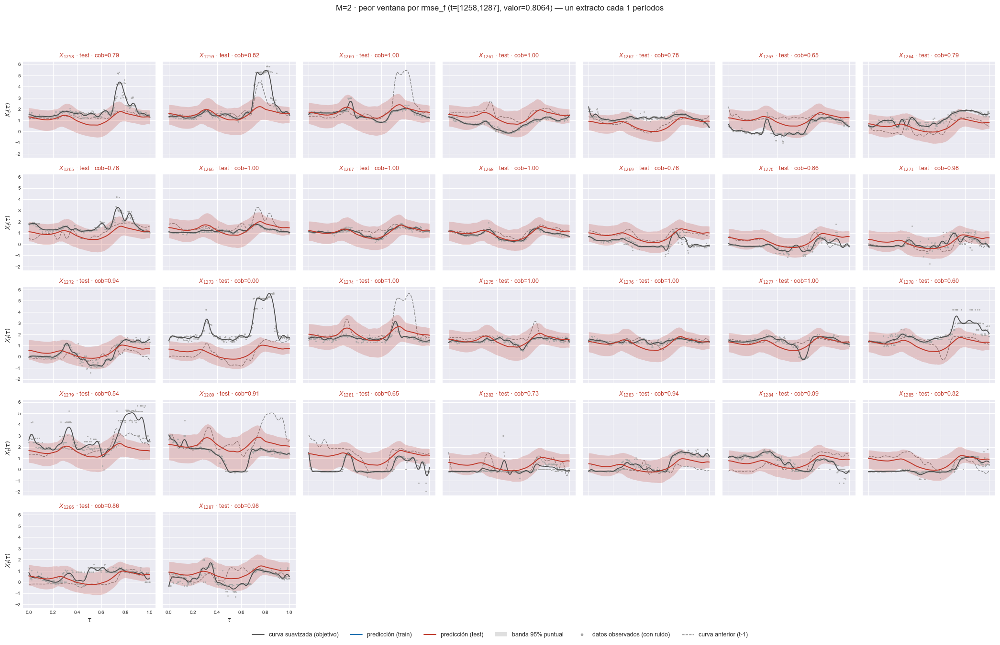

    t=[1257, 1286]  rmse_f=0.805852


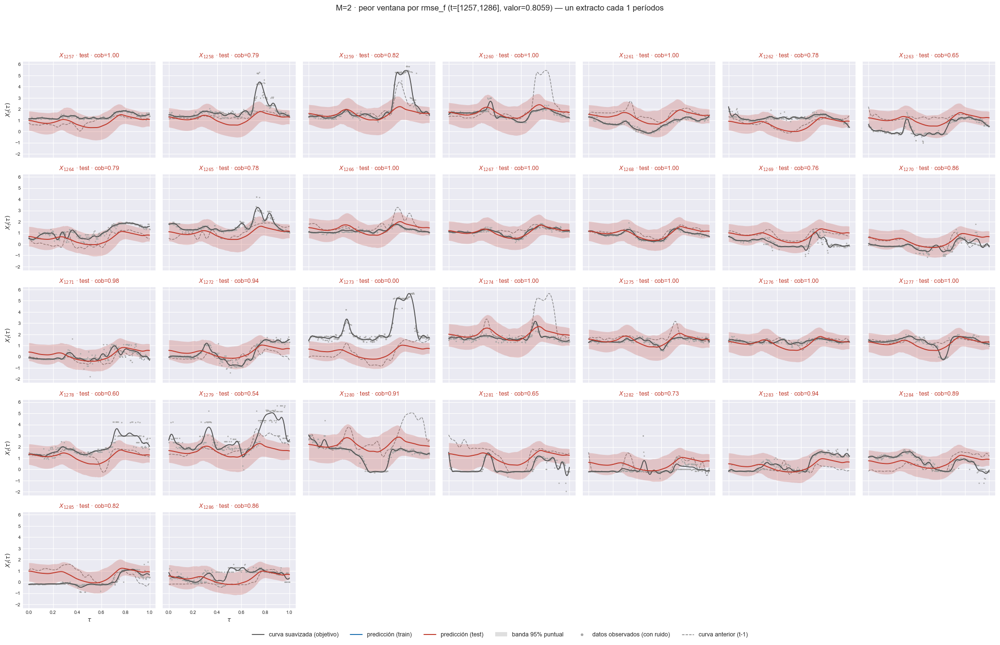

    t=[1256, 1285]  rmse_f=0.803629


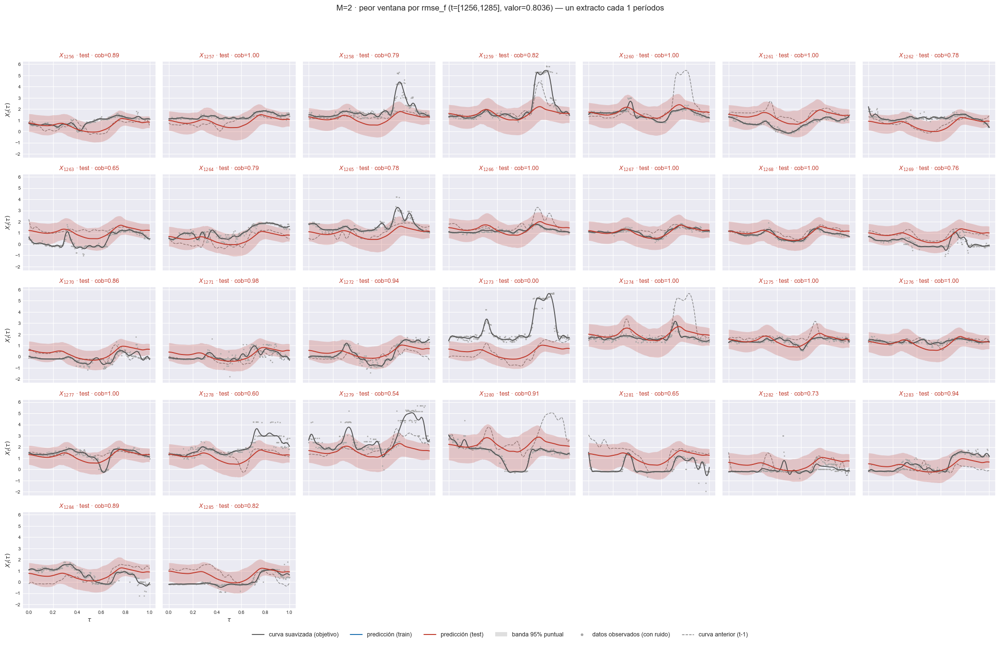

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.778506


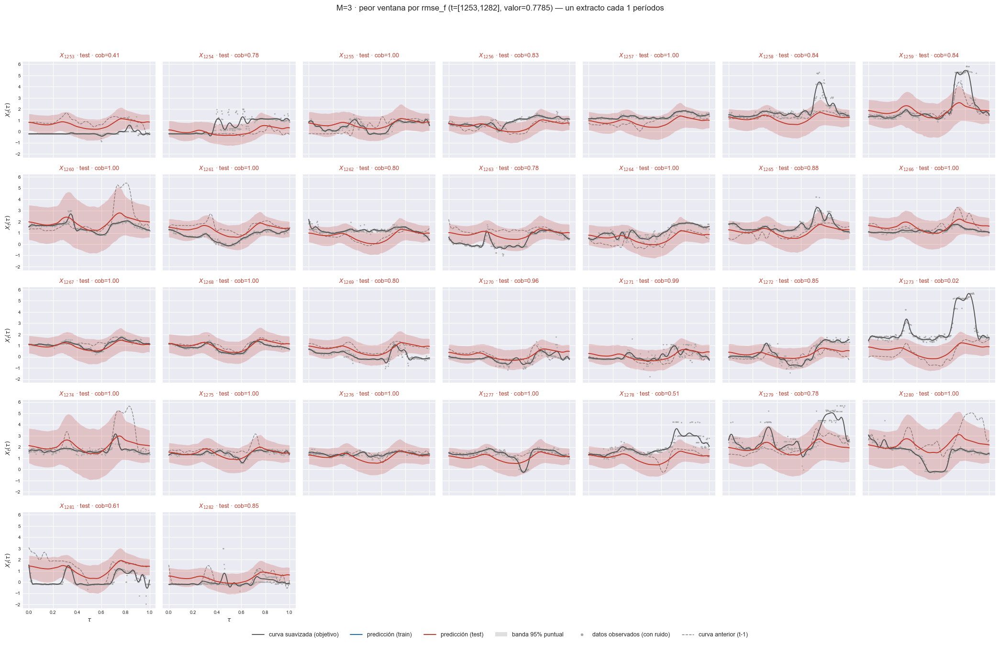

    t=[1252, 1281]  rmse_f=0.775759


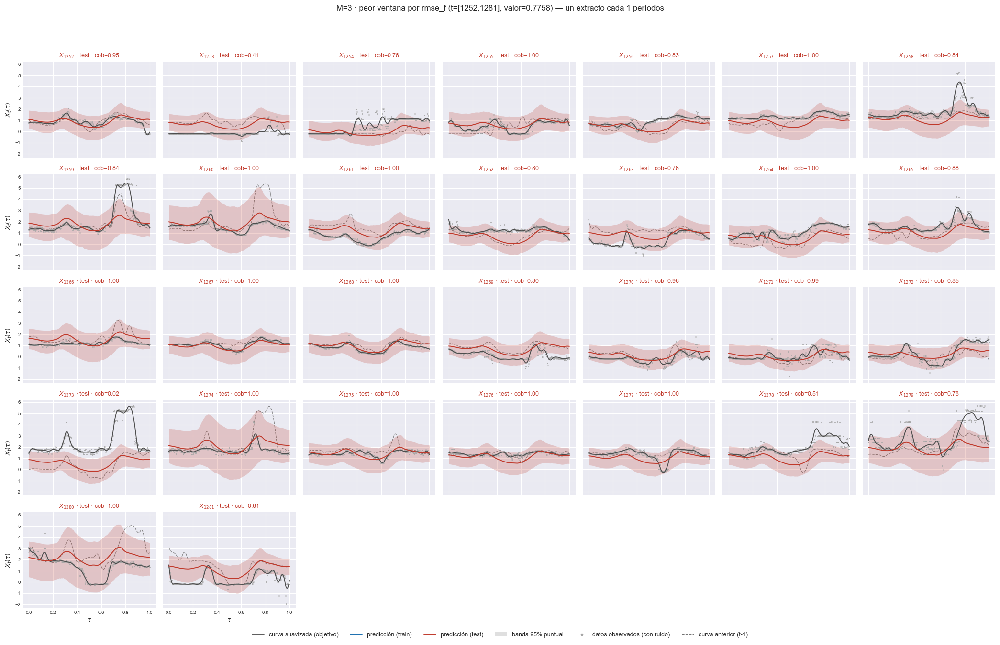

    t=[1254, 1283]  rmse_f=0.771473


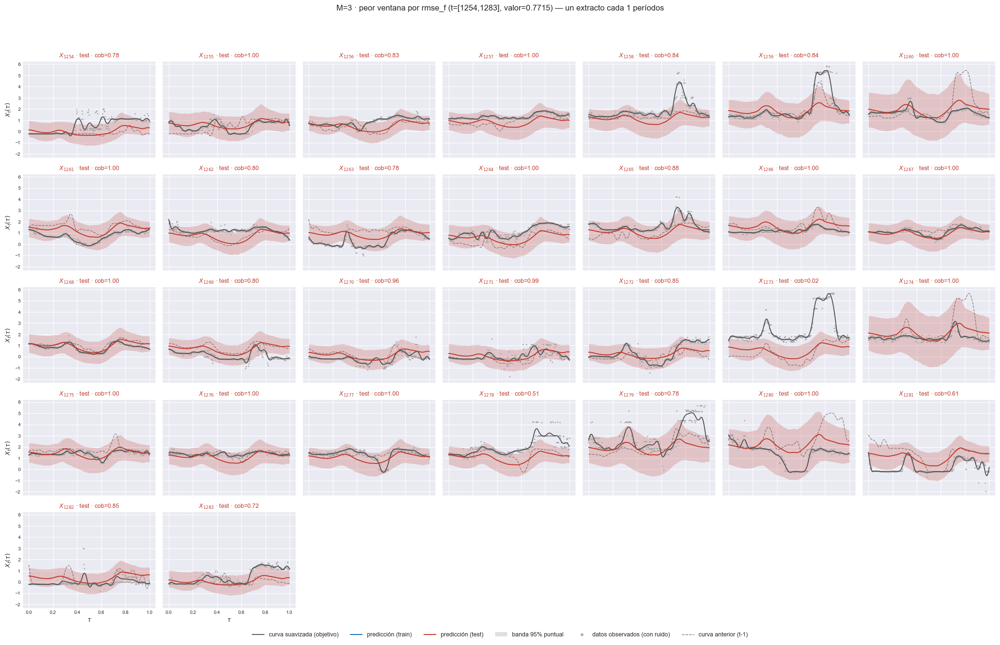

    t=[1257, 1286]  rmse_f=0.770216


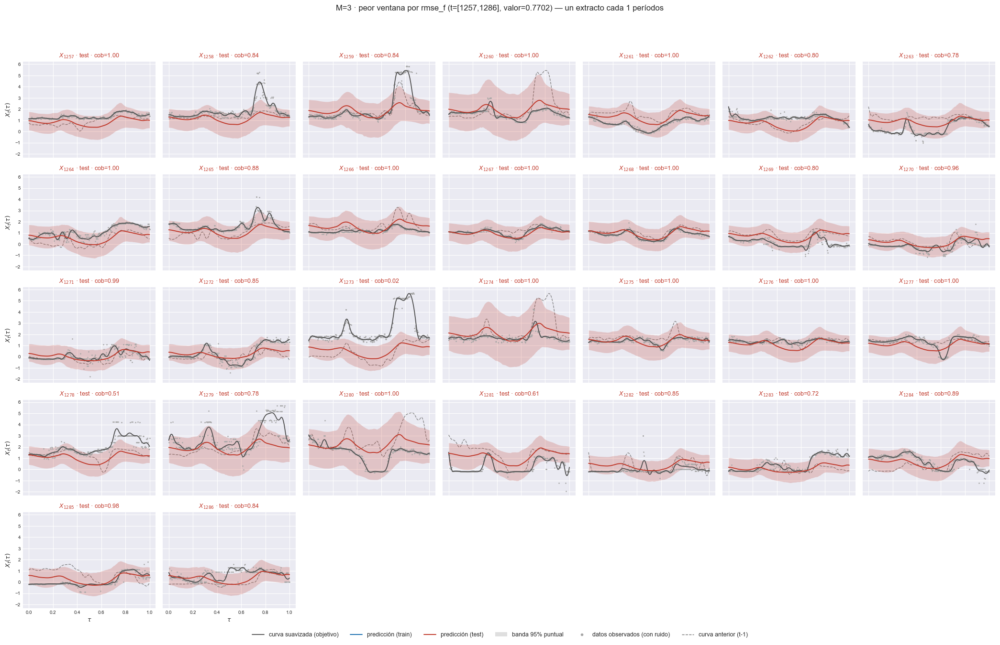

    t=[1256, 1285]  rmse_f=0.768392


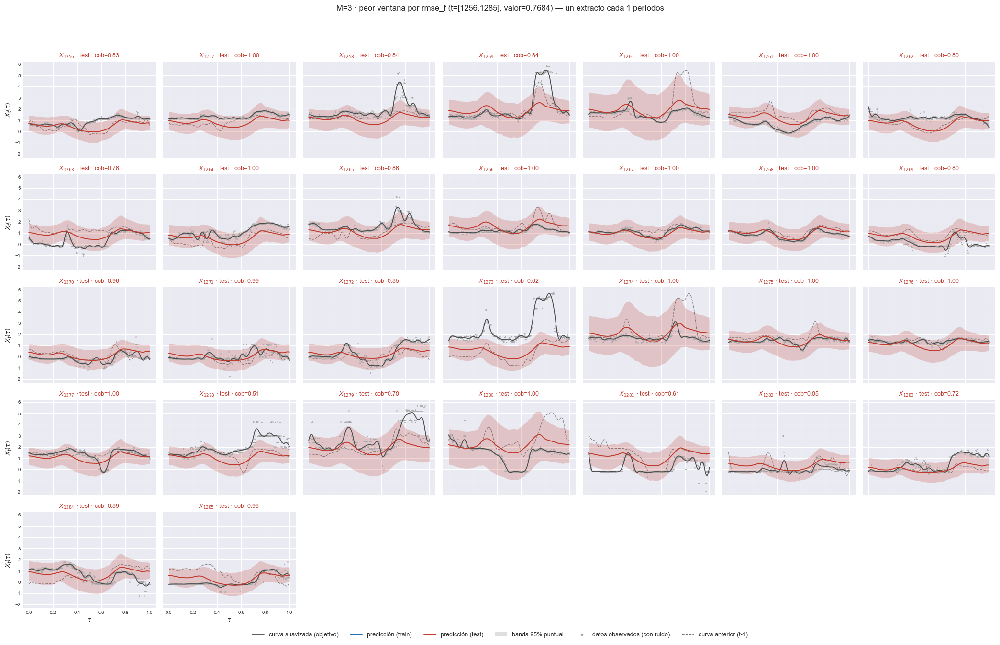

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.766530


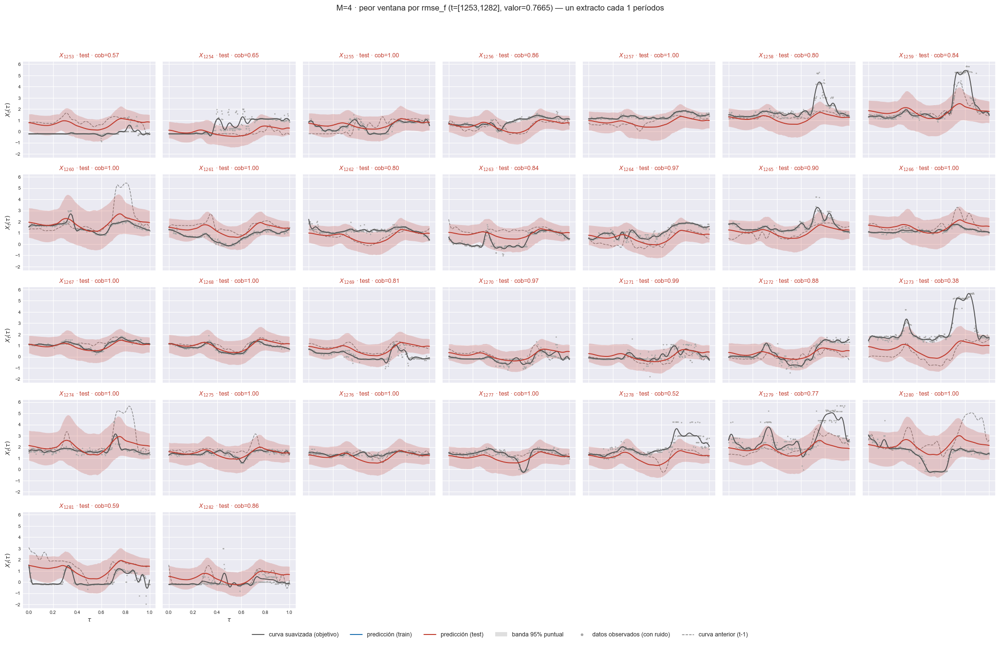

    t=[1252, 1281]  rmse_f=0.762741


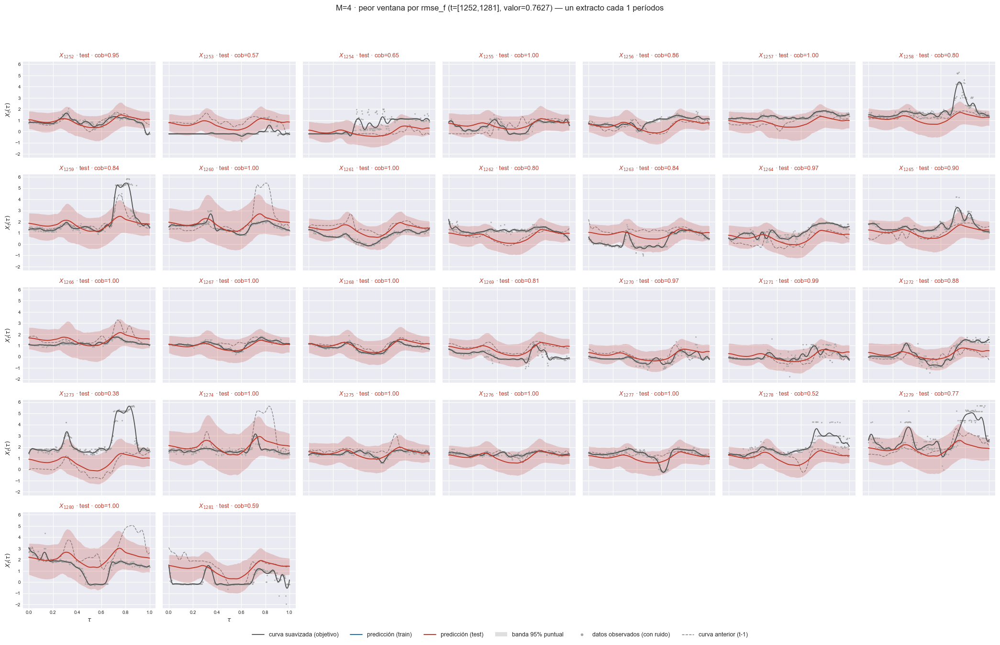

    t=[1254, 1283]  rmse_f=0.759364


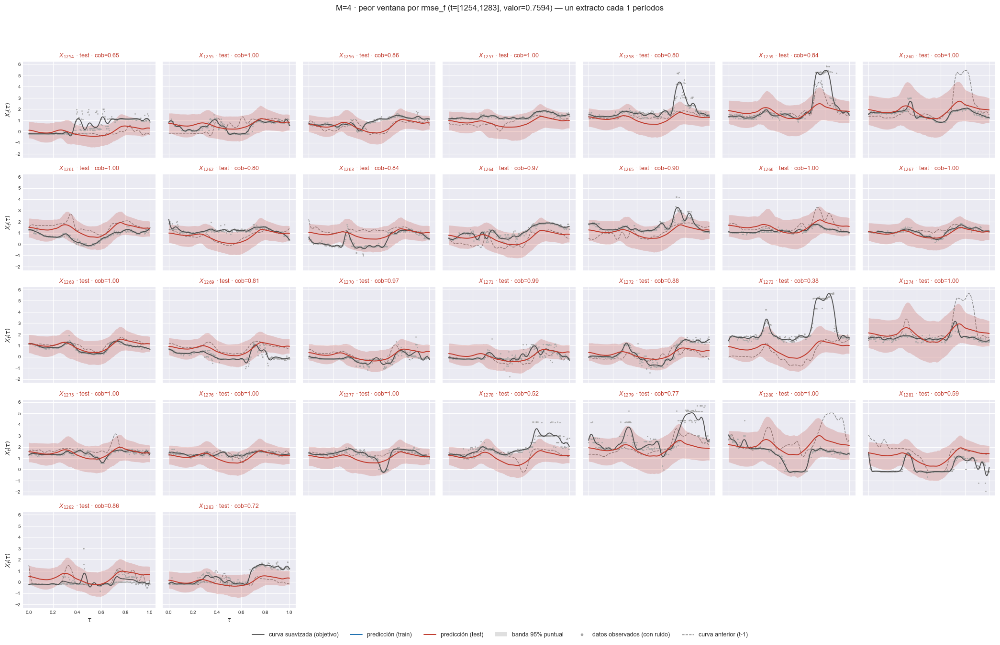

    t=[1257, 1286]  rmse_f=0.756561


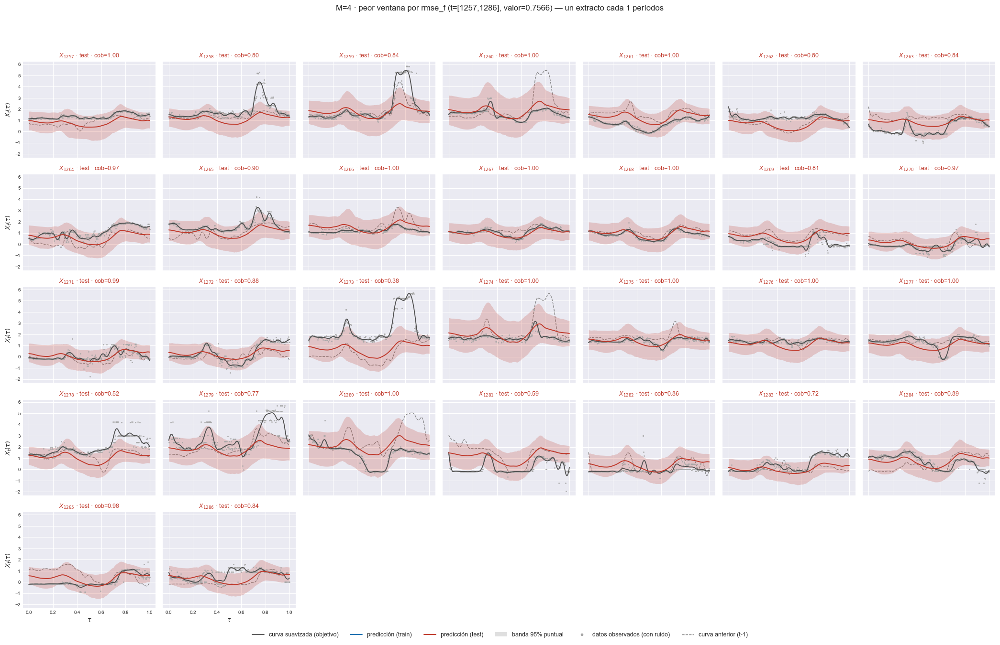

    t=[1256, 1285]  rmse_f=0.755122


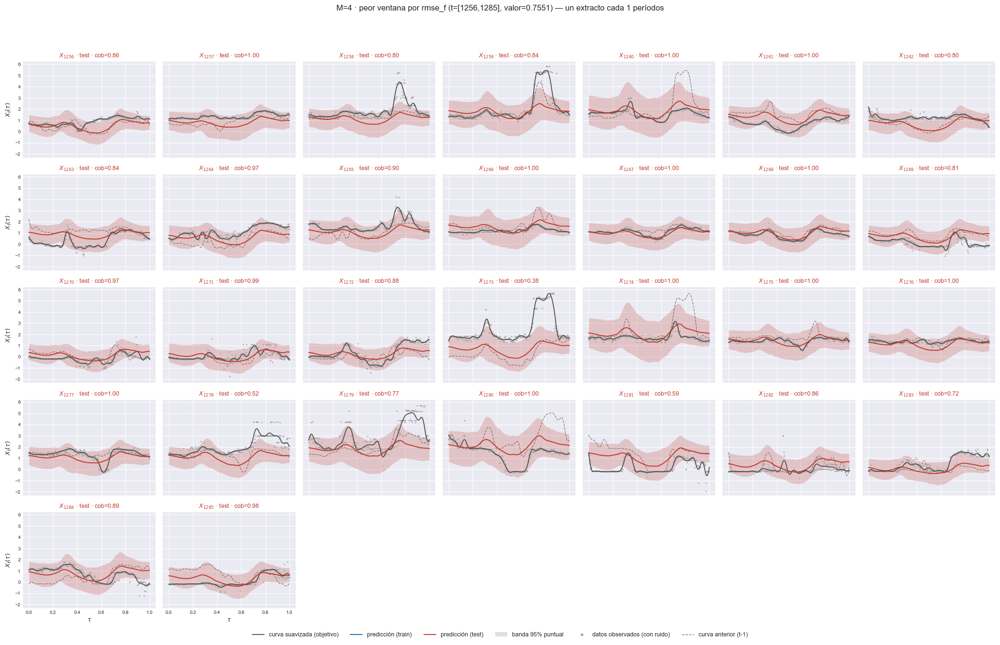

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.745494


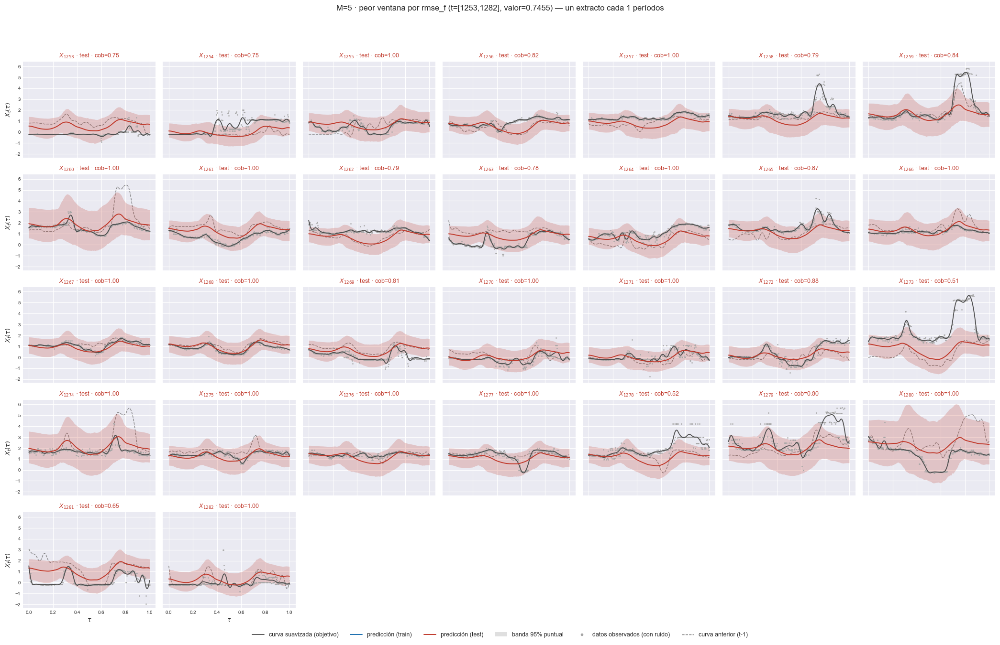

    t=[1252, 1281]  rmse_f=0.742622


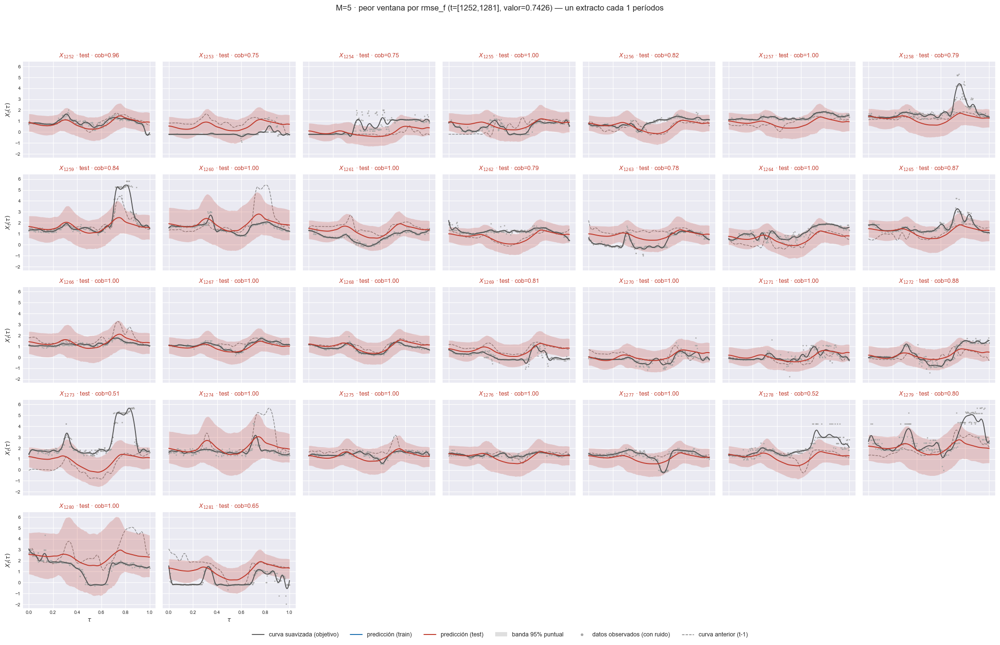

    t=[1254, 1283]  rmse_f=0.741089


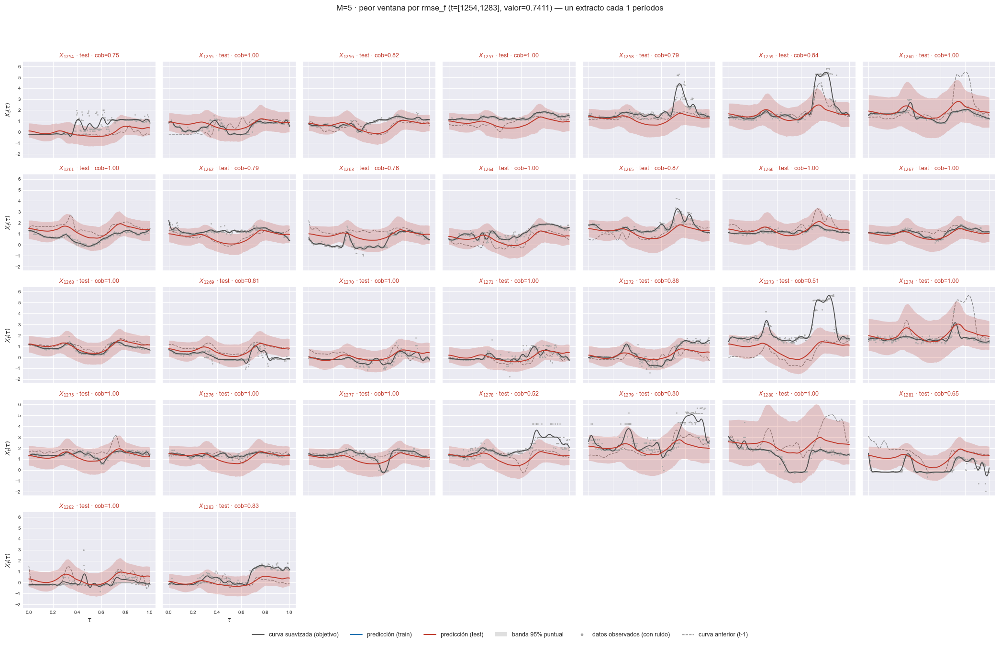

    t=[1257, 1286]  rmse_f=0.737506


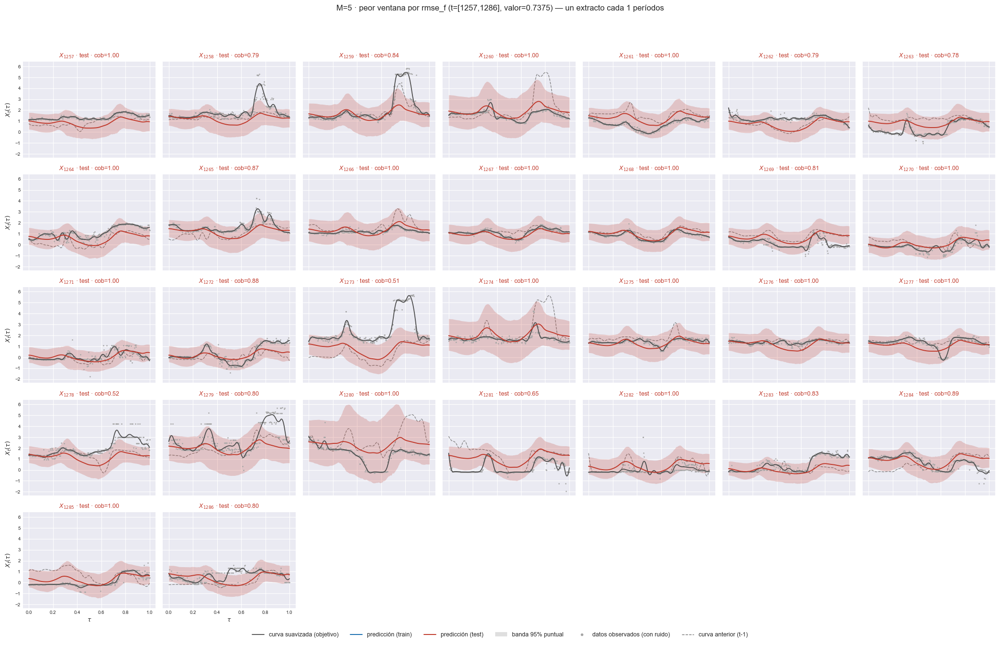

    t=[1255, 1284]  rmse_f=0.734916


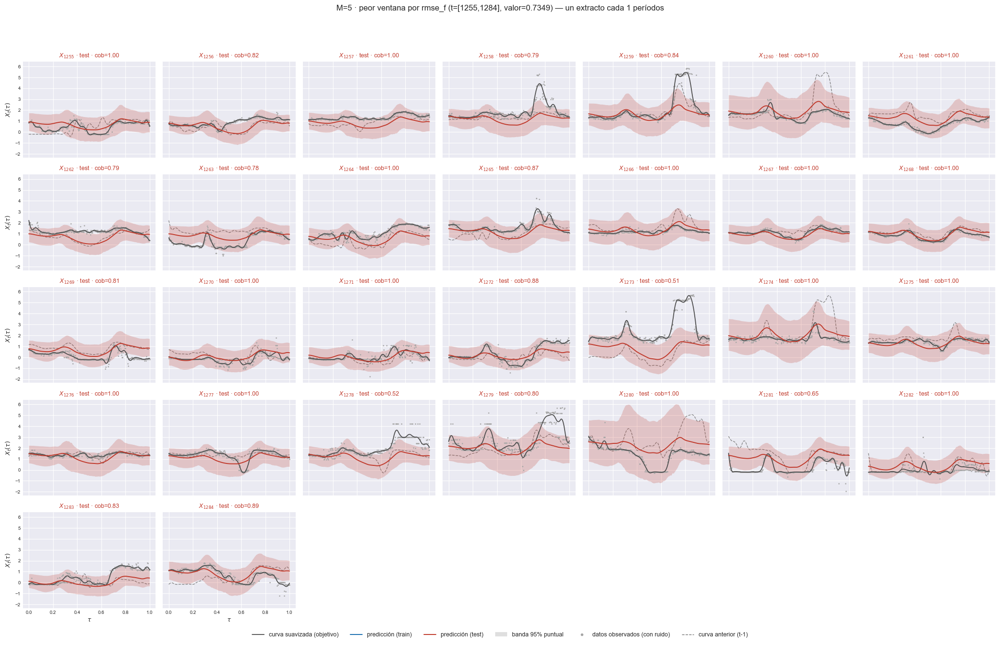

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.747483


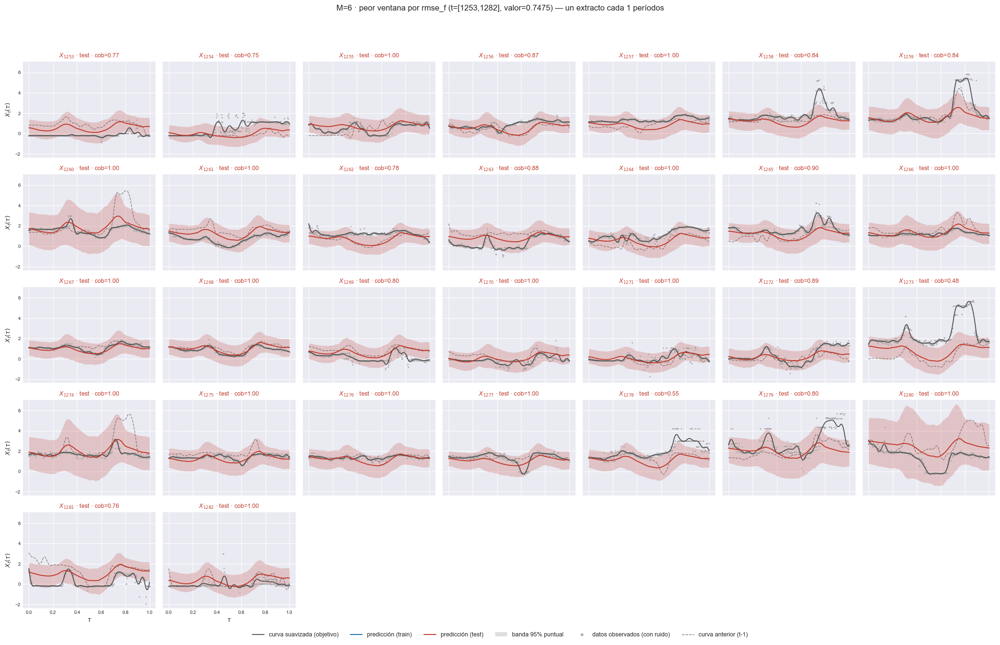

    t=[1252, 1281]  rmse_f=0.744279


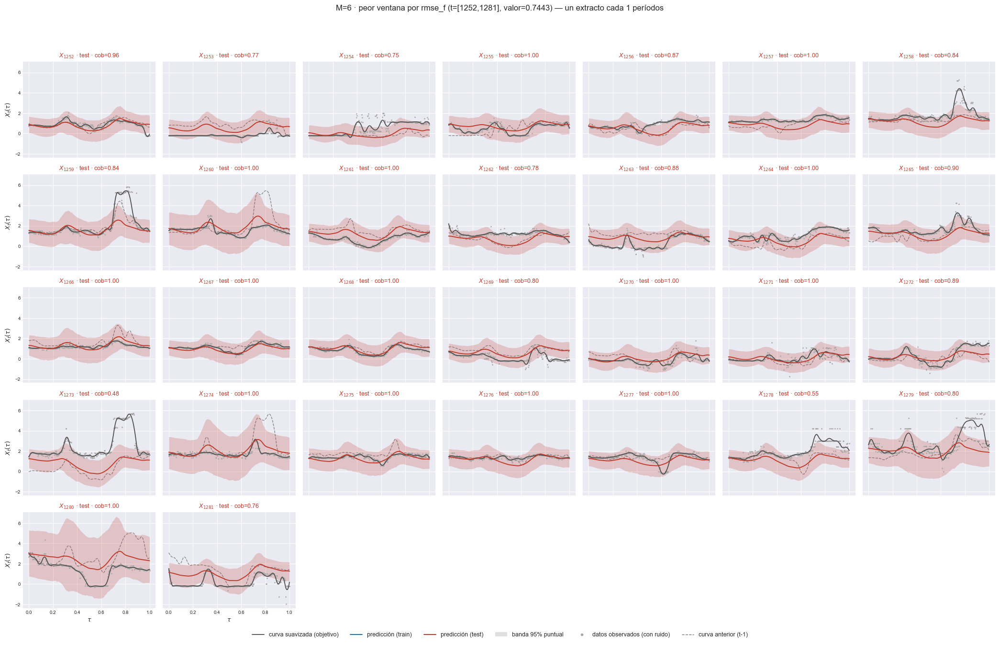

    t=[1254, 1283]  rmse_f=0.742737


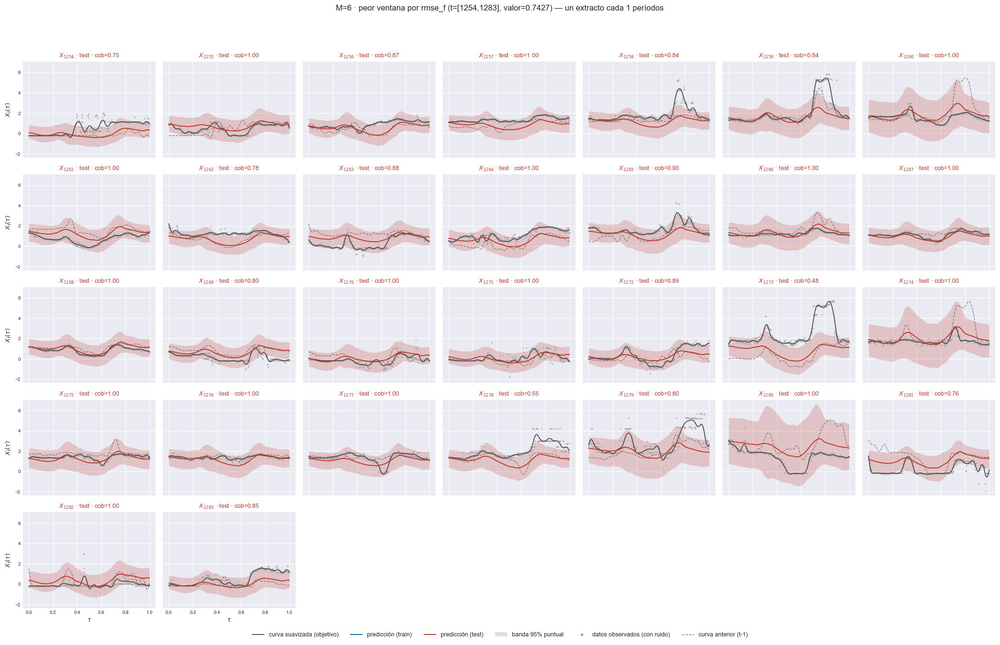

    t=[1257, 1286]  rmse_f=0.739683


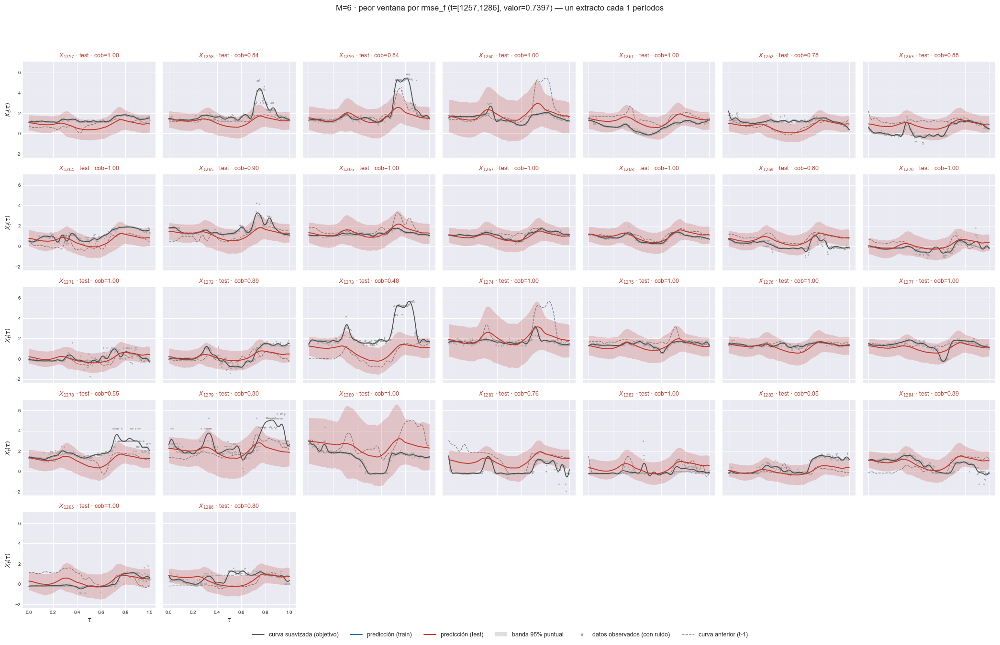

    t=[1258, 1287]  rmse_f=0.737409


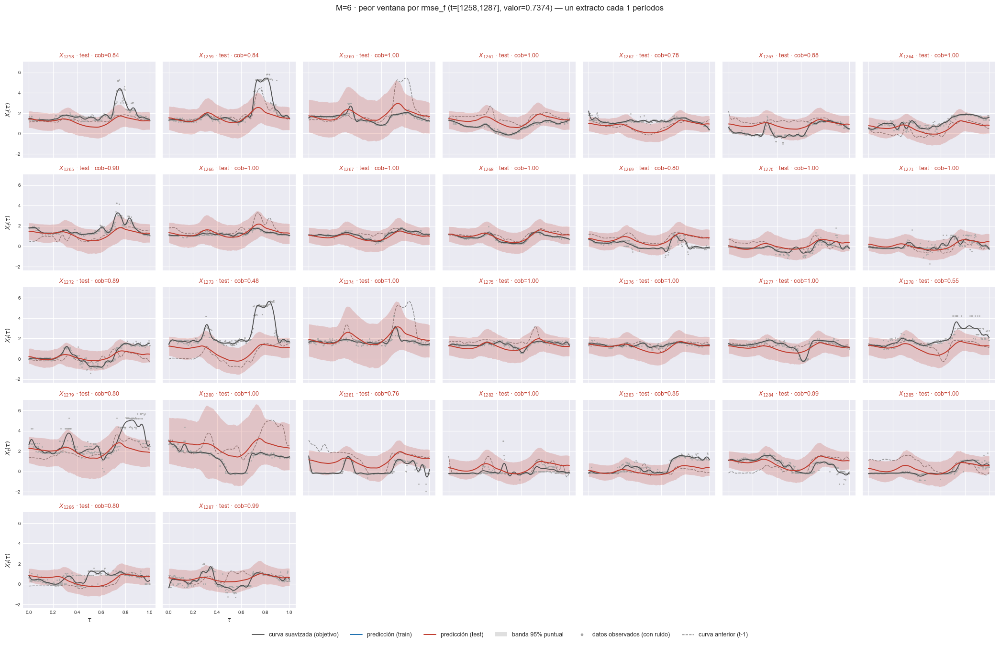

[M=7] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.764186


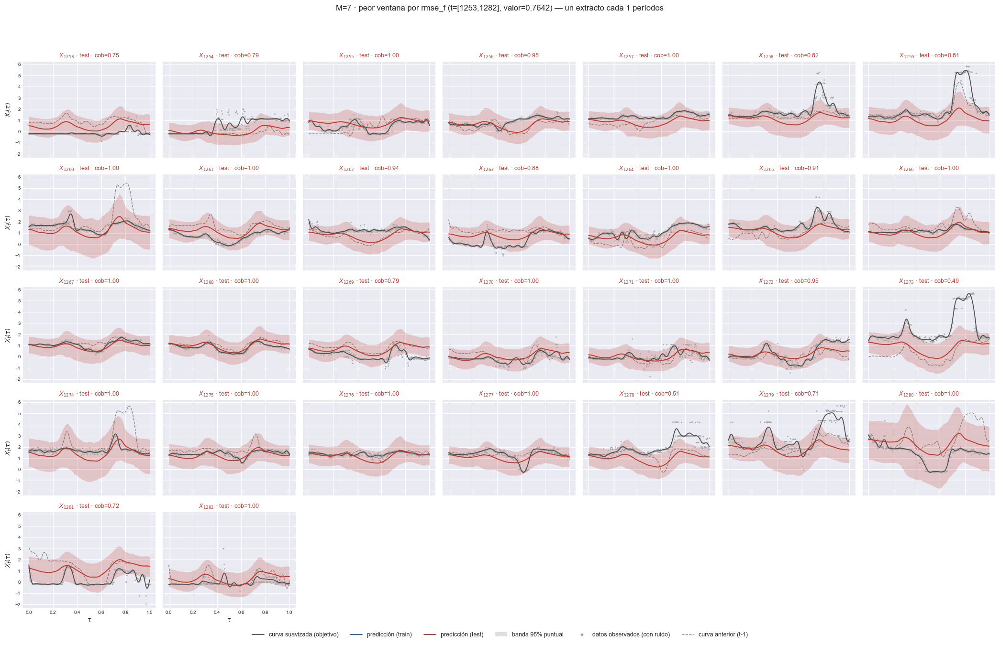

    t=[1252, 1281]  rmse_f=0.762269


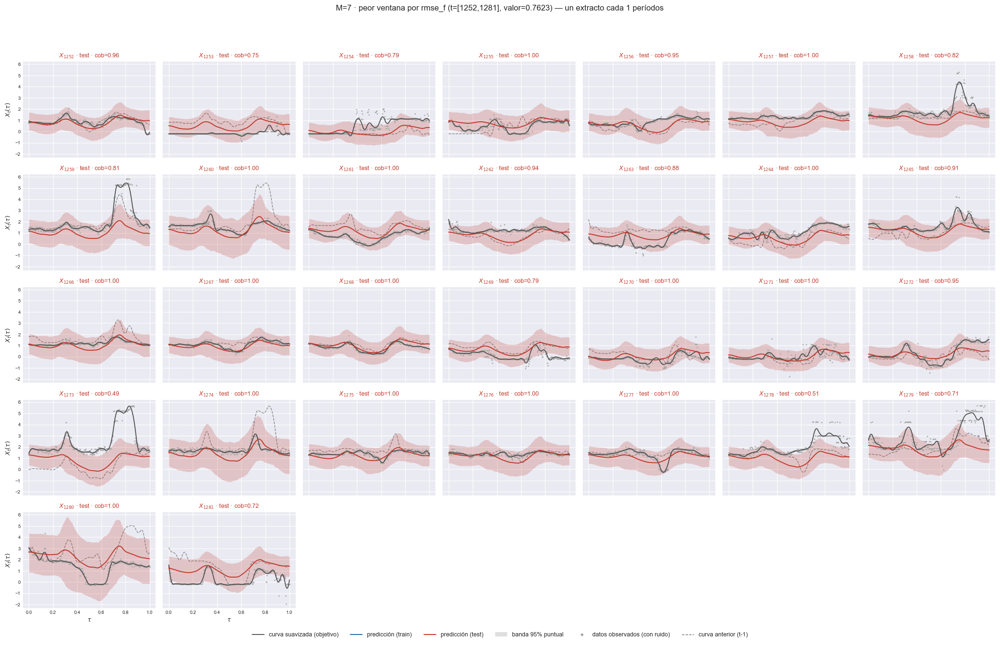

    t=[1254, 1283]  rmse_f=0.760900


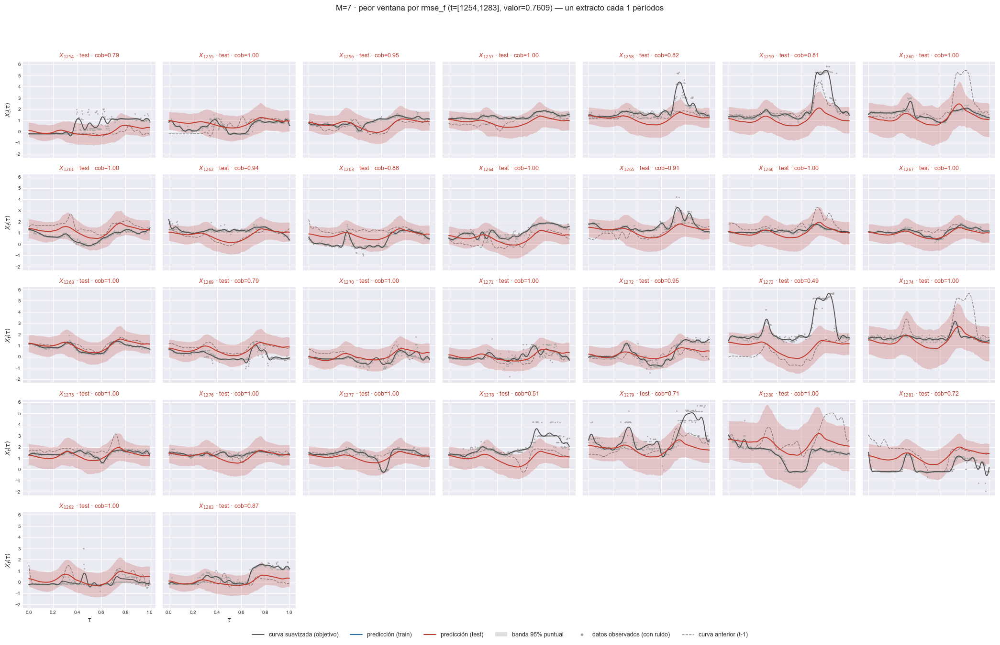

    t=[1257, 1286]  rmse_f=0.758265


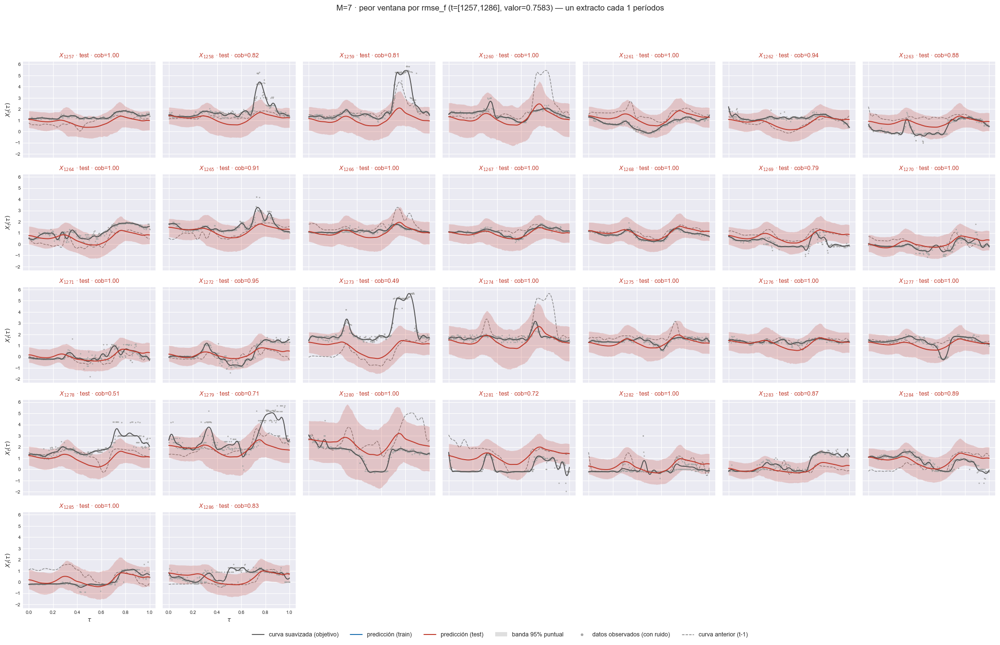

    t=[1258, 1287]  rmse_f=0.756232


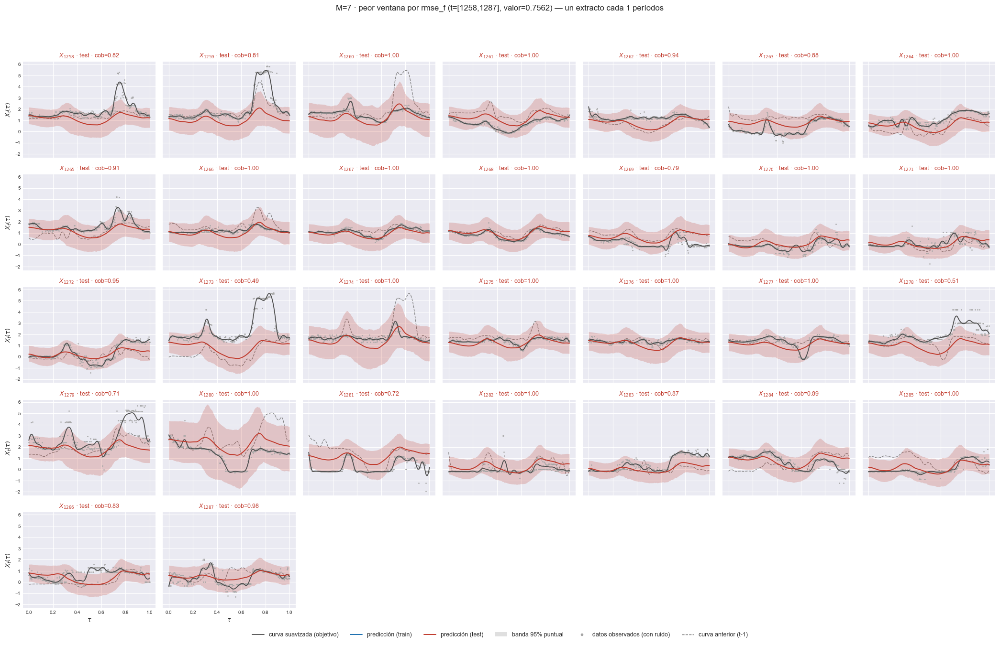

[M=8] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.759540


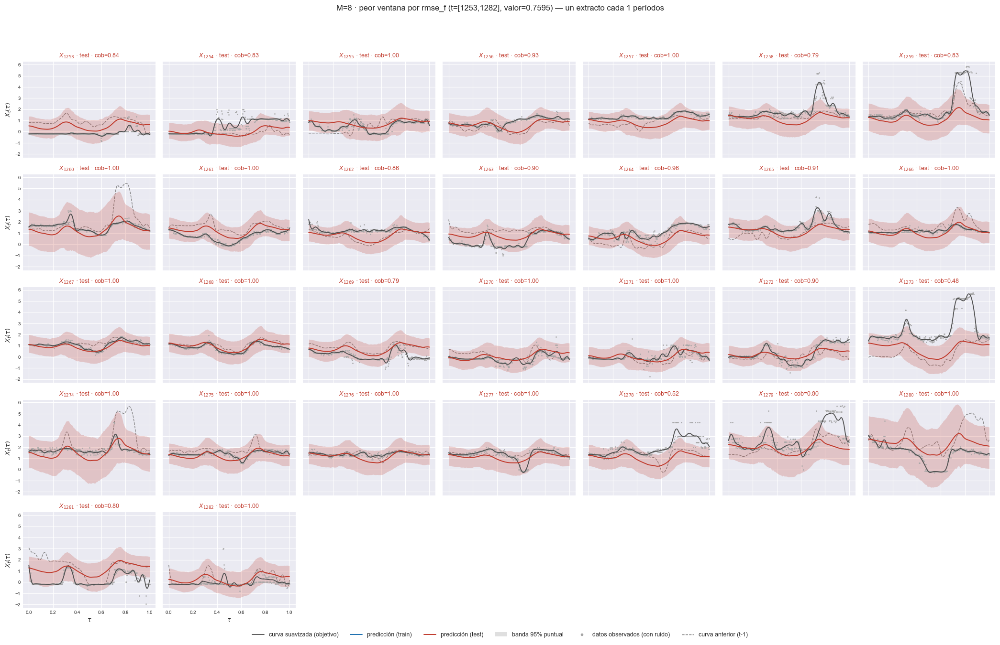

    t=[1252, 1281]  rmse_f=0.757688


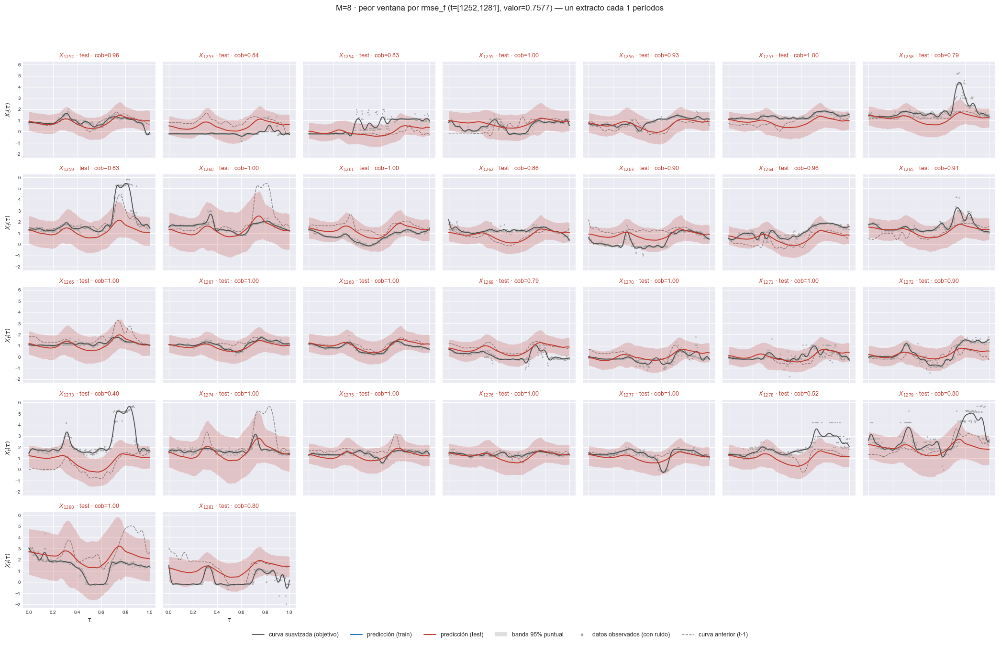

    t=[1254, 1283]  rmse_f=0.757056


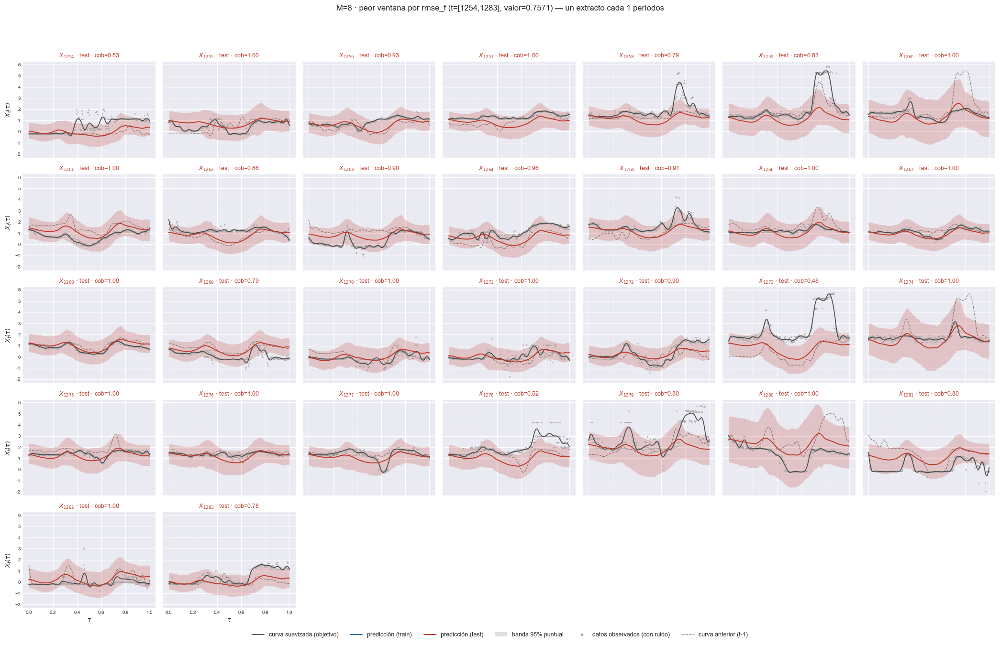

    t=[1257, 1286]  rmse_f=0.754104


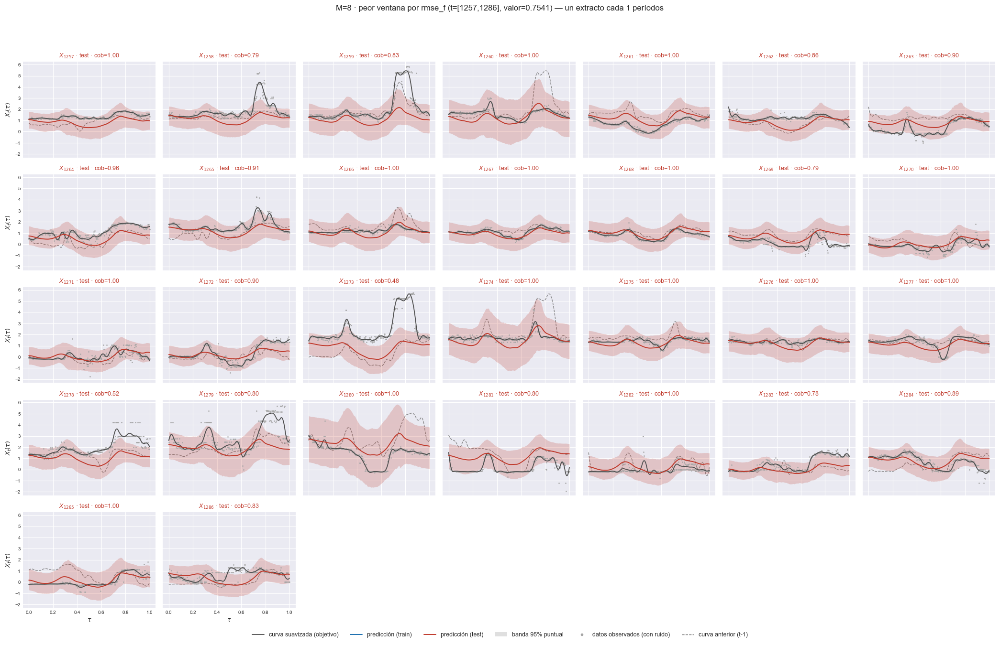

    t=[1255, 1284]  rmse_f=0.751551


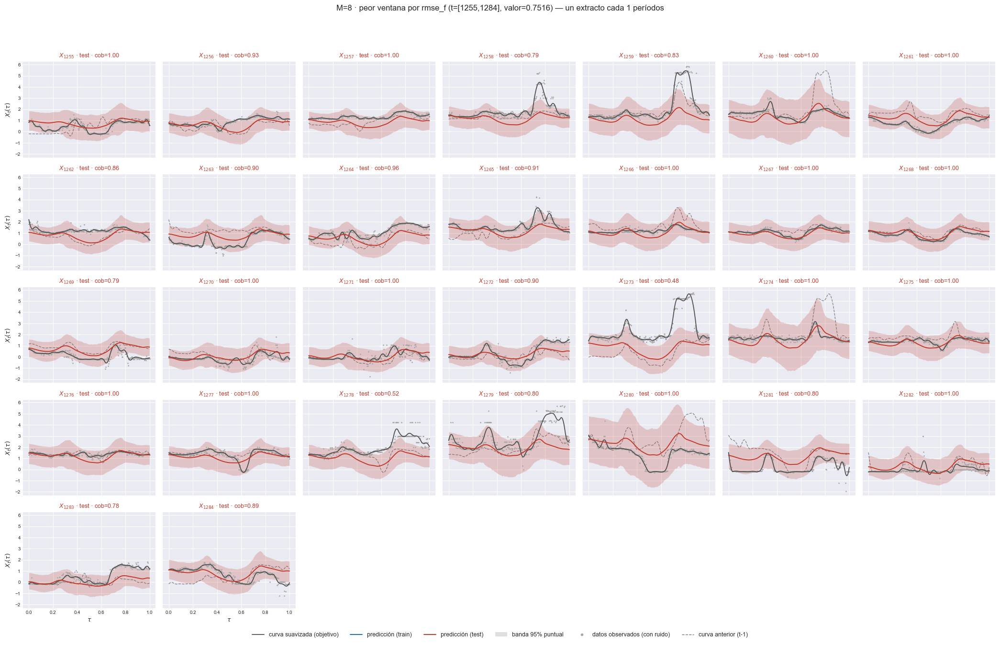

[M=9] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.766510


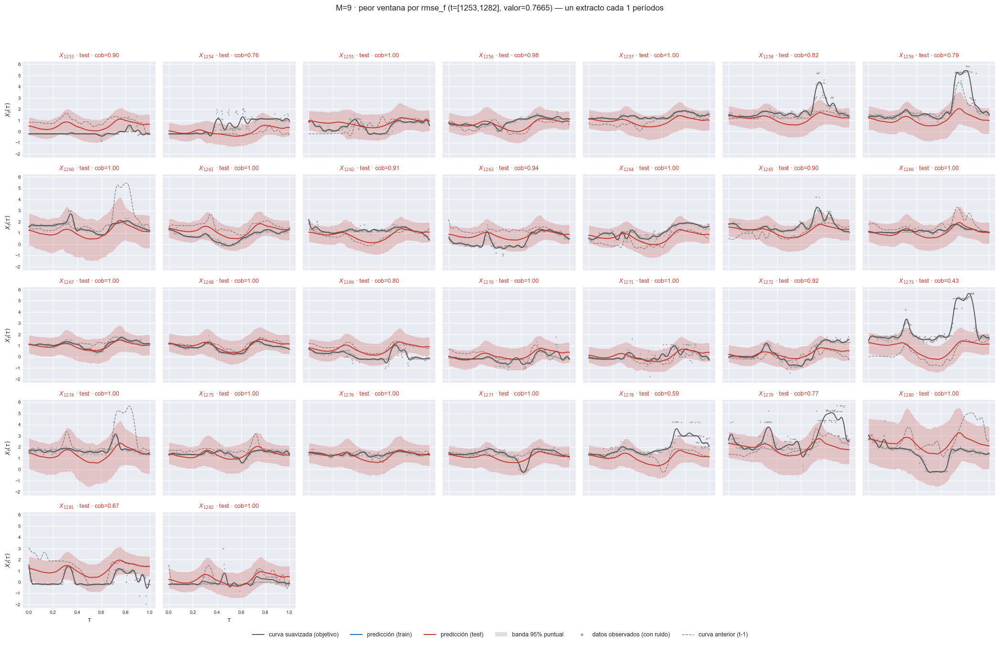

    t=[1252, 1281]  rmse_f=0.765112


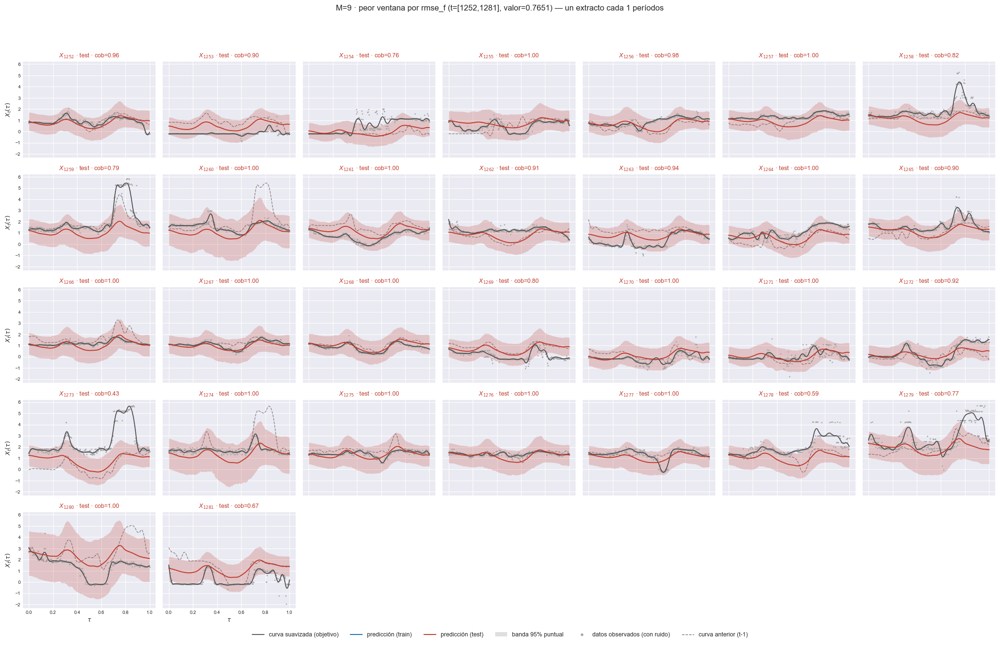

    t=[1254, 1283]  rmse_f=0.763238


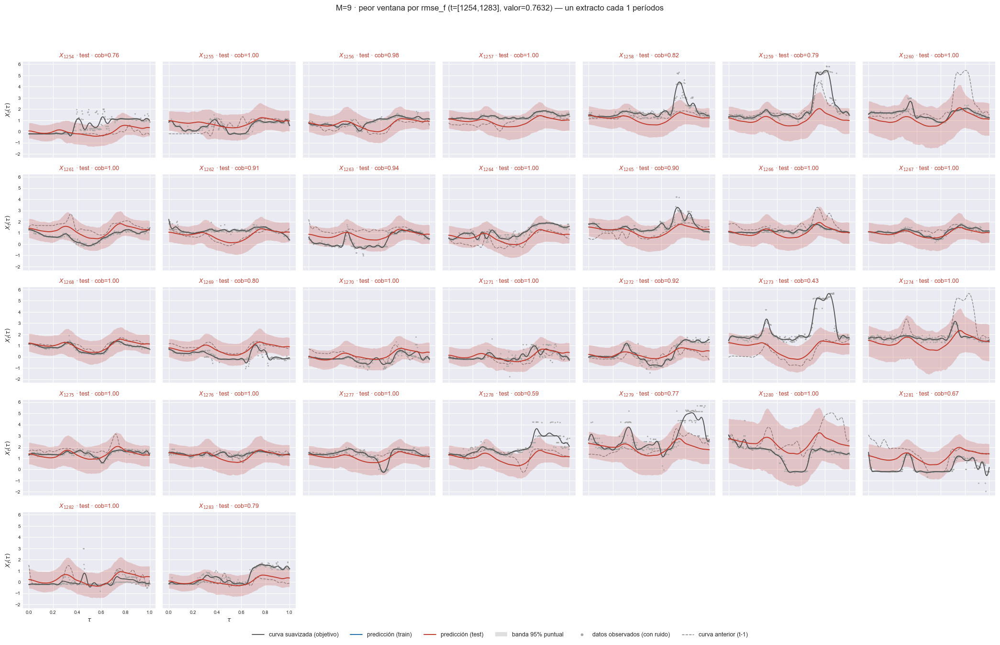

    t=[1257, 1286]  rmse_f=0.761273


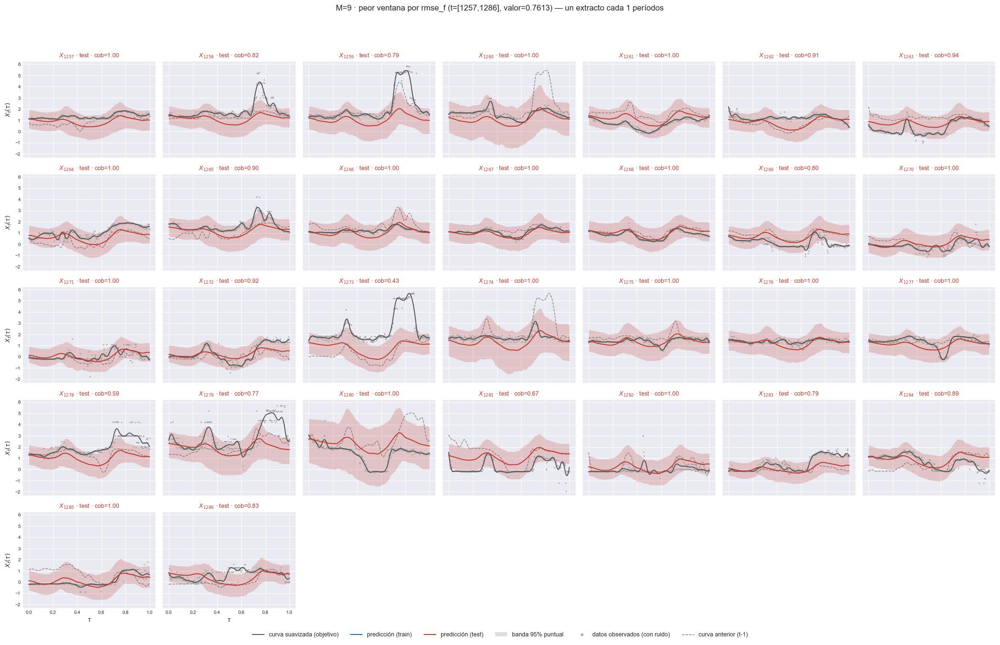

    t=[1258, 1287]  rmse_f=0.759567


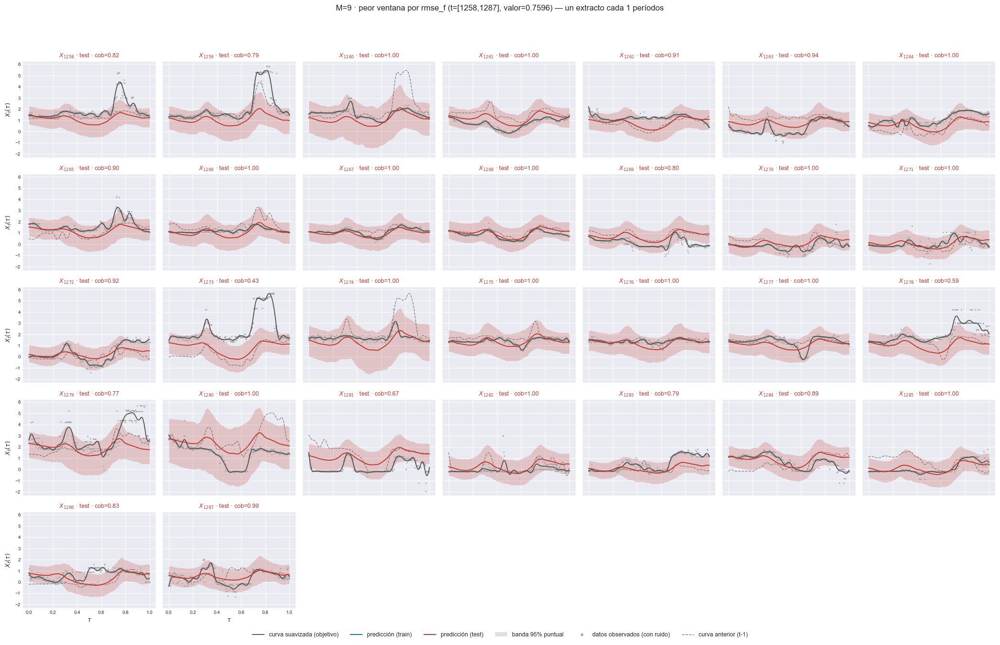

[M=10] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.763702


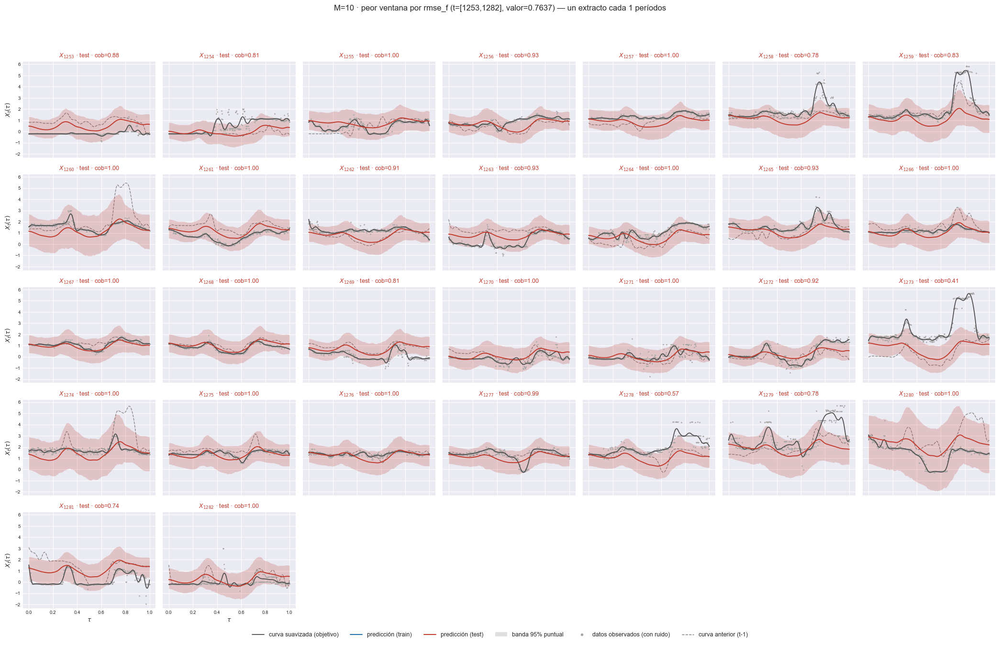

    t=[1252, 1281]  rmse_f=0.762151


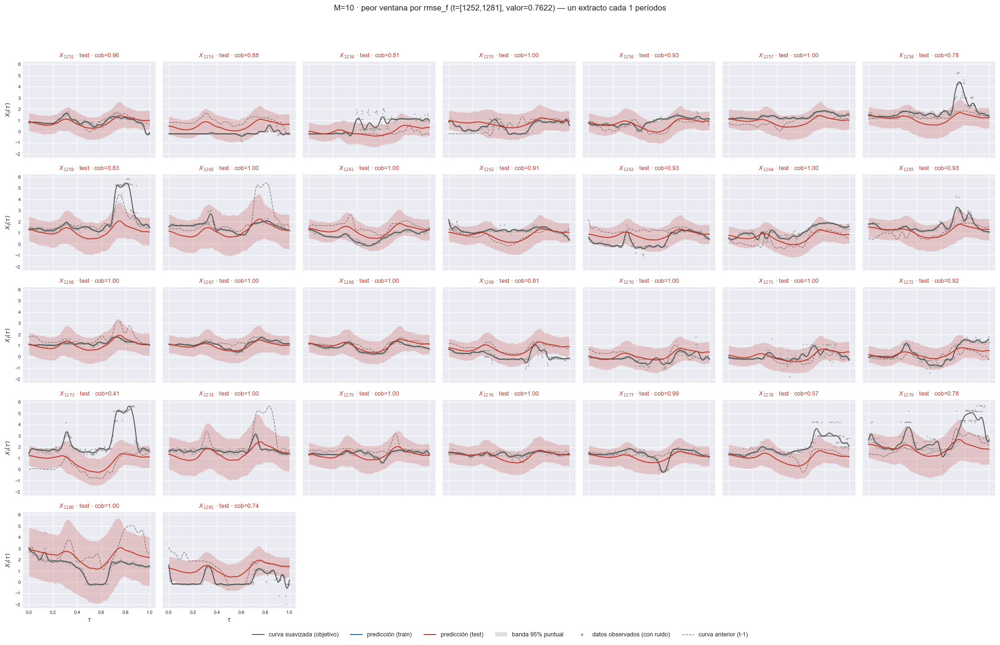

    t=[1254, 1283]  rmse_f=0.760392


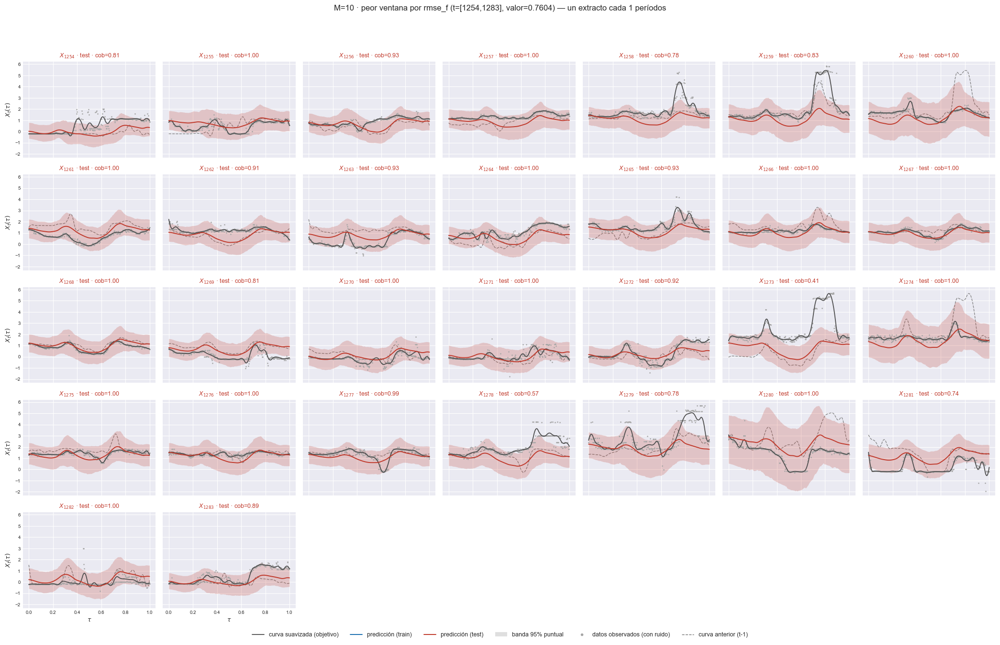

    t=[1257, 1286]  rmse_f=0.758295


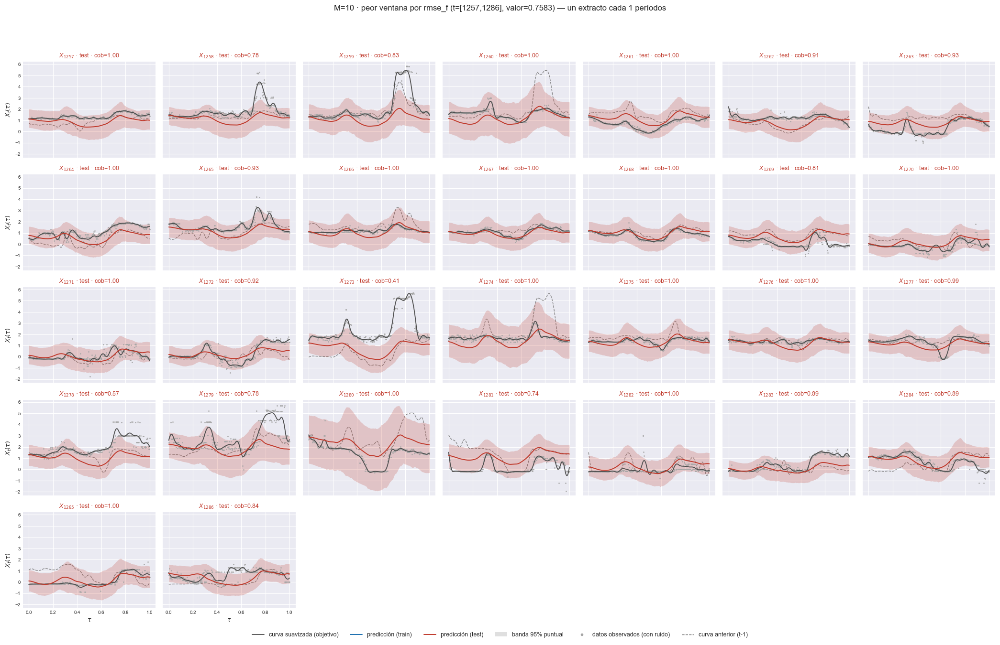

    t=[1258, 1287]  rmse_f=0.756270


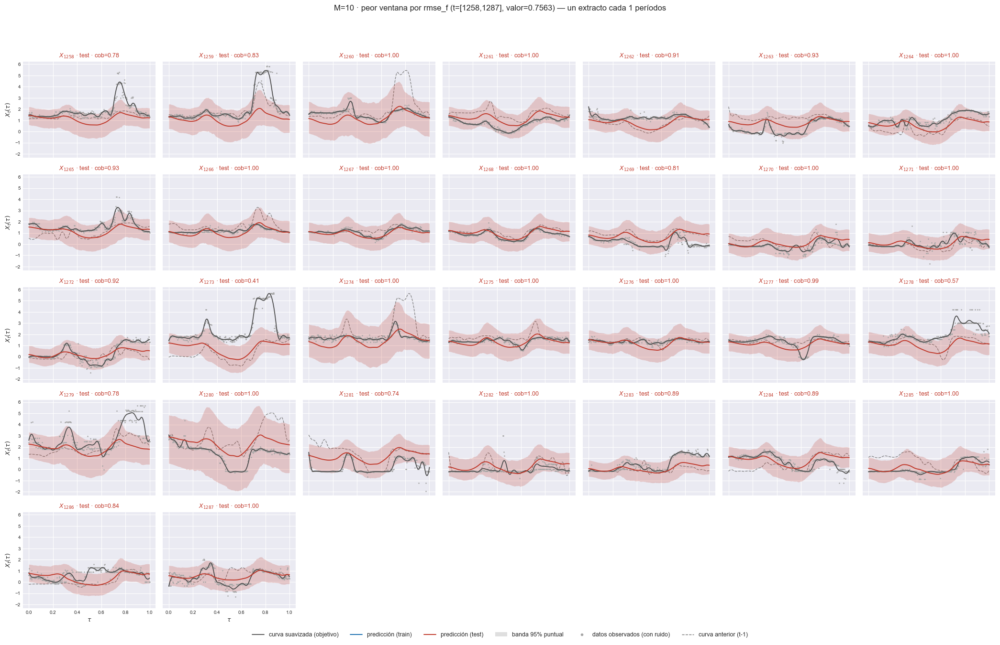

In [12]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

Qué covariables (rezago 1 de cada componente, propia y cruzadas) selecciona el modelo en cada componente. Con datos reales no hay estructura verdadera contra la cual contrastar: se reporta el PIP global y su dispersión entre cadenas.


In [13]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (1 pasos)
  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 1 variables, PIP en [1.000, 1.000]
[matriz_pip] listo: 1 pasos en 0.0s  tabla 1x2
[M=1] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000


[matriz_pip] inicio (2 pasos)
  1/2 (50.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 2 variables, PIP en [1.000, 1.000]
  2/2 (100.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 2 variables, PIP en [1.000, 1.000]
[matriz_pip] listo: 2 pasos en 0.0s  tabla 2x4
[M=2] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd
variable,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000
fpc_2_lag1,1.000,0.000,1.000,0.000


[matriz_pip] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 3 variables, PIP en [0.772, 1.000]
  2/3 (66.7%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 3 variables, PIP en [1.000, 1.000]
  3/3 (100.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 3 variables, PIP en [0.429, 1.000]
[matriz_pip] listo: 3 pasos en 0.0s  tabla 3x6
[M=3] dispersion maxima entre cadenas: 0.495   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd
variable,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,0.429,0.495
fpc_2_lag1,0.772,0.126,1.000,0.000,1.000,0.000
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000


... (10 outputs left out)

[matriz_pip] inicio (9 pasos)
  1/9 (11.1%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 9 variables, PIP en [0.062, 1.000]
  2/9 (22.2%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 9 variables, PIP en [0.130, 1.000]
  3/9 (33.3%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 9 variables, PIP en [0.136, 1.000]
  4/9 (44.4%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 9 variables, PIP en [0.122, 1.000]
  5/9 (55.6%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 9 variables, PIP en [0.142, 1.000]
  6/9 (66.7%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 9 variables, PIP en [0.128, 1.000]
  7/9 (77.8%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 9 variables, PIP en [0.121, 1.000]
  8/9 (88.9%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 9 variables, PIP en [0.101, 1.000]
  9/9 (100.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 9 variables, PIP en [0.114, 1.000]
[matriz_pip] listo: 9 pasos en 0.0s  tabla 9x18
[M=9] dispersion maxima entre cadenas: 0.507   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd
variable,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,0.163,0.013,0.440,0.486,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.580,0.361
fpc_2_lag1,0.953,0.079,1.000,0.000,1.000,0.000,0.615,0.367,0.992,0.014,0.573,0.211,0.151,0.032,0.117,0.019,0.131,0.020
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.989,0.018,0.189,0.019,0.131,0.018,0.731,0.363,0.117,0.048
fpc_4_lag1,0.899,0.139,0.521,0.466,0.339,0.148,1.000,0.000,0.142,0.047,0.155,0.041,0.121,0.015,0.707,0.507,0.570,0.231
fpc_5_lag1,1.000,0.000,1.000,0.000,0.192,0.041,1.000,0.000,1.000,0.000,0.698,0.282,0.130,0.029,0.329,0.237,0.574,0.265
fpc_6_lag1,0.062,0.011,1.000,0.000,0.136,0.033,1.000,0.000,0.236,0.093,1.000,0.000,0.316,0.323,0.350,0.139,0.114,0.023
fpc_7_lag1,1.000,0.000,0.214,0.126,0.240,0.095,0.268,0.149,0.978,0.038,0.159,0.034,1.000,0.000,0.150,0.058,0.153,0.021
fpc_8_lag1,0.079,0.012,0.130,0.061,0.239,0.055,0.933,0.115,0.191,0.056,0.169,0.044,0.121,0.010,0.120,0.035,0.146,0.042
fpc_9_lag1,0.982,0.031,0.301,0.081,0.139,0.011,0.122,0.044,1.000,0.000,0.128,0.028,0.170,0.030,0.101,0.027,1.000,0.000


[matriz_pip] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 10 variables, PIP en [0.130, 1.000]
  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 10 variables, PIP en [0.192, 1.000]
  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 10 variables, PIP en [0.164, 1.000]
  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 10 variables, PIP en [0.149, 1.000]
  5/10 (50.0%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 10 variables, PIP en [0.146, 1.000]
  6/10 (60.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 10 variables, PIP en [0.144, 1.000]
  7/10 (70.0%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 10 variables, PIP en [0.141, 1.000]
  8/10 (80.0%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 10 variables, PIP en [0.121, 1.000]
  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 10 variables, PIP en [0.178, 1.000]
  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 3 cadenas, 10 variables, PIP en [0.112, 1.000]
[matriz_pip] listo: 10 pasos en 0.0s  tabla 10x20
[M=10] dispersion maxima entre cadenas: 0.462   ! las ca

,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,0.376,0.340,0.149,0.022,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.757,0.421,0.338,0.317
fpc_2_lag1,0.892,0.109,1.000,0.000,1.000,0.000,0.723,0.309,0.991,0.014,0.481,0.112,0.157,0.018,0.126,0.026,0.191,0.083,0.129,0.015
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.337,0.202,0.141,0.015,0.963,0.064,0.210,0.047,0.257,0.225
fpc_4_lag1,0.721,0.367,0.654,0.303,0.272,0.081,1.000,0.000,0.157,0.060,0.175,0.035,0.148,0.022,0.154,0.062,0.635,0.349,0.436,0.105
fpc_5_lag1,1.000,0.000,1.000,0.000,0.214,0.057,1.000,0.000,1.000,0.000,0.733,0.462,0.250,0.158,0.131,0.016,0.739,0.254,0.187,0.039
fpc_6_lag1,0.136,0.079,1.000,0.000,0.172,0.024,1.000,0.000,0.205,0.091,1.000,0.000,0.742,0.323,0.379,0.232,0.178,0.049,0.121,0.016
fpc_7_lag1,1.000,0.000,0.192,0.051,0.219,0.065,0.476,0.264,0.835,0.210,0.144,0.009,1.000,0.000,0.131,0.057,0.179,0.034,0.116,0.036
fpc_8_lag1,0.130,0.059,0.235,0.110,0.265,0.126,0.920,0.132,0.148,0.032,0.167,0.030,0.146,0.018,0.216,0.108,0.185,0.089,0.130,0.021
fpc_9_lag1,0.918,0.135,0.639,0.126,0.164,0.032,0.150,0.020,1.000,0.000,0.144,0.024,0.172,0.040,0.121,0.033,1.000,0.000,0.112,0.020


## 8. Cuadro resumen: mínimo, máximo y promedio

La ventana móvil genera una SERIE por métrica, no una cifra. Esta tabla es la
lectura resumida de esa serie: mínimo, máximo y promedio, por bloque
train/test, excluyendo las ventanas que cruzan $T_0$ -su cifra mezcla dentro y
fuera de muestra-. Cubre las 7 métricas de los Bloques A y B; ninguna se
destaca sobre las demás.

In [14]:
# Los dos objetivos en la misma tabla, con la columna que declara cuál.
for M in M_OK:
    resumen = resumen_metricas(EST[M], M, DIS, ORIG)
    display(resumen.style.format({"minimo": "{:.6f}", "maximo": "{:.6f}", "promedio": "{:.6f}"})
            .set_caption(f"M={M} · mínimo / máximo / promedio por ventana "
                         f"(w={W_REF}, sin cruzar T0) · nivel funcional"))

resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)
# Vista rápida: un solo objetivo (el primario del Bloque A); el CSV tiene los dos.
display(resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")]
        .pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=1] curva_suavizada      PICP puntual test = 0.8236 (nominal 0.95)  ·  PICP simultaneo test = 0.2103
[M=1] representacion_fpca  PICP puntual test = 0.9605 (nominal 0.95)  ·  PICP simultaneo test = 0.9605


[M=2] curva_suavizada      PICP puntual test = 0.8969 (nominal 0.95)  ·  PICP simultaneo test = 0.3260
[M=2] representacion_fpca  PICP puntual test = 0.9693 (nominal 0.95)  ·  PICP simultaneo test = 0.9117


[M=3] curva_suavizada      PICP puntual test = 0.9195 (nominal 0.95)  ·  PICP simultaneo test = 0.4081
[M=3] representacion_fpca  PICP puntual test = 0.9536 (nominal 0.95)  ·  PICP simultaneo test = 0.8369


[M=4] curva_suavizada      PICP puntual test = 0.9280 (nominal 0.95)  ·  PICP simultaneo test = 0.4471
[M=4] representacion_fpca  PICP puntual test = 0.9516 (nominal 0.95)  ·  PICP simultaneo test = 0.7996


[M=5] curva_suavizada      PICP puntual test = 0.9390 (nominal 0.95)  ·  PICP simultaneo test = 0.5281
[M=5] representacion_fpca  PICP puntual test = 0.9522 (nominal 0.95)  ·  PICP simultaneo test = 0.7684


[M=6] curva_suavizada      PICP puntual test = 0.9419 (nominal 0.95)  ·  PICP simultaneo test = 0.5328
[M=6] representacion_fpca  PICP puntual test = 0.9560 (nominal 0.95)  ·  PICP simultaneo test = 0.7596


[M=7] curva_suavizada      PICP puntual test = 0.9453 (nominal 0.95)  ·  PICP simultaneo test = 0.5444
[M=7] representacion_fpca  PICP puntual test = 0.9557 (nominal 0.95)  ·  PICP simultaneo test = 0.7386


[M=8] curva_suavizada      PICP puntual test = 0.9468 (nominal 0.95)  ·  PICP simultaneo test = 0.5467
[M=8] representacion_fpca  PICP puntual test = 0.9566 (nominal 0.95)  ·  PICP simultaneo test = 0.7211


[M=9] curva_suavizada      PICP puntual test = 0.9491 (nominal 0.95)  ·  PICP simultaneo test = 0.5452
[M=9] representacion_fpca  PICP puntual test = 0.9569 (nominal 0.95)  ·  PICP simultaneo test = 0.6949


[M=10] curva_suavizada      PICP puntual test = 0.9516 (nominal 0.95)  ·  PICP simultaneo test = 0.5601
[M=10] representacion_fpca  PICP puntual test = 0.9579 (nominal 0.95)  ·  PICP simultaneo test = 0.6937


M,1,2,3,4,5,6,7,8,9,10
metrica,,,,,,,,,,
1. MAE (L^1),0.403985,0.393555,0.382728,0.377049,0.357144,0.353823,0.352101,0.352019,0.347245,0.347621
10. Winkler max peor ventana,65.835361,64.665013,58.587744,55.649423,55.773393,56.247206,55.532546,53.974257,56.222719,54.200327
2. RMSE (L^2),0.522612,0.512418,0.501522,0.494719,0.479925,0.476823,0.474643,0.475070,0.470193,0.471260
3. E_max promedio por curva,1.063764,1.050158,1.038681,1.028184,1.018594,1.014307,1.013816,1.015570,1.008859,1.006960
4. E_max peor de la ventana,2.366236,2.363326,2.354404,2.323809,2.334126,2.324805,2.334870,2.345428,2.336789,2.339354
5. MPIW,1.453037,1.687378,1.785685,1.844686,1.846999,1.872278,1.871909,1.911271,1.899368,1.936003
6. PICP puntual,0.823621,0.896861,0.919524,0.927951,0.938990,0.941869,0.945259,0.946844,0.949073,0.951630
7. PICPB curva completa,0.210317,0.325992,0.408135,0.447123,0.528075,0.532837,0.544444,0.546726,0.545238,0.560119
8. Winkler,3.399650,2.934094,2.660211,2.604926,2.530137,2.514570,2.494757,2.506049,2.497310,2.490056


## 9. Monitoreo univariado por componente FPCA

Cada componente FPCA retenida se predice de manera univariada dentro del
modelo -es una mezcla por componente-, así que aquí se mira su MAE, RMSE y
MISE (= RMSE² del score, el análogo puntual del MISE funcional) por separado,
sobre la ventana móvil. Con $M=1$ hay una sola línea por panel; con $M=k$ hay
$k$ líneas, una por componente. **Solo monitoreo**: ninguna de las tres es
primaria.

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=2.2s  t=16 [train] rmse=0.317
  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.3421
  142/1431 ( 9.9%) t=0.0s eta=0.2s  t=157 [train] rmse=0.5119
  213/1431 (14.9%) t=0.0s eta=0.2s  t=228 [train] rmse=0.4483
  284/1431 (19.8%) t=0.0s eta=0.1s  t=299 [train] rmse=0.3932
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.3324
  426/1431 (29.8%) t=0.1s eta=0.1s  t=441 [train] rmse=0.3247
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4894
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.5303
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2806
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.3032
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2816
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.31
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.5251
  994/1431 (69.5%) t=0.1s eta=0.1s  t=1009 [train] rmse=0.305
  1065/1431 (74.4%) t=

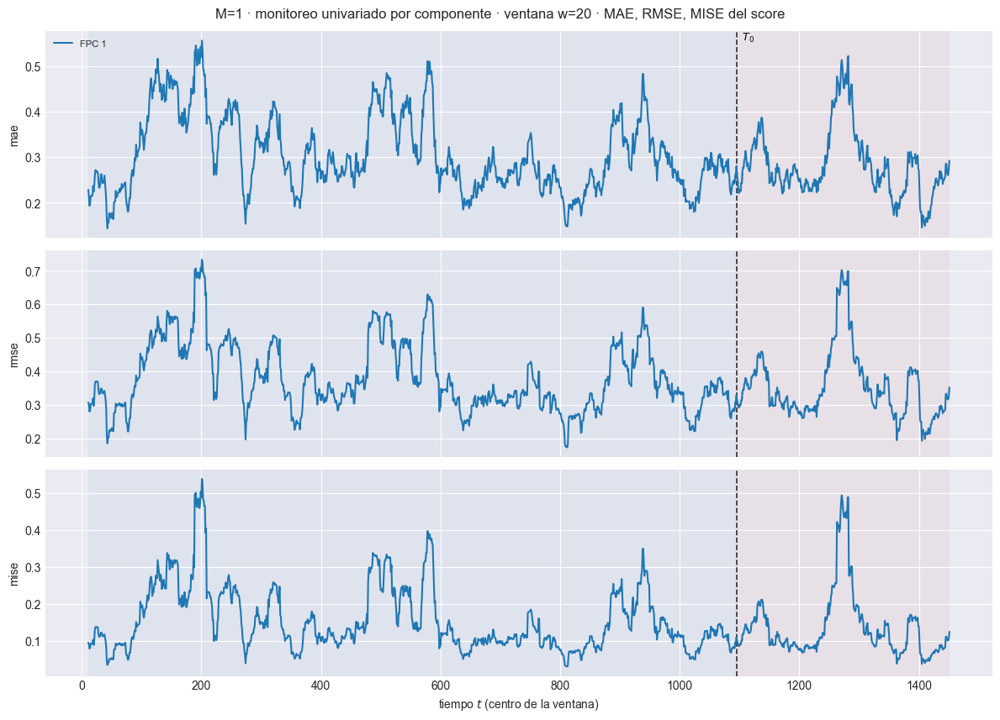

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2866  w=30 test=0.2615
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.358  w=30 test=0.3344
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1281  w=30 test=0.1119
[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m01\91_ventana_univariado_w30.png


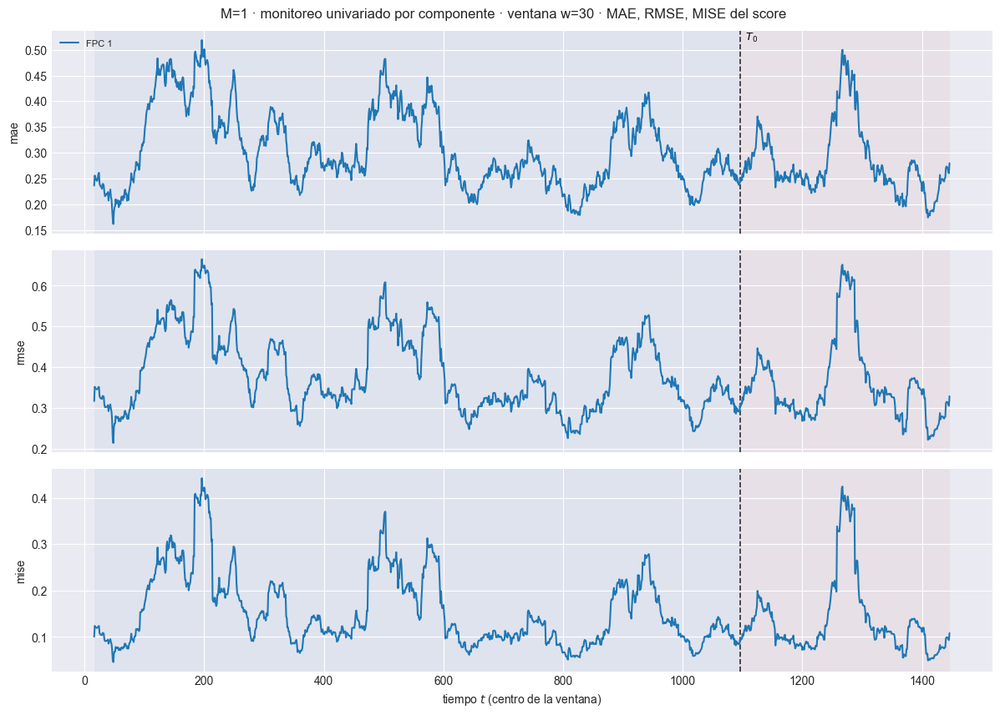

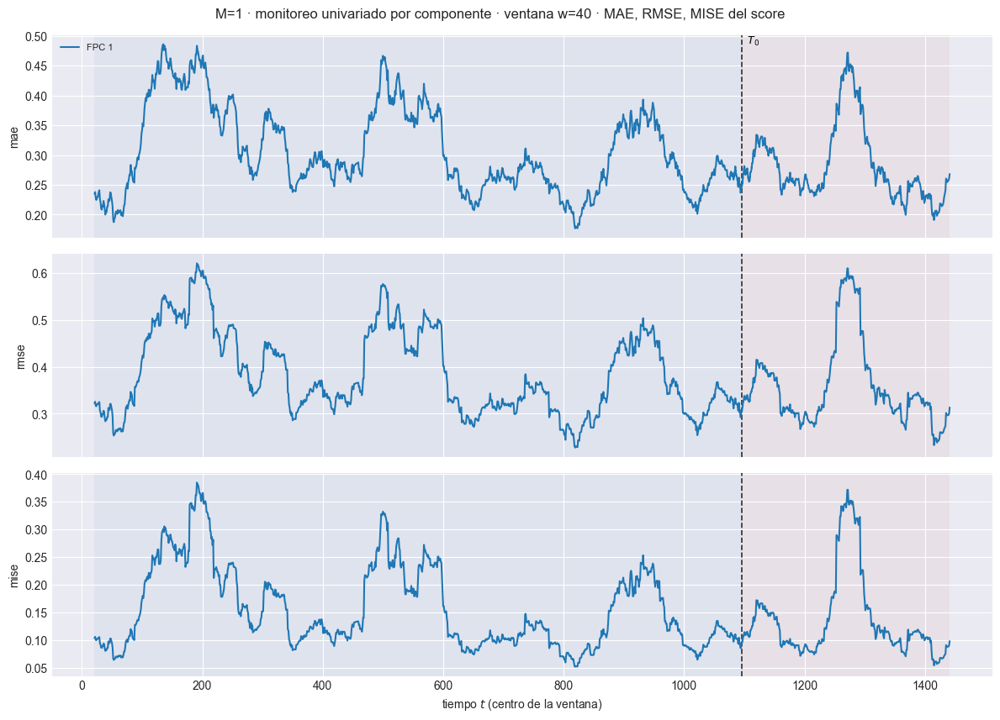

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.6s  t=16 [train] rmse=0.3115
  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.3367
  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.5091
  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4491
  284/1431 (19.8%) t=0.0s eta=0.1s  t=299 [train] rmse=0.3837
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.3366
  426/1431 (29.8%) t=0.0s eta=0.1s  t=441 [train] rmse=0.3158
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4765
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.5064
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2792
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2985
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2852
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.3143
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.5233
  994/1431 (69.5%) t=0.1s eta=0.0s  t=1009 [train] rmse=0.3045
  1065/1431 (74.4%

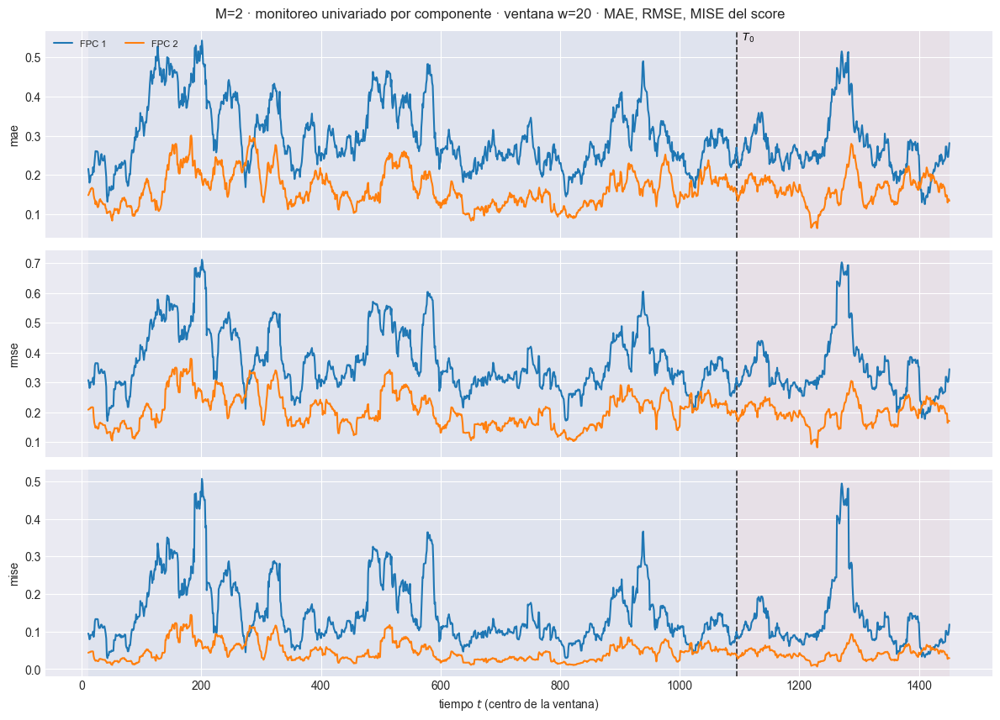

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2187  w=30 test=0.1987
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.2825  w=30 test=0.2379
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.07981  w=30 test=0.0566
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m02\91_ventana_univariado_w30.png


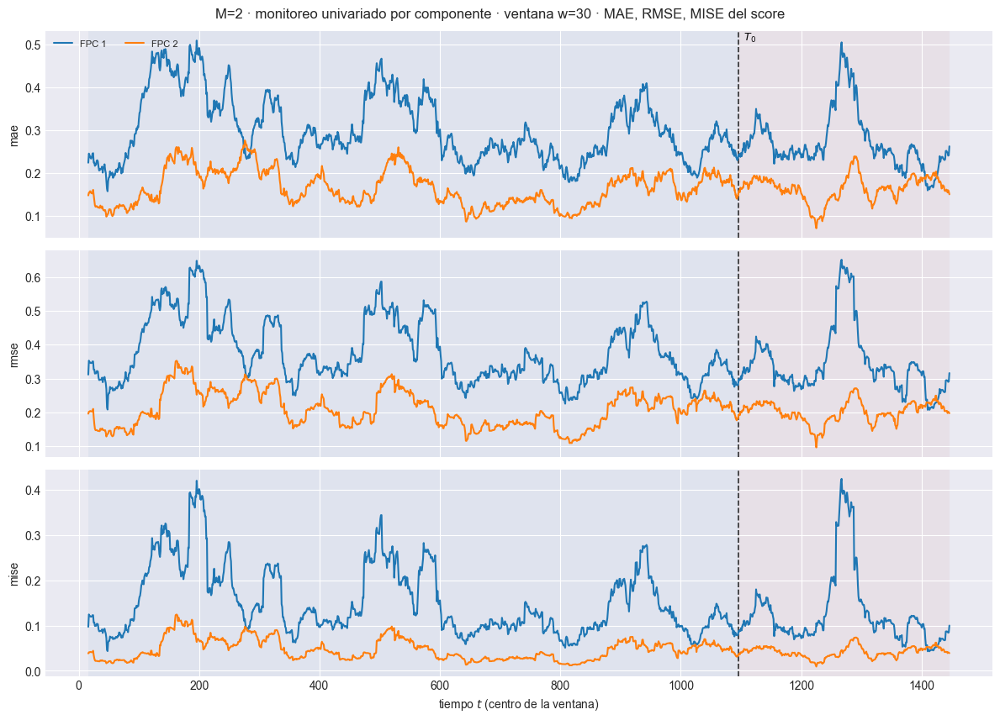

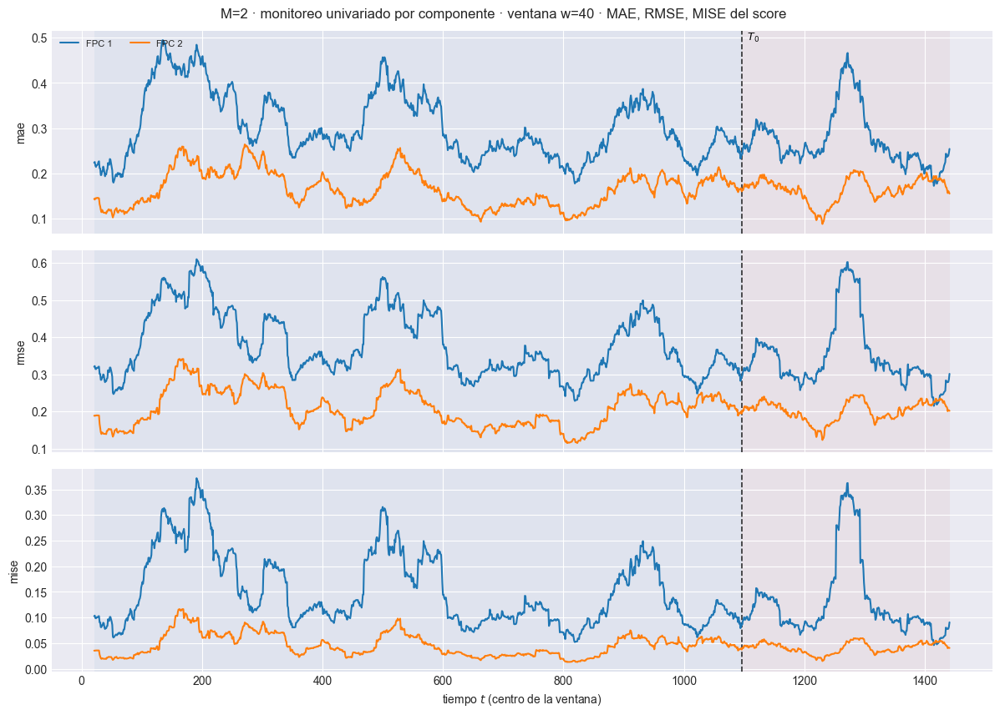

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.5s  t=16 [train] rmse=0.309
  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.294
  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.4246
  213/1431 (14.9%) t=0.0s eta=0.2s  t=228 [train] rmse=0.4235
  284/1431 (19.8%) t=0.0s eta=0.1s  t=299 [train] rmse=0.3619
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.3107
  426/1431 (29.8%) t=0.1s eta=0.1s  t=441 [train] rmse=0.2925
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4552
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.5196
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2824
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2475
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2954
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.3092
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.5014
  994/1431 (69.5%) t=0.1s eta=0.0s  t=1009 [train] rmse=0.3136
  1065/1431 (74.4%) 

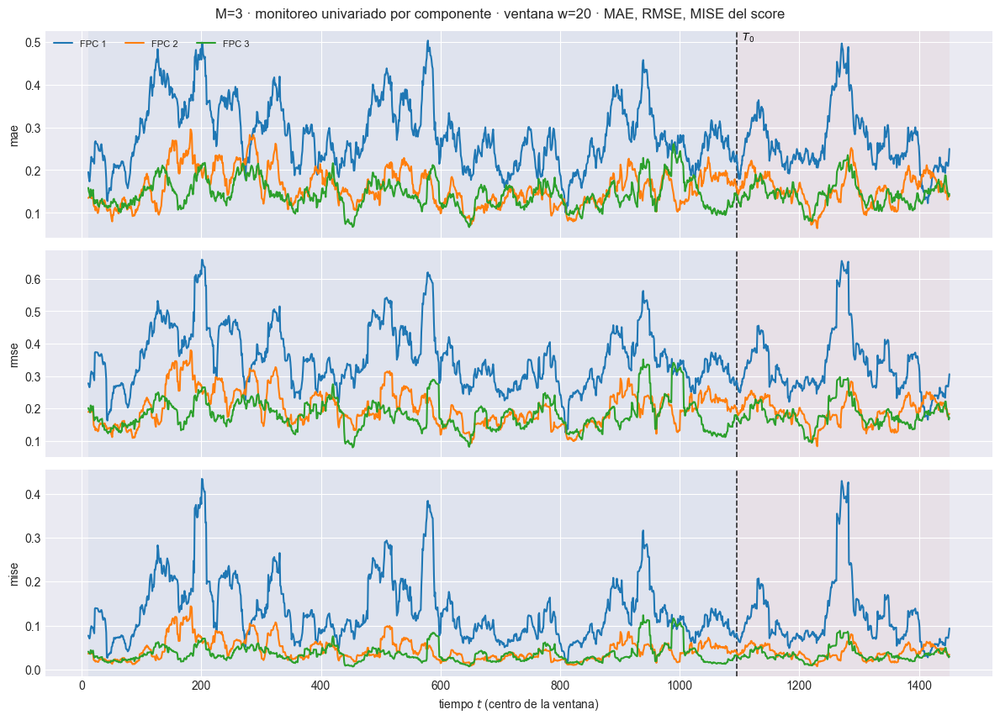

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1729  w=30 test=0.1681
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.2219  w=30 test=0.2087
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.04923  w=30 test=0.04358
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m03\91_ventana_univariado_w30.png


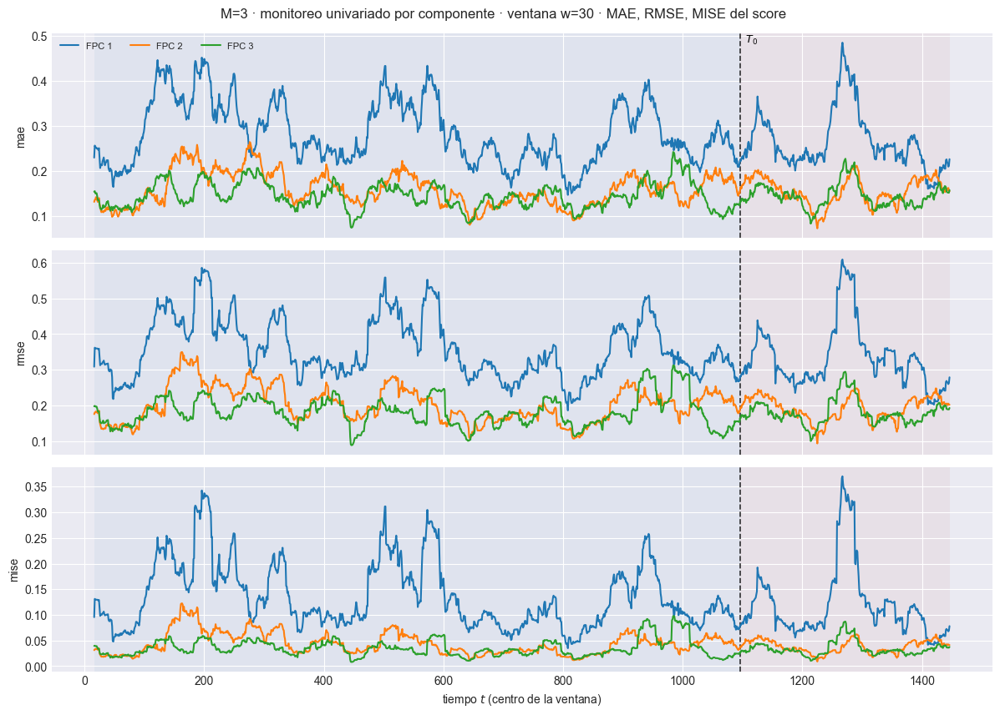

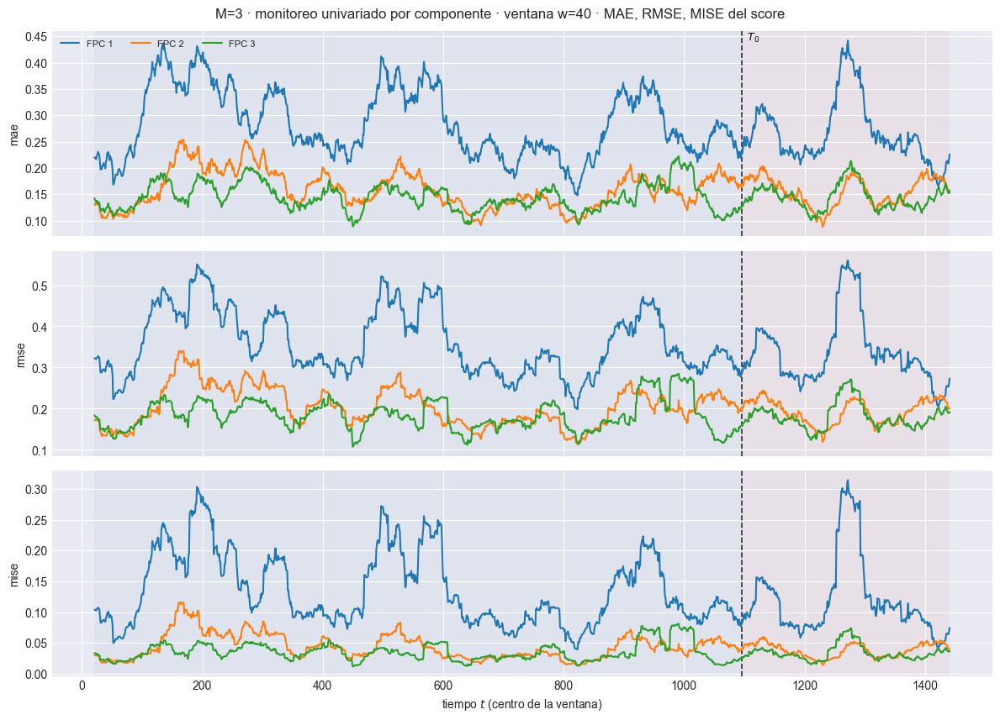

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=2.0s  t=16 [train] rmse=0.319
  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2967
  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.4015
  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4241
  284/1431 (19.8%) t=0.0s eta=0.1s  t=299 [train] rmse=0.3606
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.2945
  426/1431 (29.8%) t=0.0s eta=0.1s  t=441 [train] rmse=0.2921
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4501
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.5109
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2776
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2428
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2725
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.3047
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.4981
  994/1431 (69.5%) t=0.1s eta=0.0s  t=1009 [train] rmse=0.3047
  1065/1431 (74.4%)

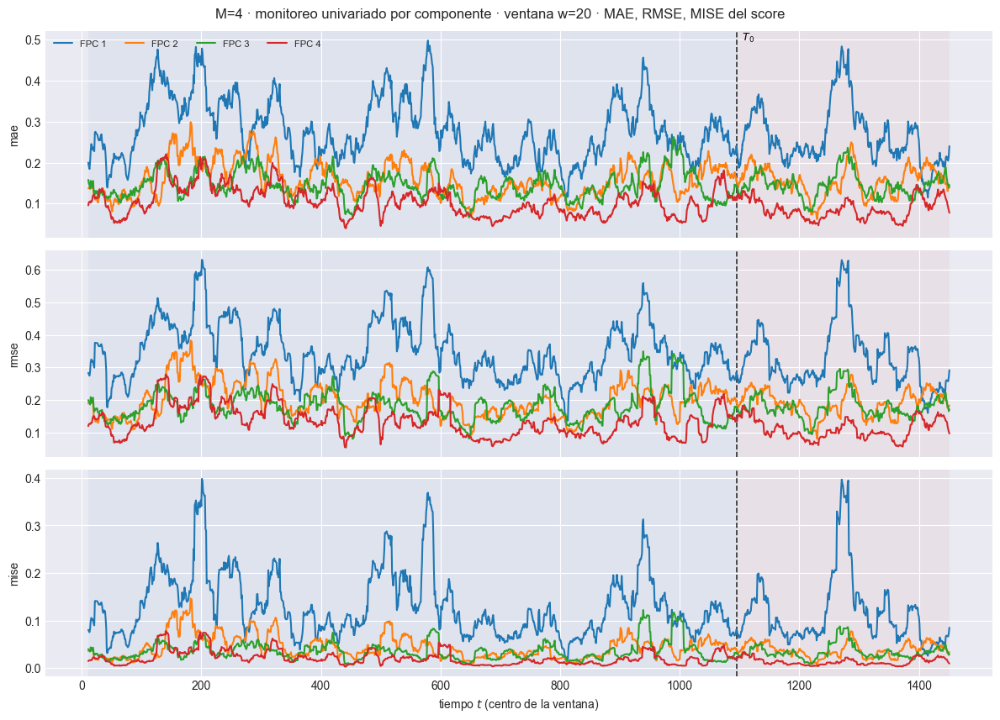

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1509  w=30 test=0.1477
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1934  w=30 test=0.1804
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.03739  w=30 test=0.03256
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m04\91_ventana_univariado_w30.png


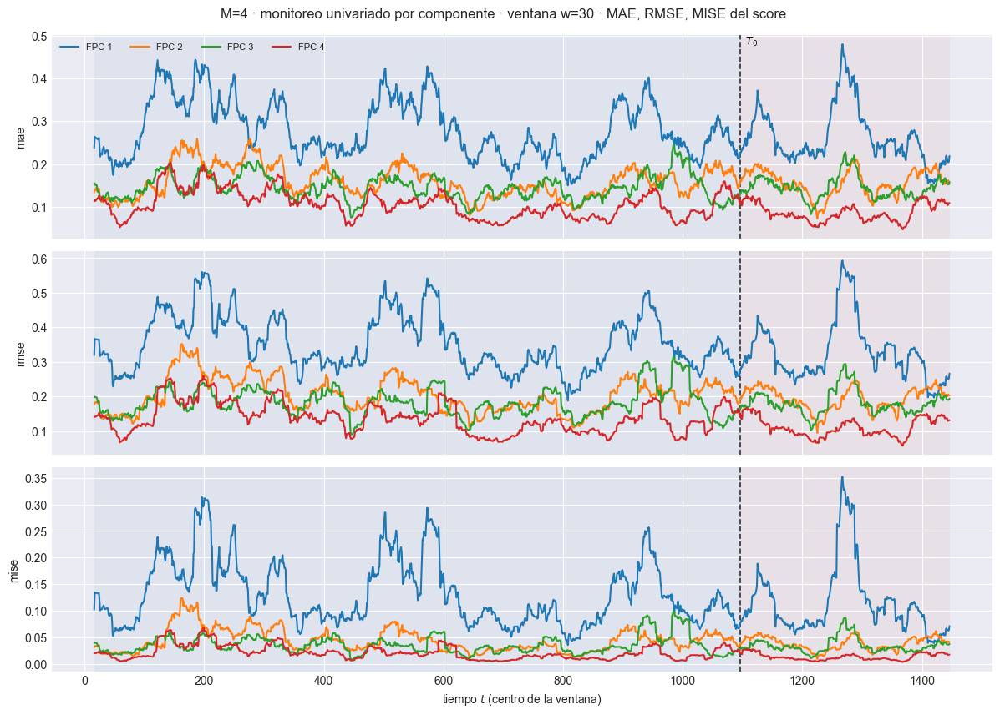

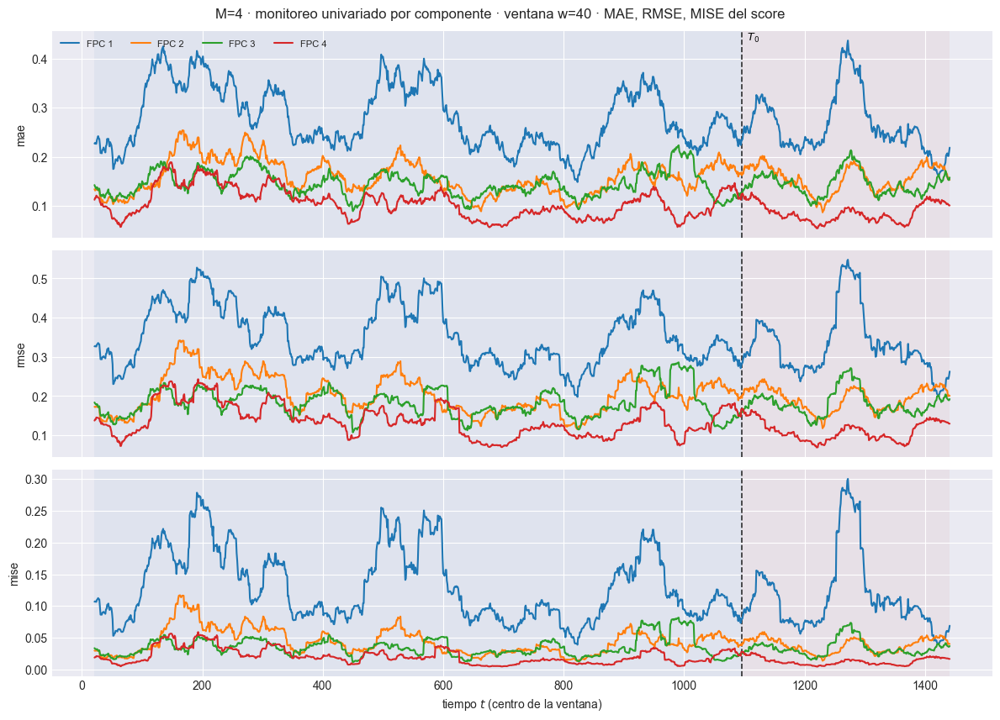

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.2s  t=16 [train] rmse=0.3119
  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2961
  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3806
  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4014
  284/1431 (19.8%) t=0.0s eta=0.1s  t=299 [train] rmse=0.3654
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.2979
  426/1431 (29.8%) t=0.0s eta=0.1s  t=441 [train] rmse=0.2871
  497/1431 (34.7%) t=0.0s eta=0.1s  t=512 [train] rmse=0.455
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.4891
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2731
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2467
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2559
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.2966
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.5055
  994/1431 (69.5%) t=0.1s eta=0.0s  t=1009 [train] rmse=0.3041
  1065/1431 (74.4%)

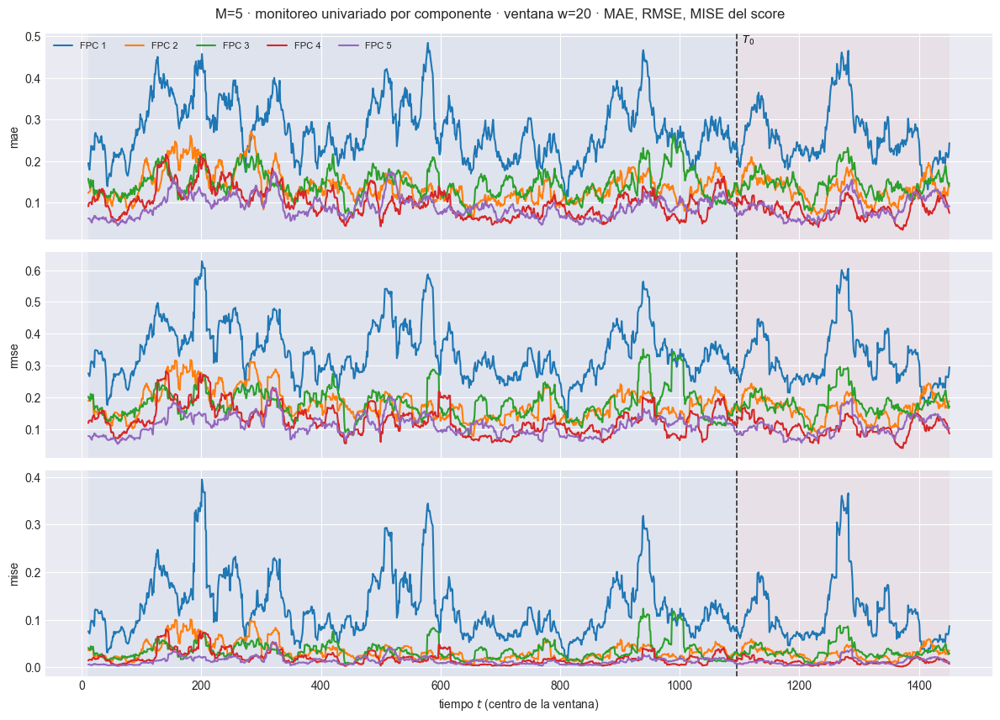

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.128  w=30 test=0.1212
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1646  w=30 test=0.154
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.02709  w=30 test=0.02373
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m05\91_ventana_univariado_w30.png


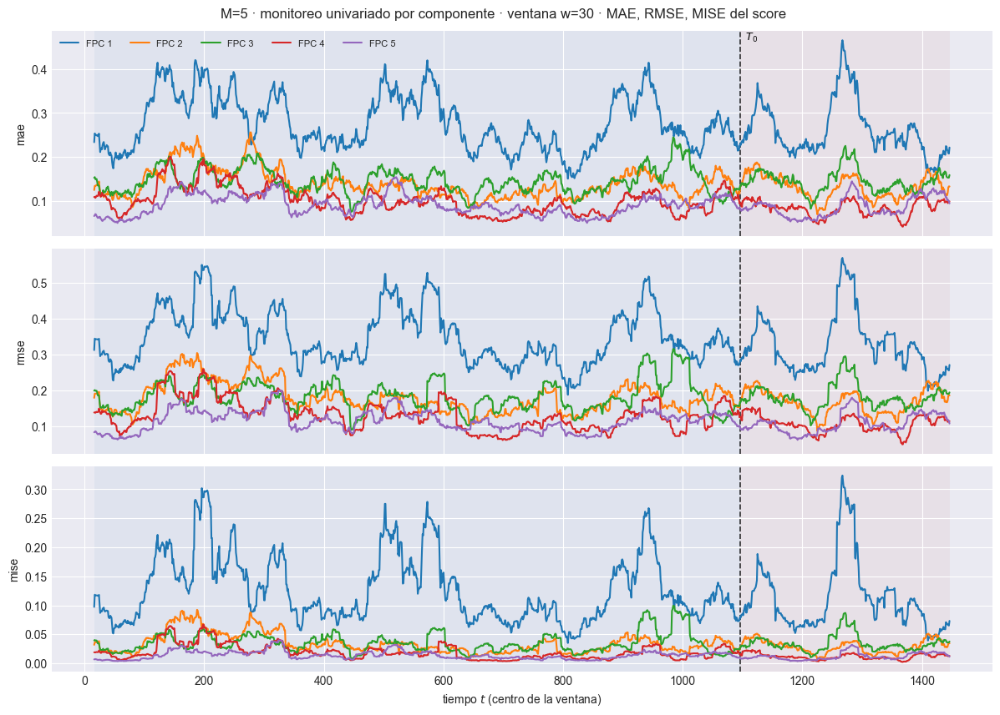

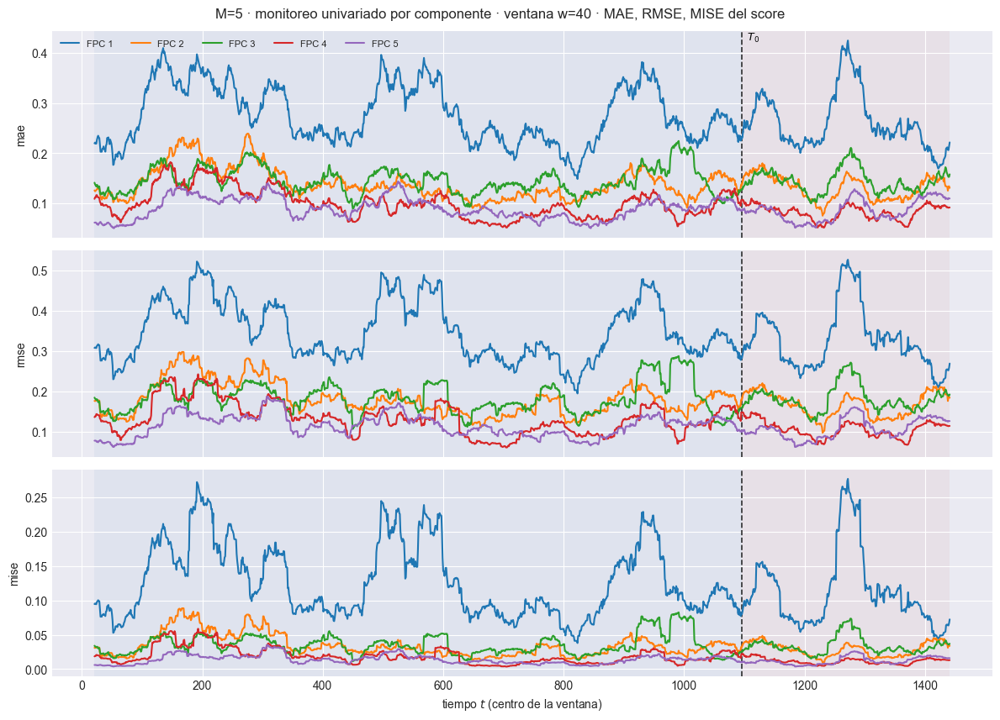

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.4s  t=16 [train] rmse=0.3058
  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.2946
  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3879
  213/1431 (14.9%) t=0.0s eta=0.2s  t=228 [train] rmse=0.4003
  284/1431 (19.8%) t=0.0s eta=0.1s  t=299 [train] rmse=0.3627
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.3022
  426/1431 (29.8%) t=0.1s eta=0.1s  t=441 [train] rmse=0.286
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.452
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.4852
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2728
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2464
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2582
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.3004
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.5095
  994/1431 (69.5%) t=0.1s eta=0.1s  t=1009 [train] rmse=0.3122
  1065/1431 (74.4%) 

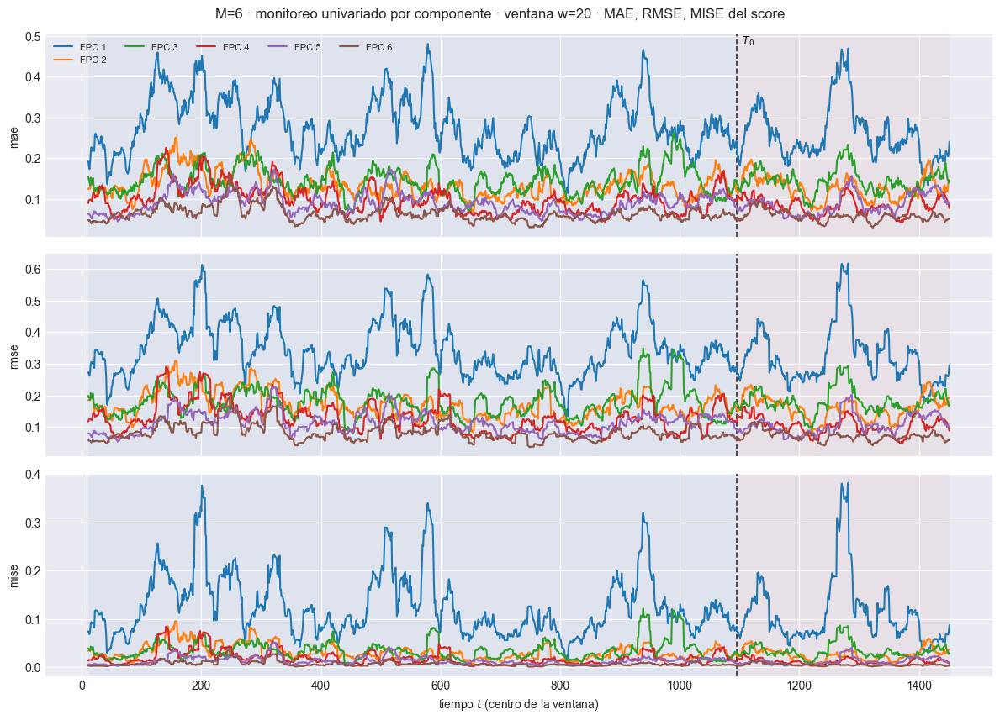

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1157  w=30 test=0.1074
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1469  w=30 test=0.1363
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.02157  w=30 test=0.01859
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m06\91_ventana_univariado_w30.png


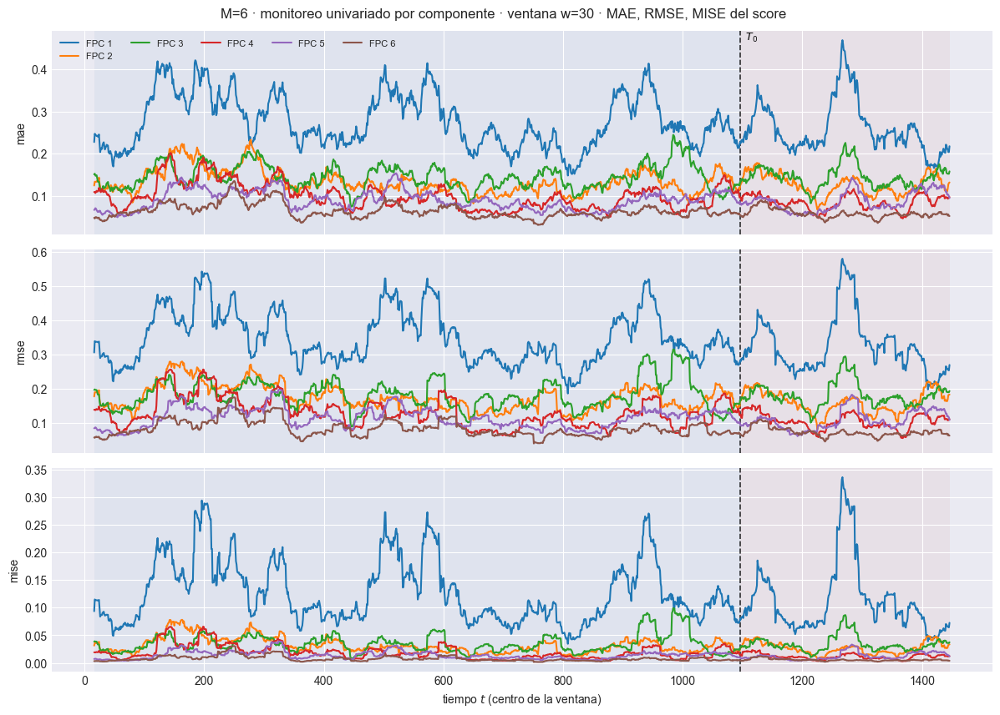

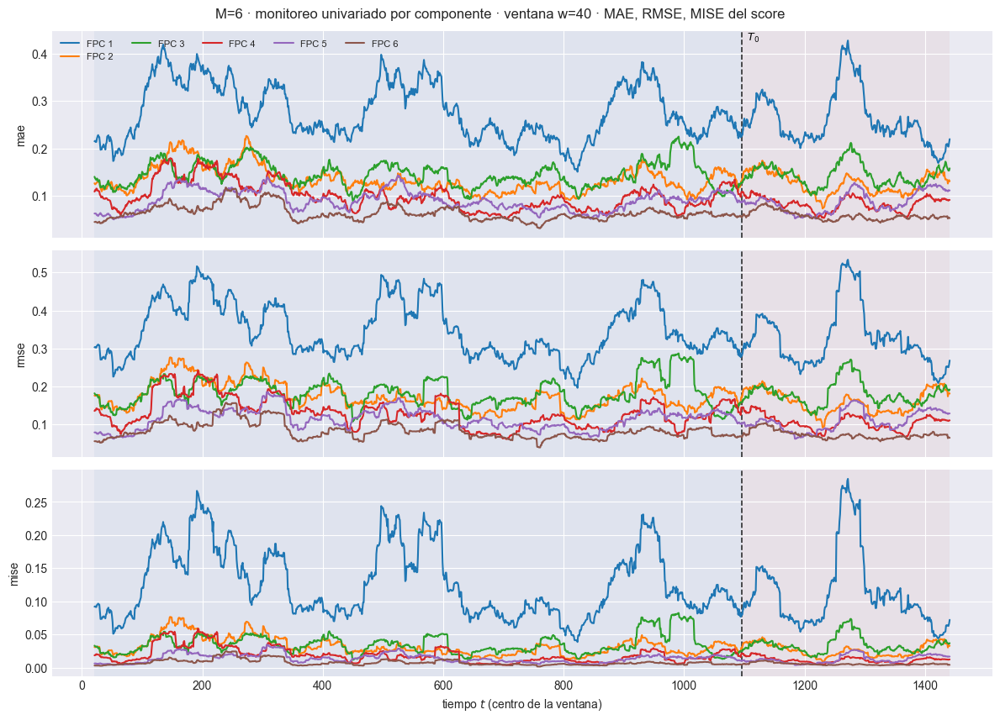

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.8s  t=16 [train] rmse=0.3115
  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.2941
  142/1431 ( 9.9%) t=0.0s eta=0.2s  t=157 [train] rmse=0.3447
  213/1431 (14.9%) t=0.0s eta=0.2s  t=228 [train] rmse=0.403
  284/1431 (19.8%) t=0.0s eta=0.2s  t=299 [train] rmse=0.355
  355/1431 (24.8%) t=0.1s eta=0.2s  t=370 [train] rmse=0.292
  426/1431 (29.8%) t=0.1s eta=0.2s  t=441 [train] rmse=0.2763
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4299
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.4182
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.266
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2656
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2451
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.2835
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.4809
  994/1431 (69.5%) t=0.1s eta=0.1s  t=1009 [train] rmse=0.2874
  1065/1431 (74.4%) t=

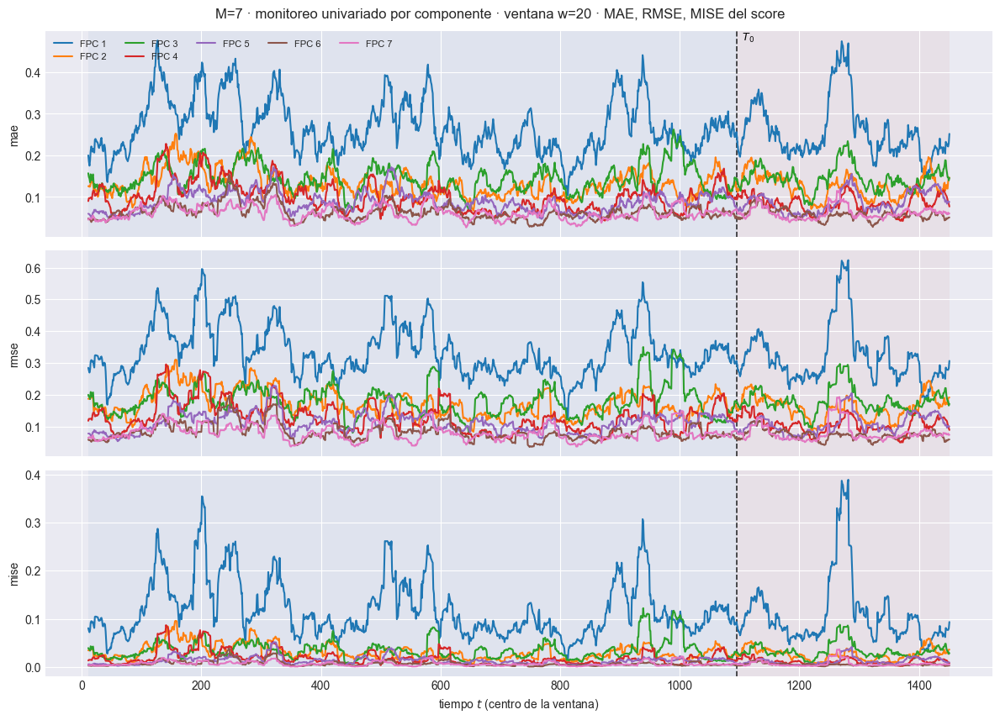

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1036  w=30 test=0.09695
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1328  w=30 test=0.1225
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01765  w=30 test=0.015
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m07\91_ventana_univariado_w30.png


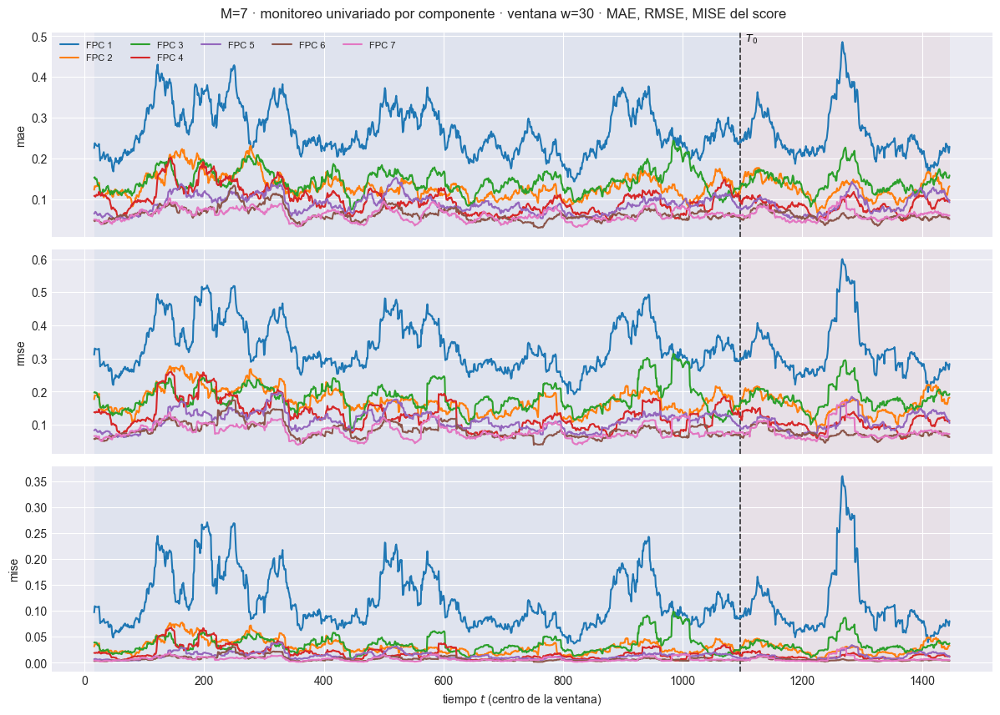

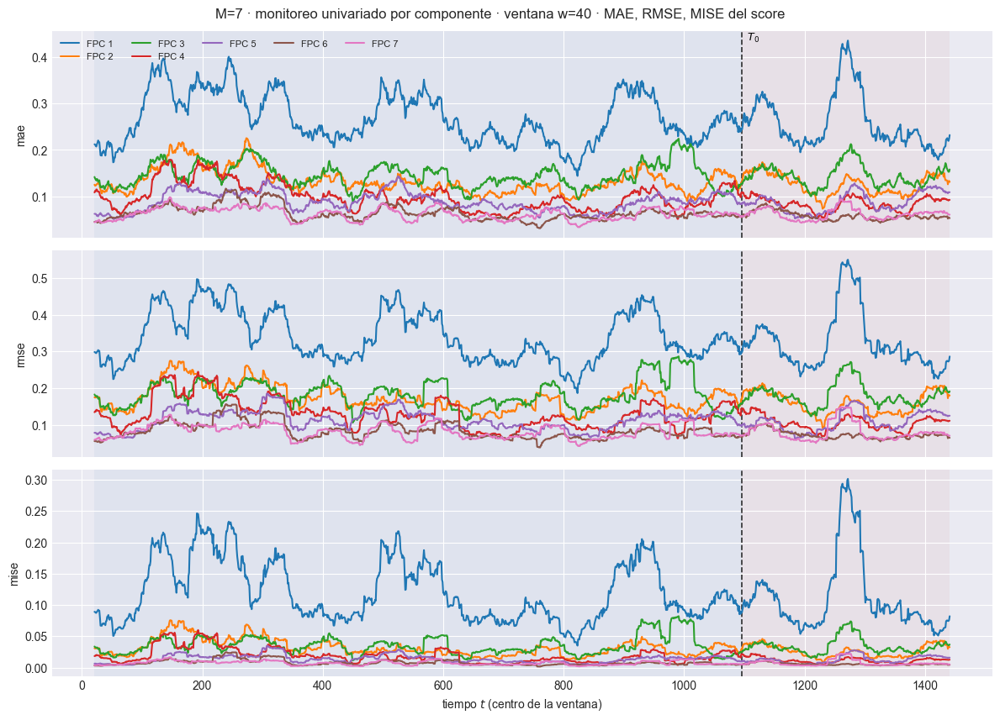

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.2s  t=16 [train] rmse=0.3185
  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.2964
  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3478
  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4029
  284/1431 (19.8%) t=0.0s eta=0.1s  t=299 [train] rmse=0.3582
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.2893
  426/1431 (29.8%) t=0.1s eta=0.1s  t=441 [train] rmse=0.2771
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4262
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.4307
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2634
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2681
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2449
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.2819
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.482
  994/1431 (69.5%) t=0.1s eta=0.1s  t=1009 [train] rmse=0.2778
  1065/1431 (74.4%)

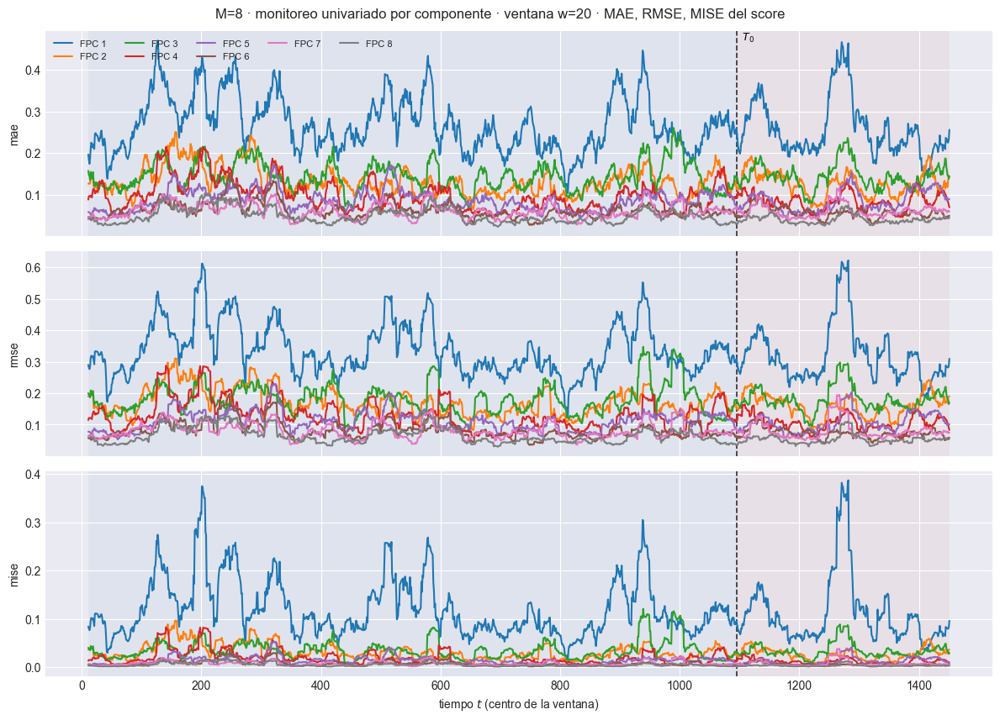

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.09243  w=30 test=0.0839
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1206  w=30 test=0.1071
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01454  w=30 test=0.01147
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m08\91_ventana_univariado_w30.png


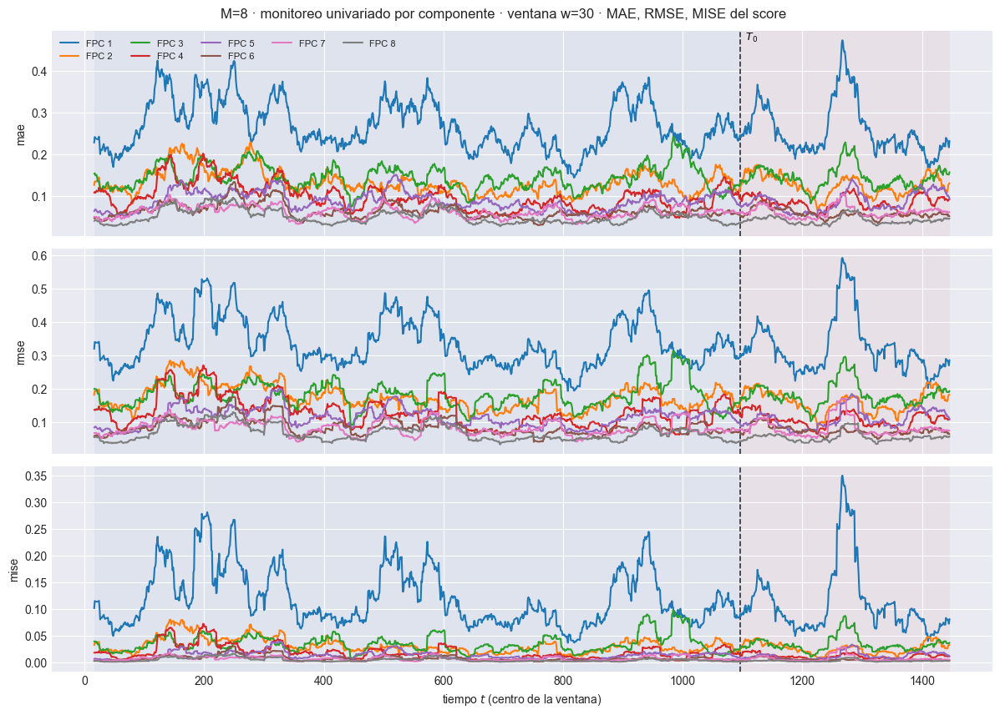

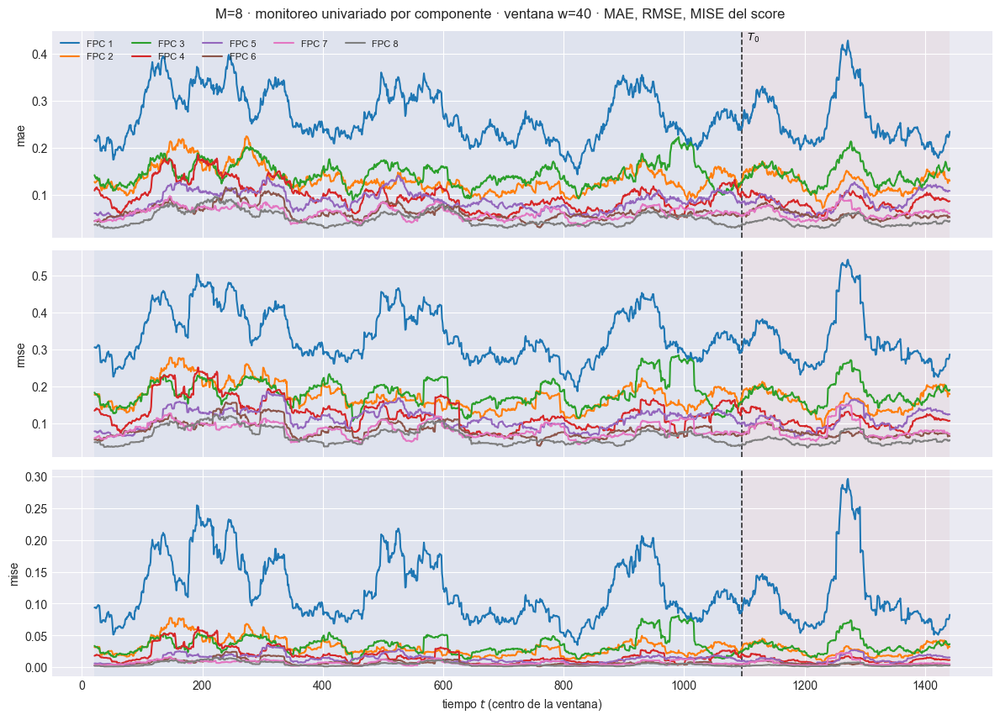

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.7s  t=16 [train] rmse=0.3087
  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2885
  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3601
  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4039
  284/1431 (19.8%) t=0.0s eta=0.2s  t=299 [train] rmse=0.3384
  355/1431 (24.8%) t=0.1s eta=0.2s  t=370 [train] rmse=0.2808
  426/1431 (29.8%) t=0.1s eta=0.2s  t=441 [train] rmse=0.2641
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4255
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.407
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2638
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2537
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2488
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.276
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.4662
  994/1431 (69.5%) t=0.1s eta=0.1s  t=1009 [train] rmse=0.289
  1065/1431 (74.4%) t

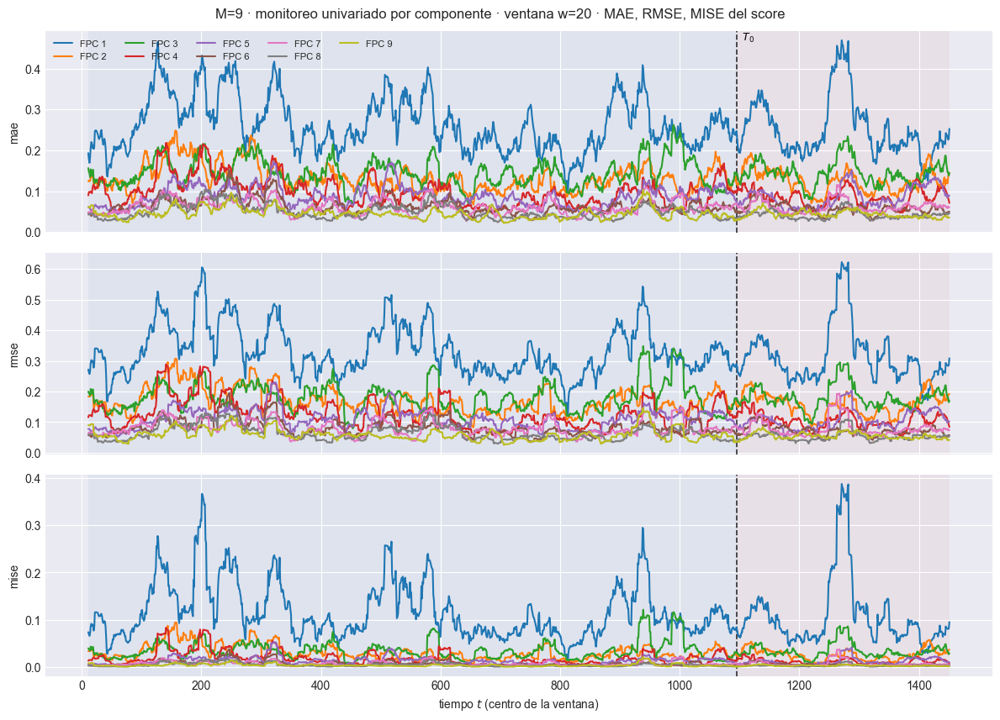

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.08245  w=30 test=0.07578
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1108  w=30 test=0.09579
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01227  w=30 test=0.009176
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m09\91_ventana_univariado_w30.png


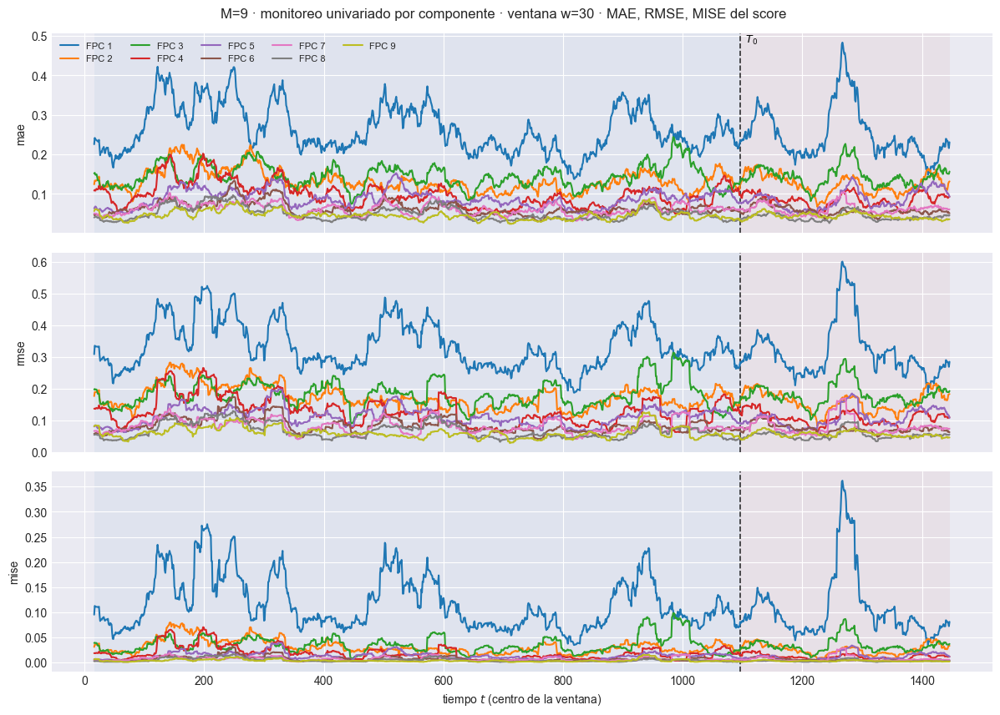

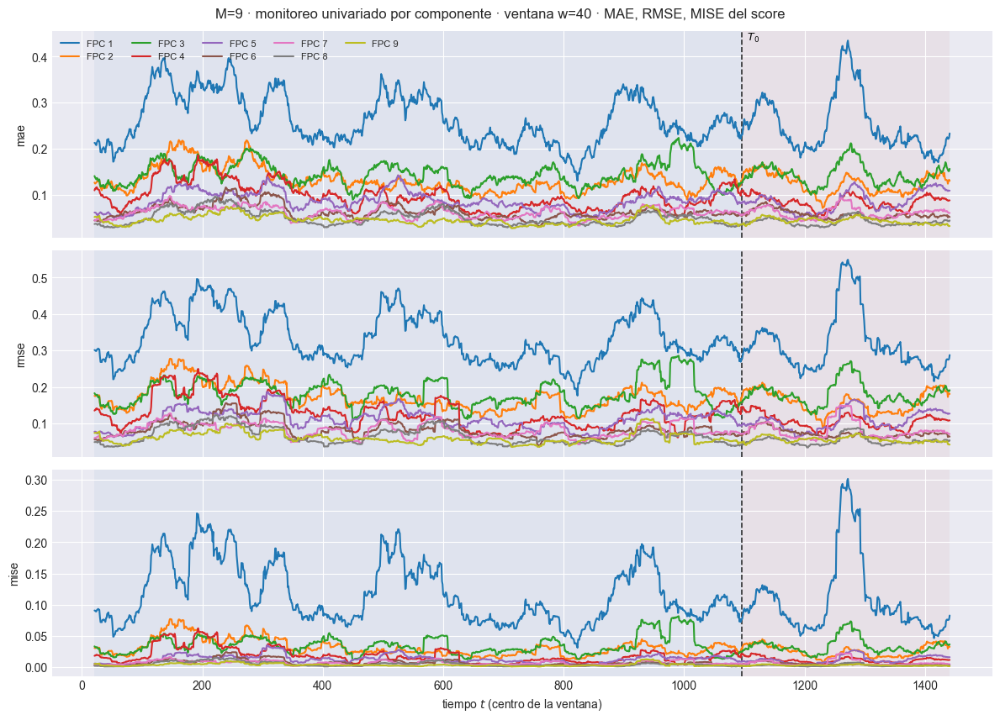

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)
  1/1431 ( 0.1%) t=0.0s eta=1.6s  t=16 [train] rmse=0.3102
  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.2894
  142/1431 ( 9.9%) t=0.0s eta=0.2s  t=157 [train] rmse=0.3657
  213/1431 (14.9%) t=0.0s eta=0.2s  t=228 [train] rmse=0.4038
  284/1431 (19.8%) t=0.0s eta=0.2s  t=299 [train] rmse=0.3443
  355/1431 (24.8%) t=0.0s eta=0.1s  t=370 [train] rmse=0.2858
  426/1431 (29.8%) t=0.1s eta=0.1s  t=441 [train] rmse=0.2674
  497/1431 (34.7%) t=0.1s eta=0.1s  t=512 [train] rmse=0.4249
  568/1431 (39.7%) t=0.1s eta=0.1s  t=583 [train] rmse=0.4089
  639/1431 (44.7%) t=0.1s eta=0.1s  t=654 [train] rmse=0.2618
  710/1431 (49.6%) t=0.1s eta=0.1s  t=725 [train] rmse=0.2579
  781/1431 (54.6%) t=0.1s eta=0.1s  t=796 [train] rmse=0.2497
  852/1431 (59.5%) t=0.1s eta=0.1s  t=867 [train] rmse=0.2807
  923/1431 (64.5%) t=0.1s eta=0.1s  t=938 [train] rmse=0.4718
  994/1431 (69.5%) t=0.1s eta=0.1s  t=1009 [train] rmse=0.2843
  1065/1431 (74.4%

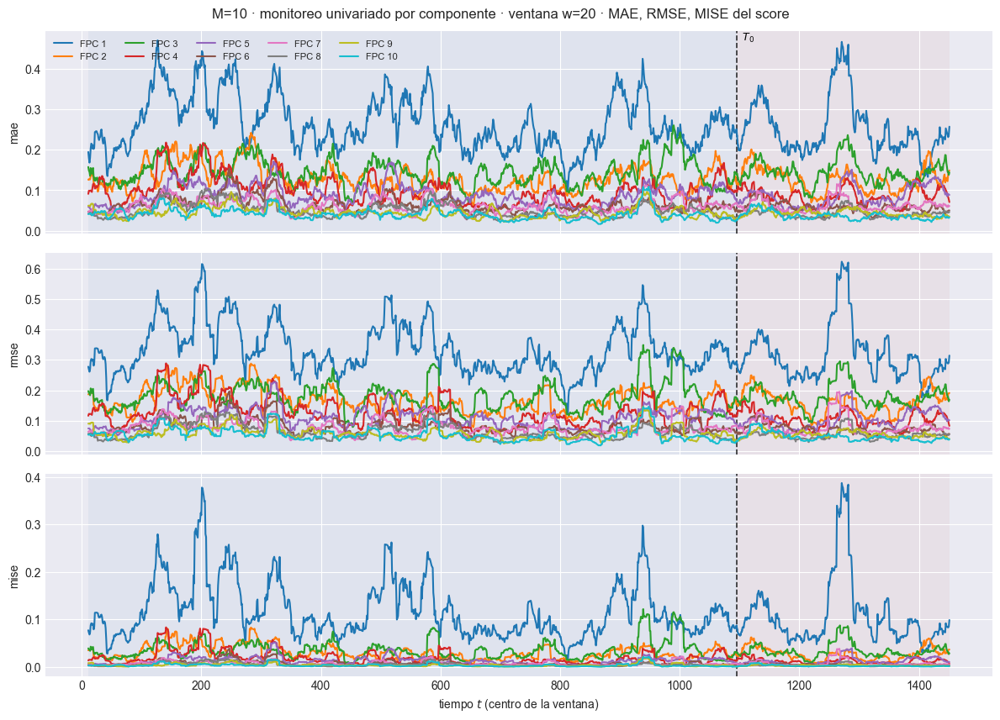

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.1s eta=0.2s  mae: w=30 train=0.07556  w=30 test=0.06736
  2/3 (66.7%) t=0.2s eta=0.1s  rmse: w=30 train=0.1015  w=30 test=0.08699
  3/3 (100.0%) t=0.2s eta=0.0s  mise: w=30 train=0.01029  w=30 test=0.007567
[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m10\91_ventana_univariado_w30.png


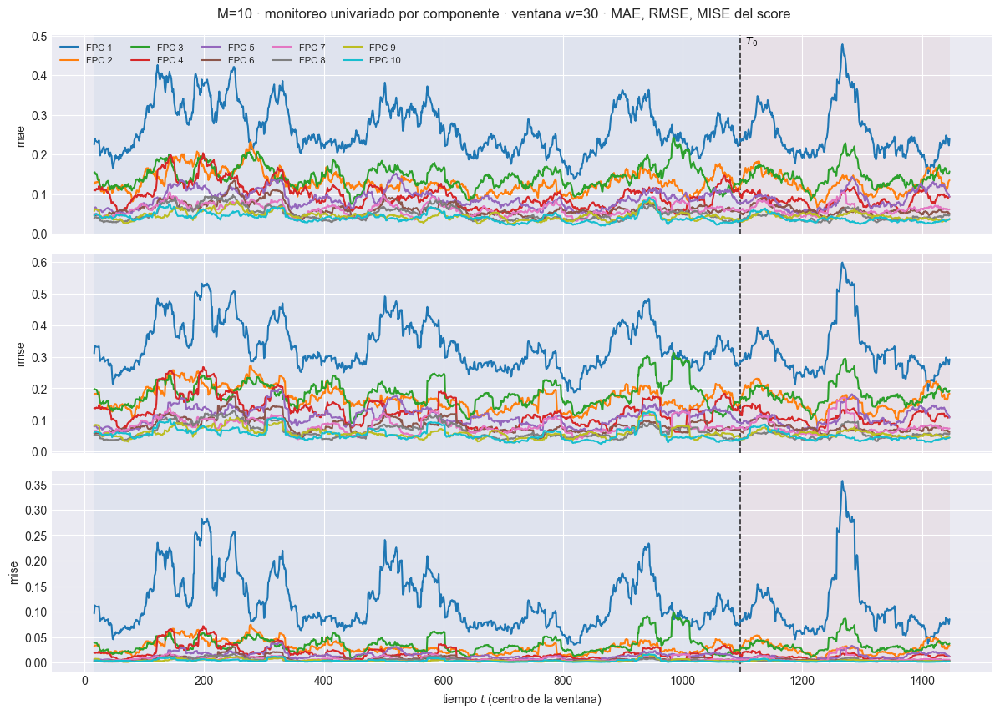

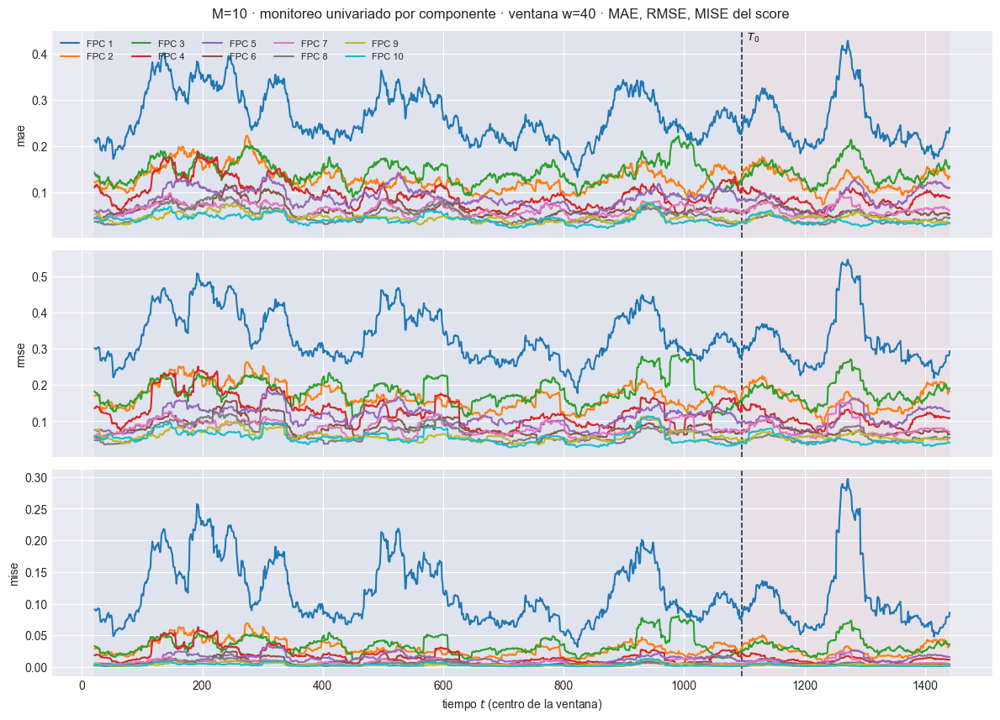

In [15]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

Las secciones anteriores miran la **curva**, que es el producto final. Ésta
mira el objeto que el muestreador predice de verdad: el score $\xi_{t,k}$ de
cada componente. La curva sale de propagarlos, así que un problema de
calibración que aquí se vea localizado en una componente queda, allá,
promediado con las demás y es mucho más difícil de atribuir.

| | qué muestra |
|---|---|
| **§10.1** | el intervalo de credibilidad de cada $\xi_k$ a lo largo del tiempo, con $\xi$ observado encima |
| **§10.2** | las métricas de ese intervalo: PICP, MPIW, Winkler, ACE — globales por bloque y sobre la ventana móvil, un panel por ancho |
| **§10.3** | dispersión $\hat\xi$ contra $\xi$ con la diagonal, componente a componente |

La banda es `li_s`/`ls_s`, los cuantiles muestrales de la predictiva por score
que §3 ya calculó: es **la misma** de la que sale la banda funcional, antes de
propagarla. No se vuelve a muestrear nada.


### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

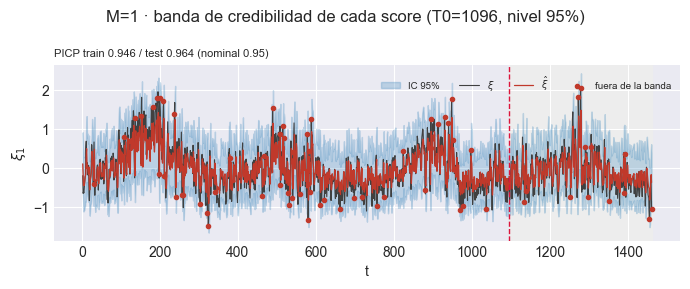

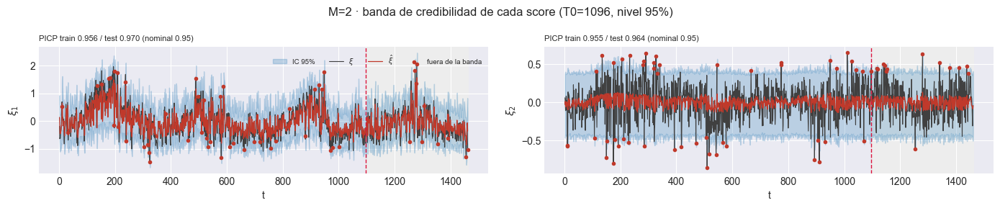

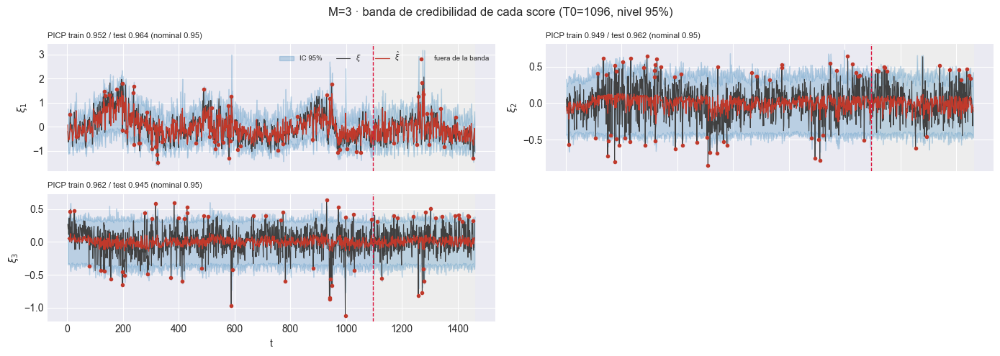

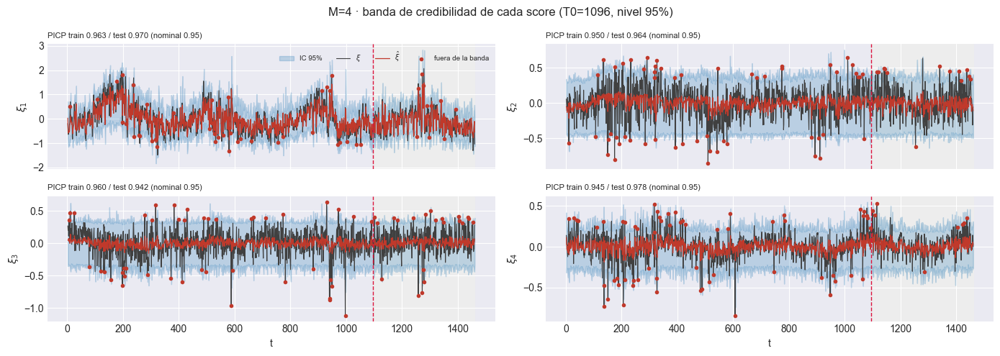

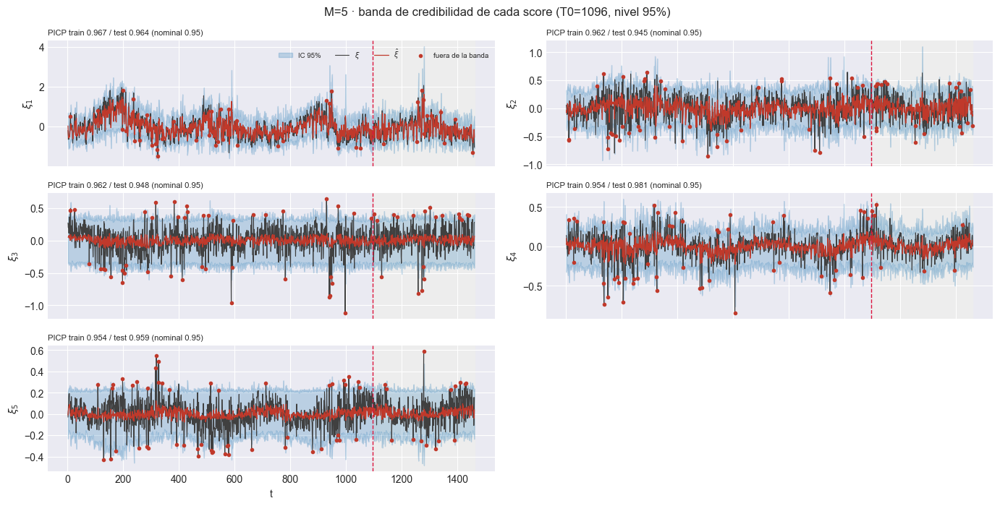

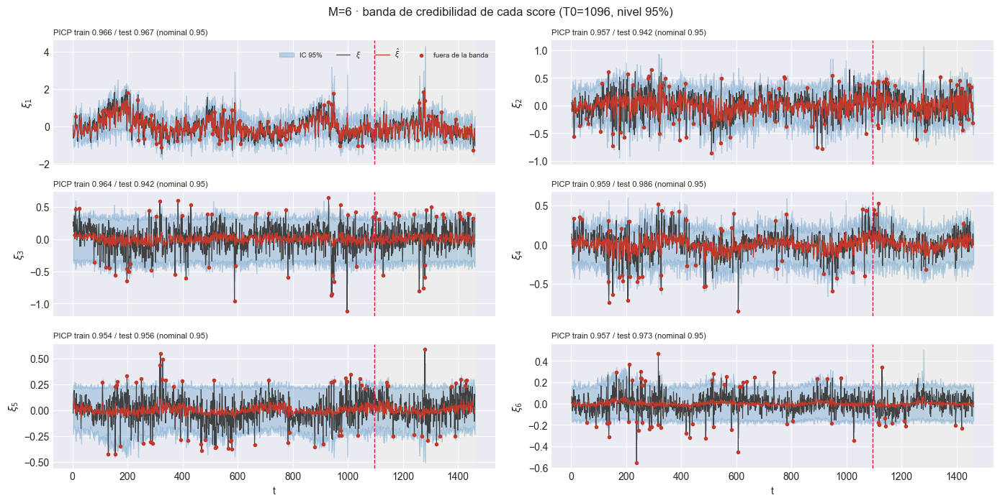

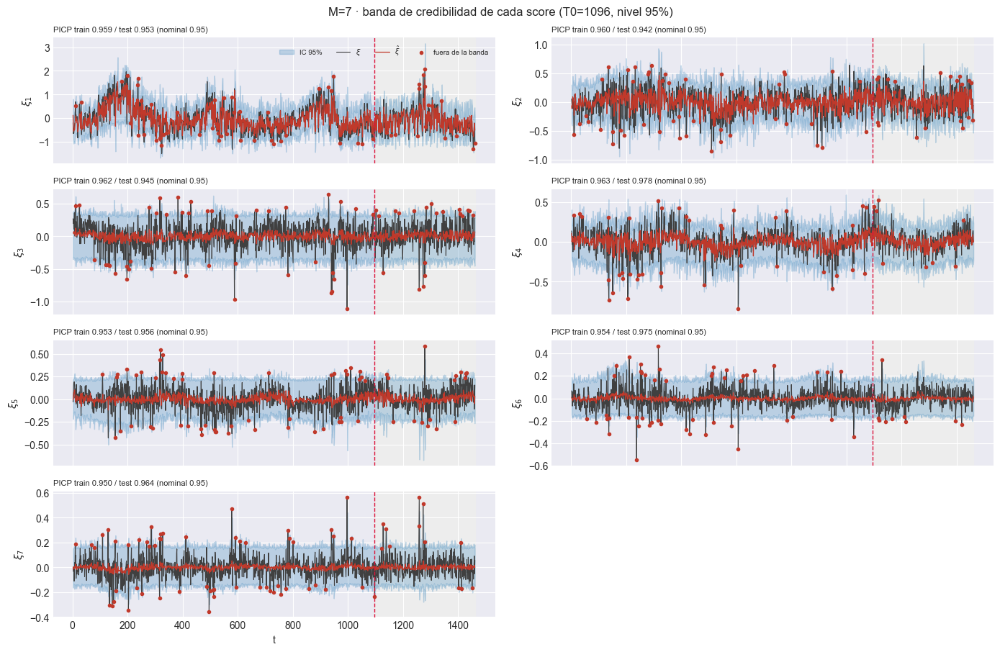

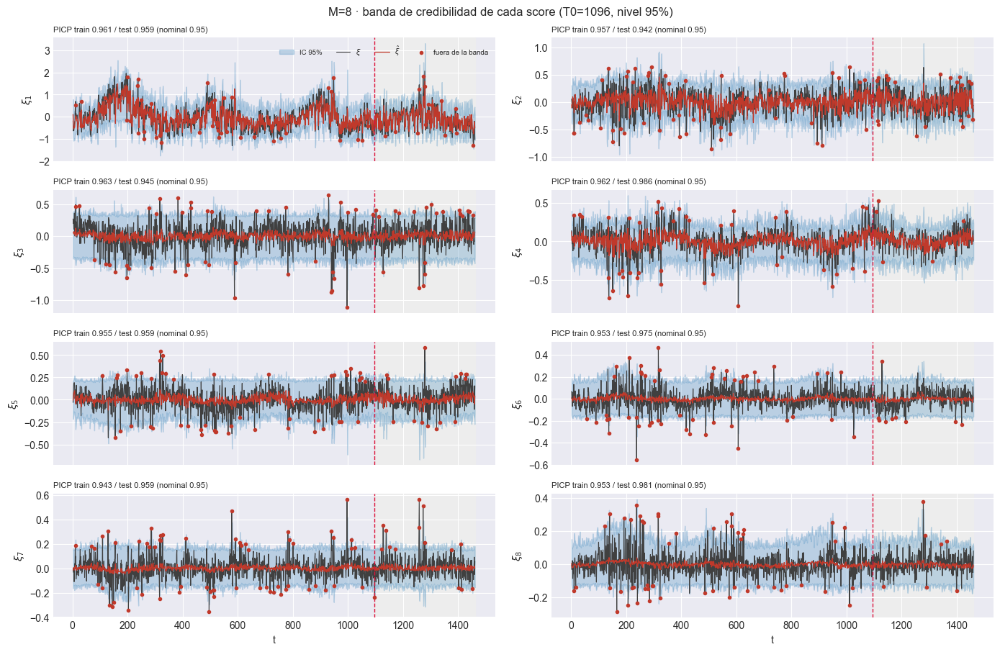

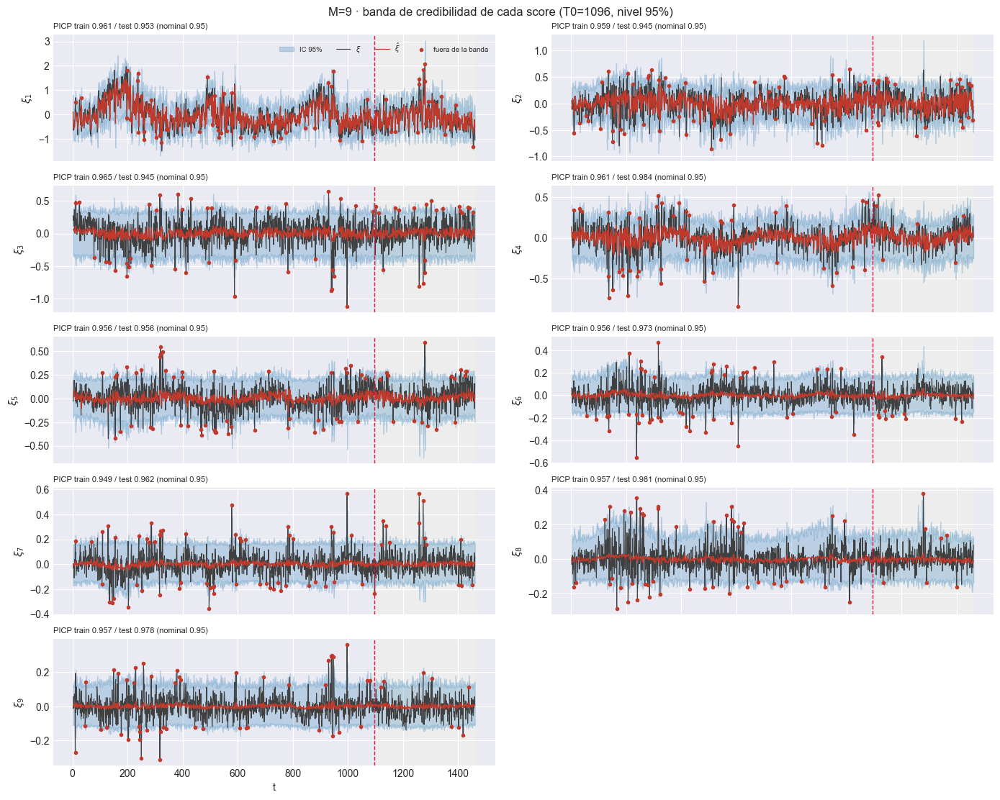

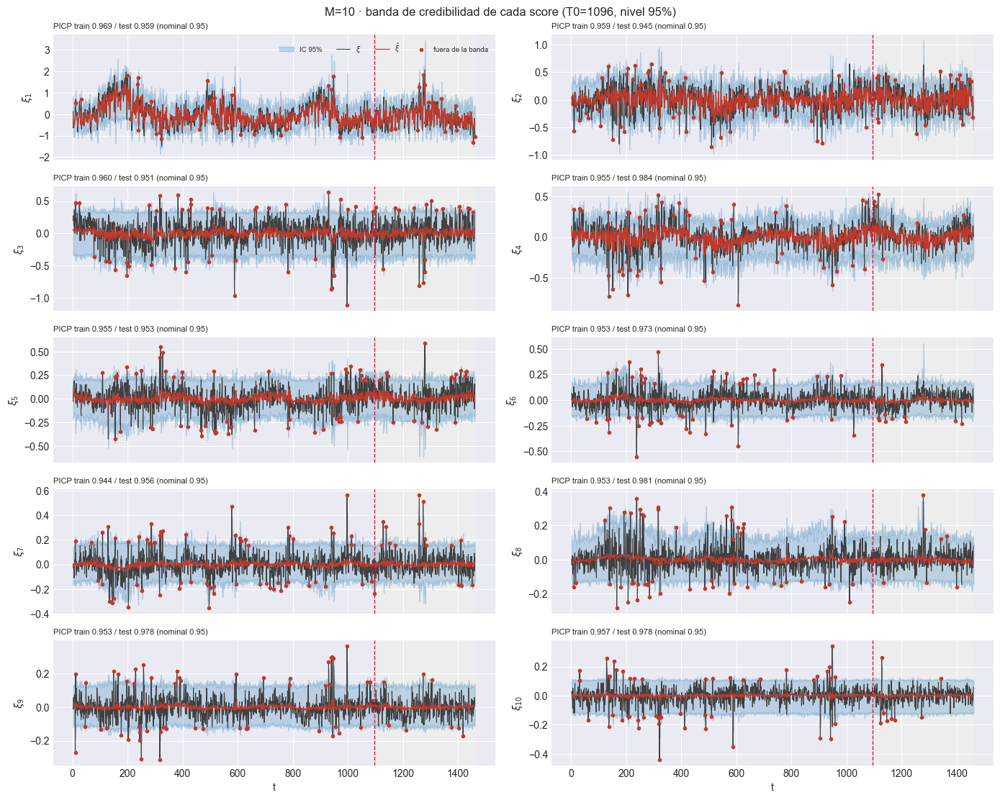

In [16]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

Las mismas cuatro cifras del Bloque B, pero por componente y en la escala del
score: **PICP** (fracción de orígenes cubiertos), **MPIW** (ancho medio),
**Winkler** (regla de puntuación que penaliza ancho y fallo a la vez) y
**ACE** = PICP − nominal, que es el signo de la miscalibración: negativo es
subcobertura.

Primero la lectura global por bloque; después la evolución sobre la ventana
móvil, **un panel por ancho**, con el mismo criterio de §4 y §5.


OK ninguna componente se aleja mas de 0.1 del nominal en test.


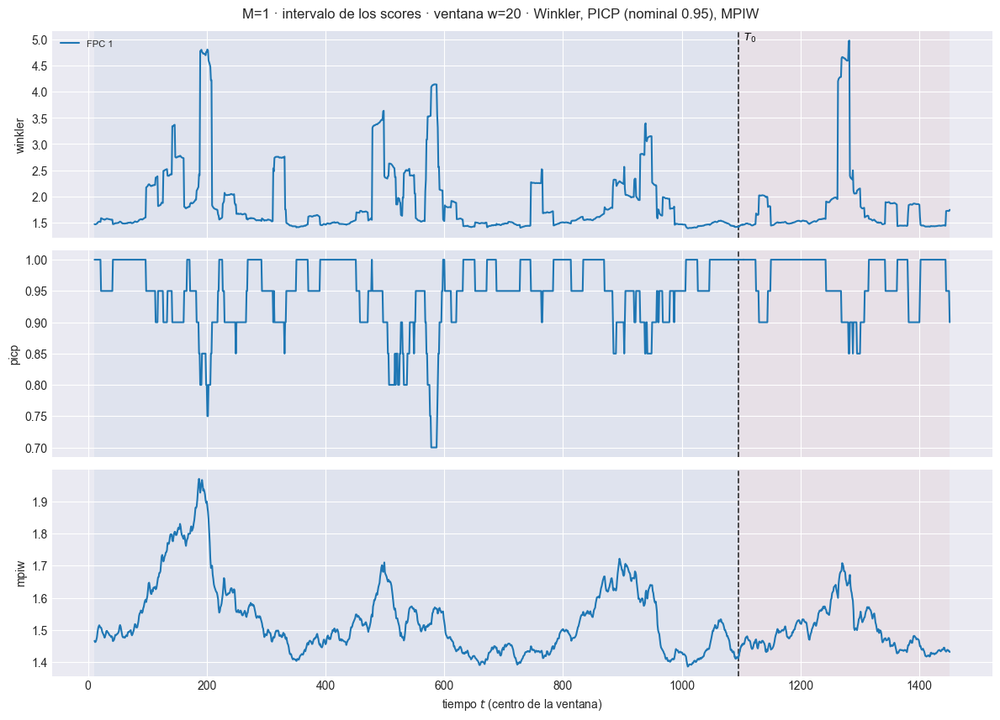

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.629  w=30 test=1.623
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.504  w=30 test=1.491
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m01\93_ventana_scores_intervalo_w30.png


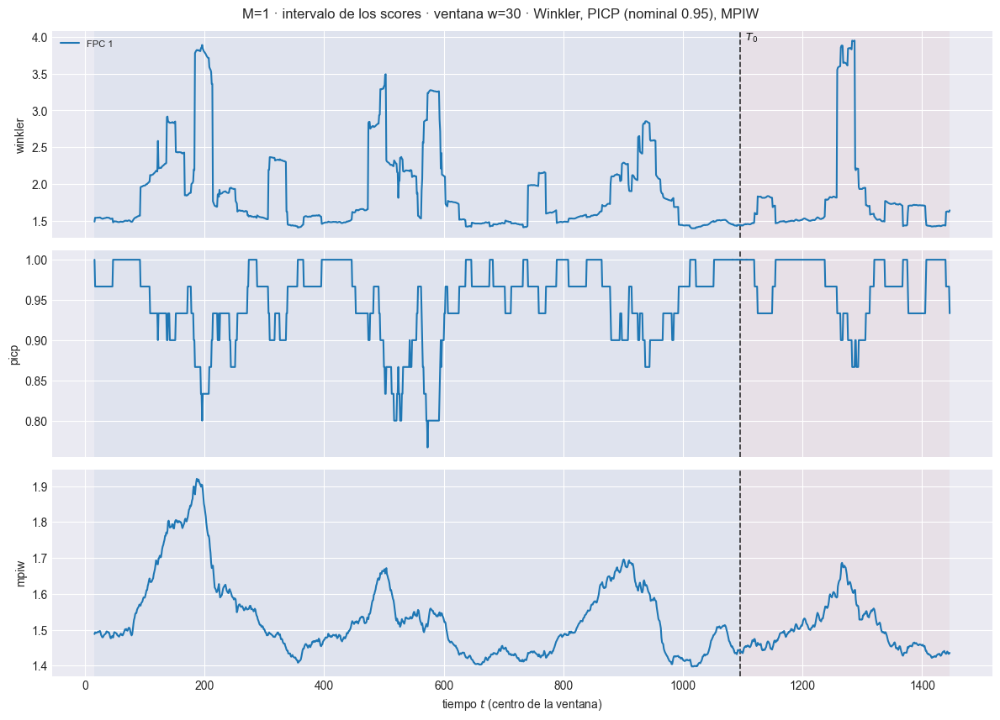

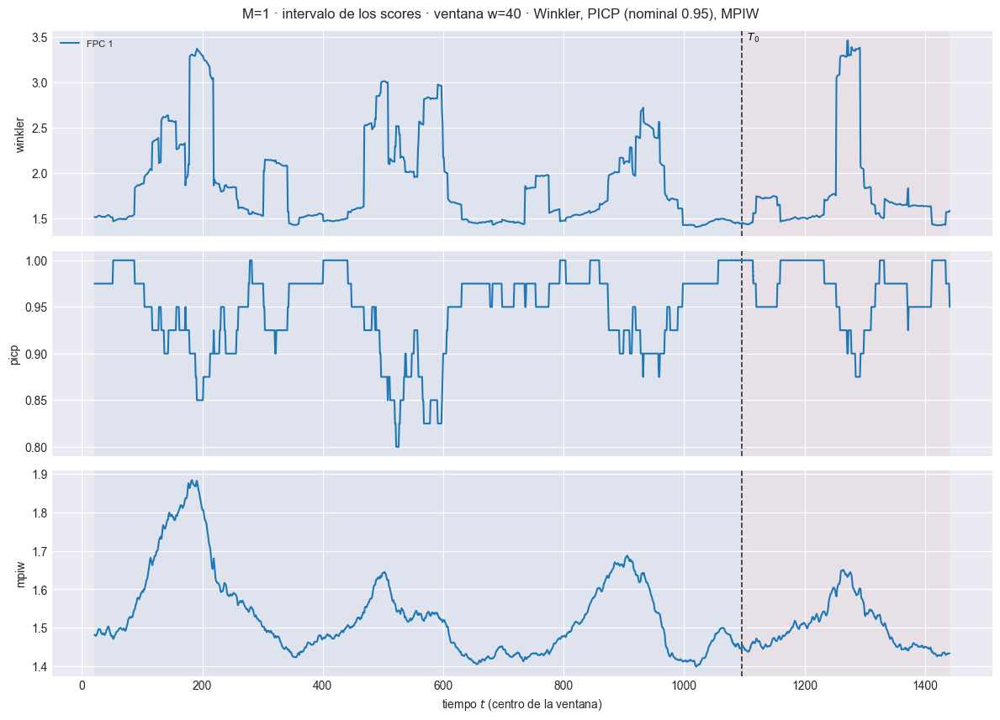

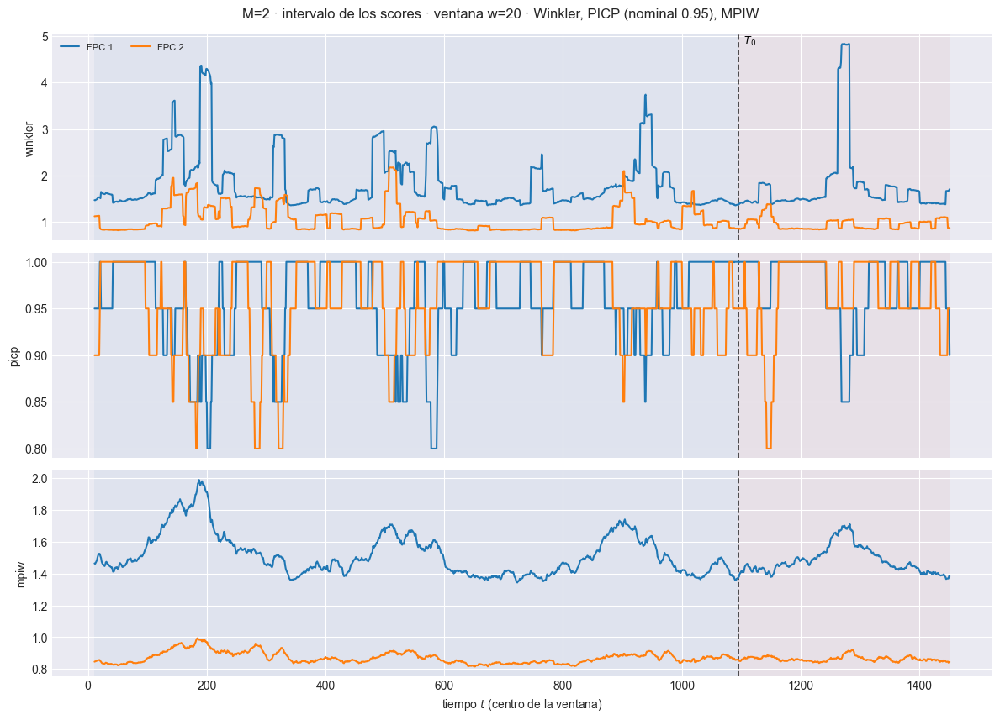

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.426  w=30 test=1.312
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.174  w=30 test=1.14
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m02\93_ventana_scores_intervalo_w30.png


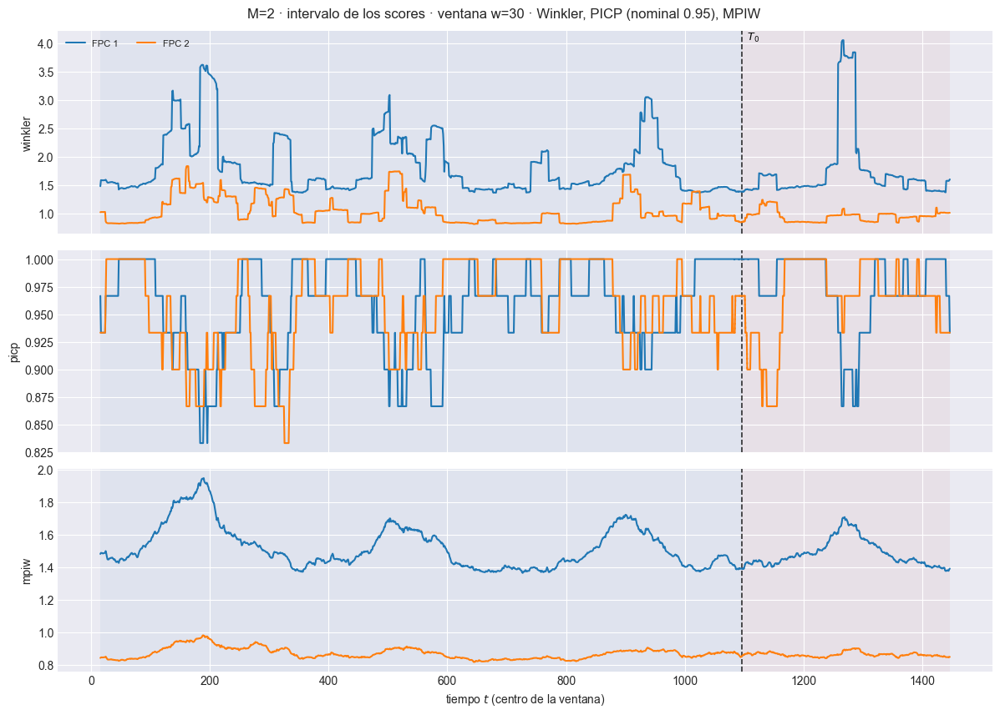

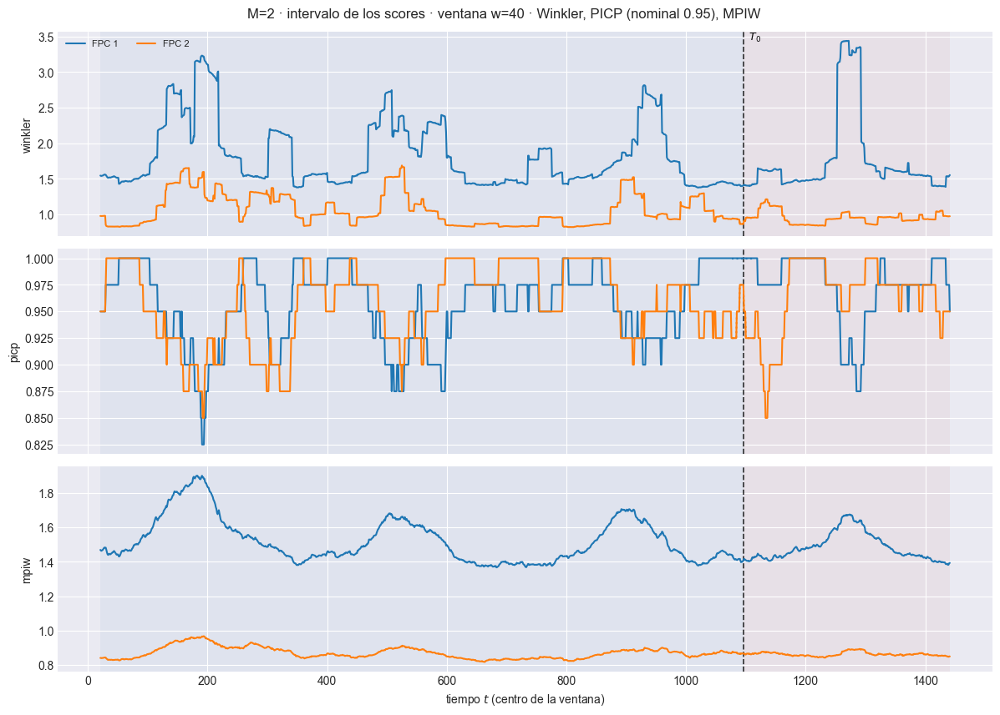

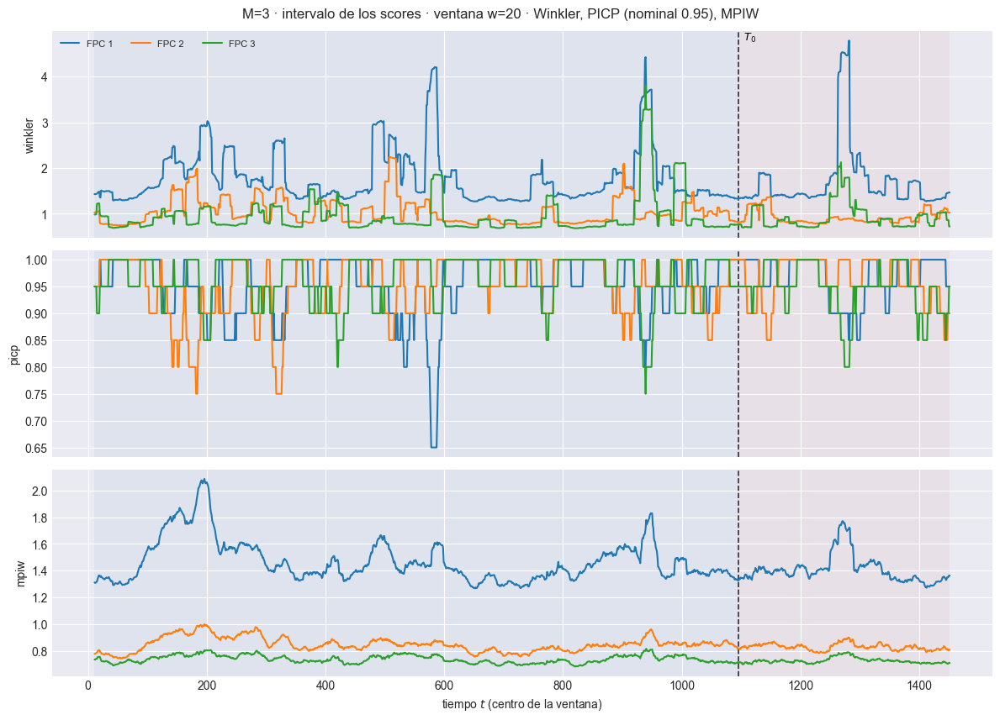

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.109  w=30 test=1.016
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.8474  w=30 test=0.829
[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m03\93_ventana_scores_intervalo_w30.png


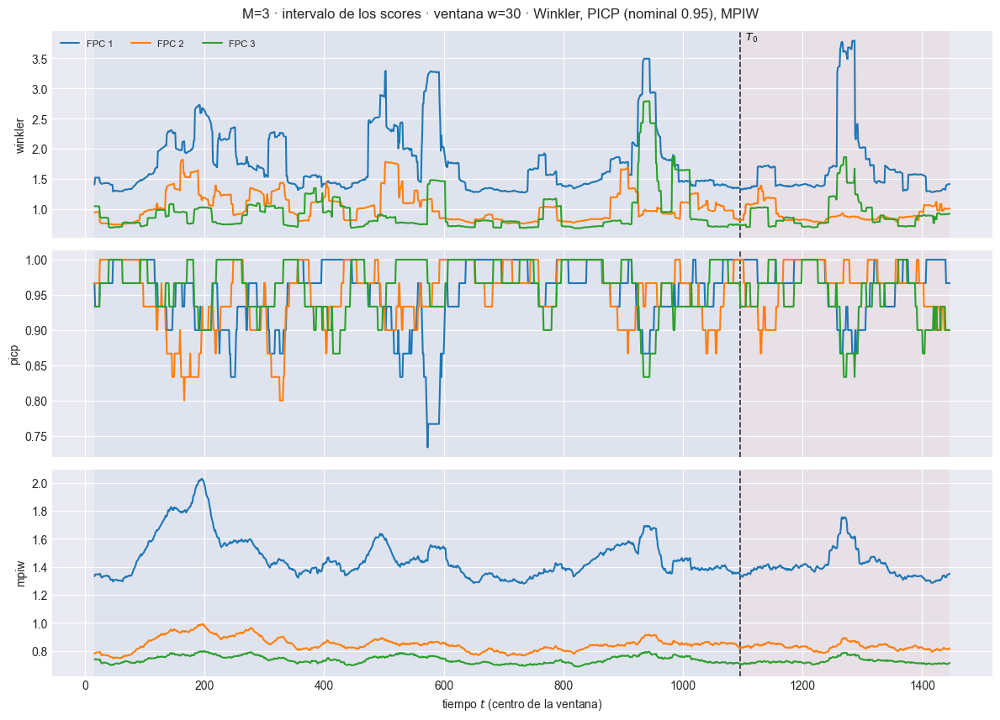

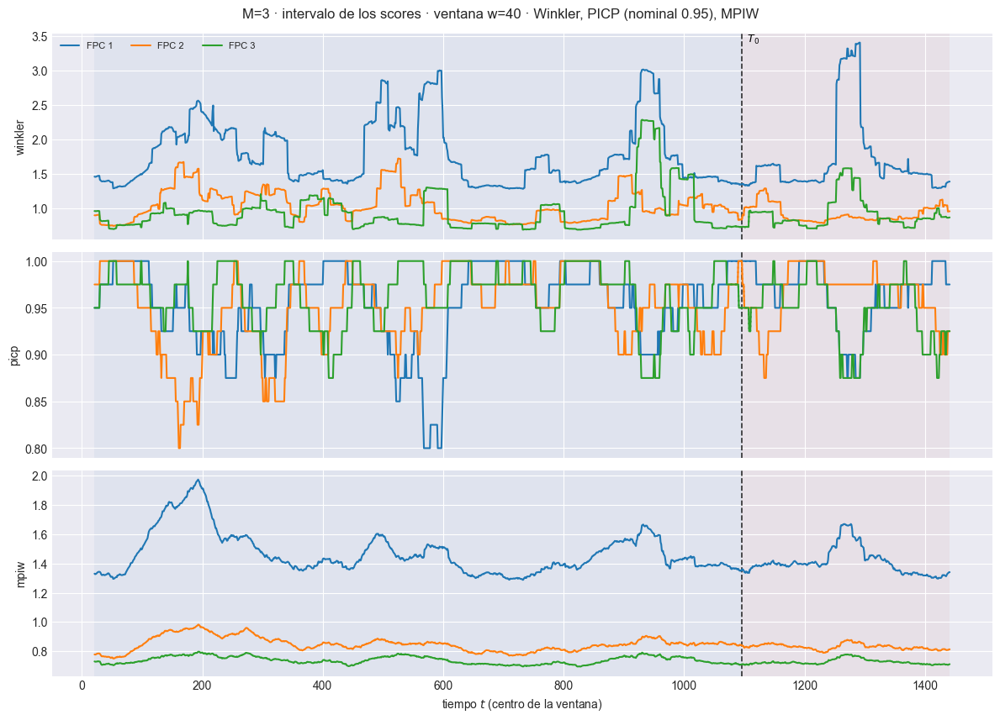

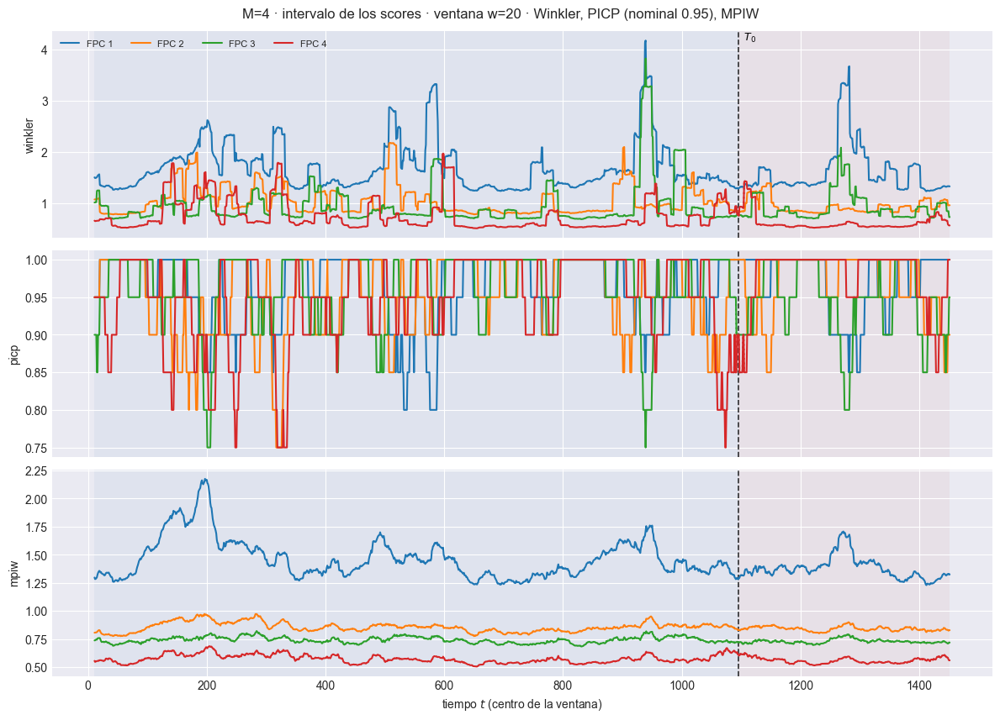

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.9789  w=30 test=0.8967
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.7902  w=30 test=0.7953
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m04\93_ventana_scores_intervalo_w30.png


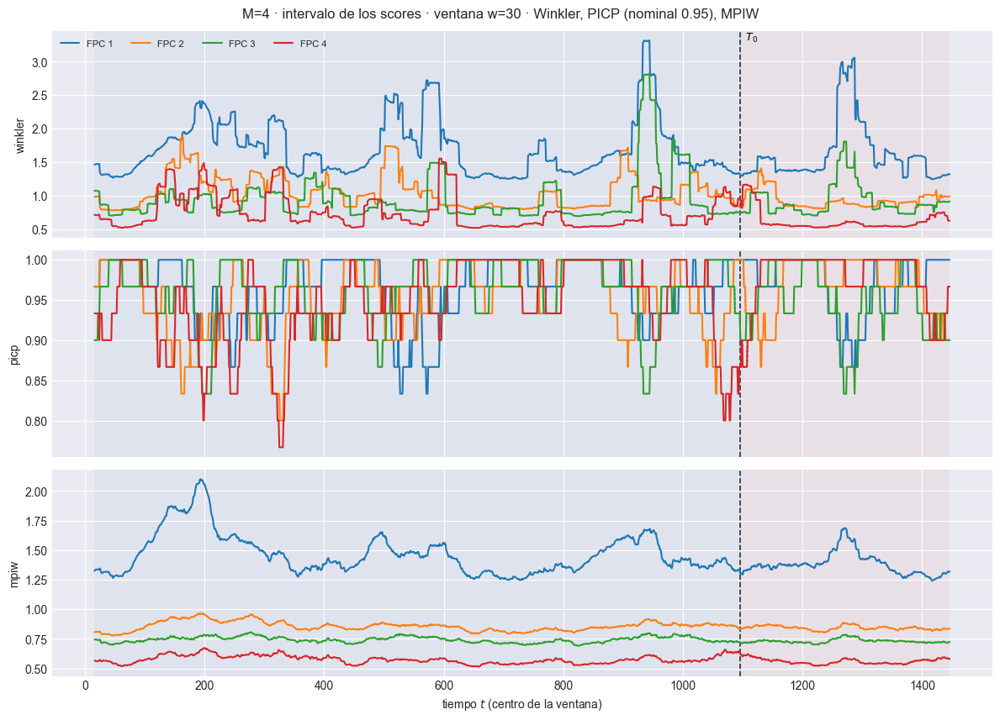

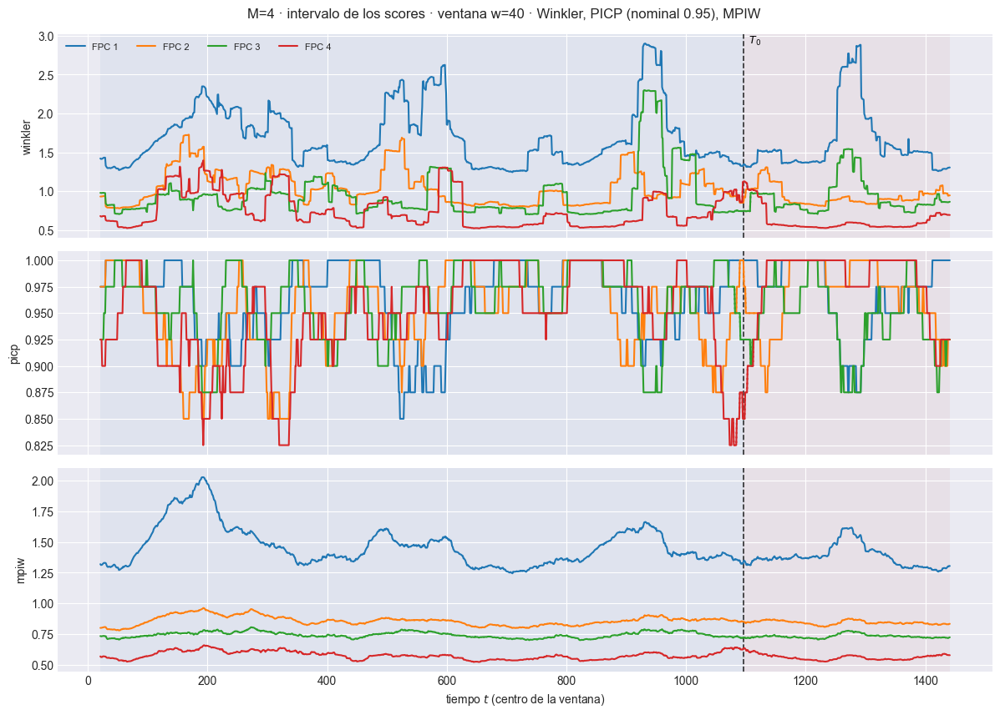

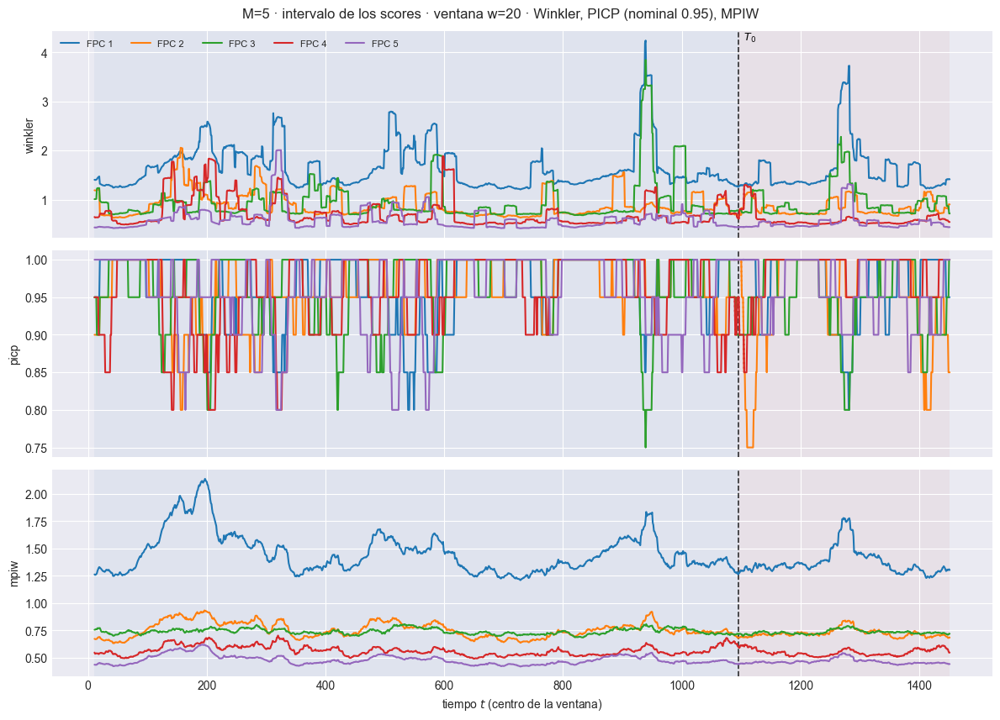

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.793  w=30 test=0.7628
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.7199  w=30 test=0.715
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m05\93_ventana_scores_intervalo_w30.png


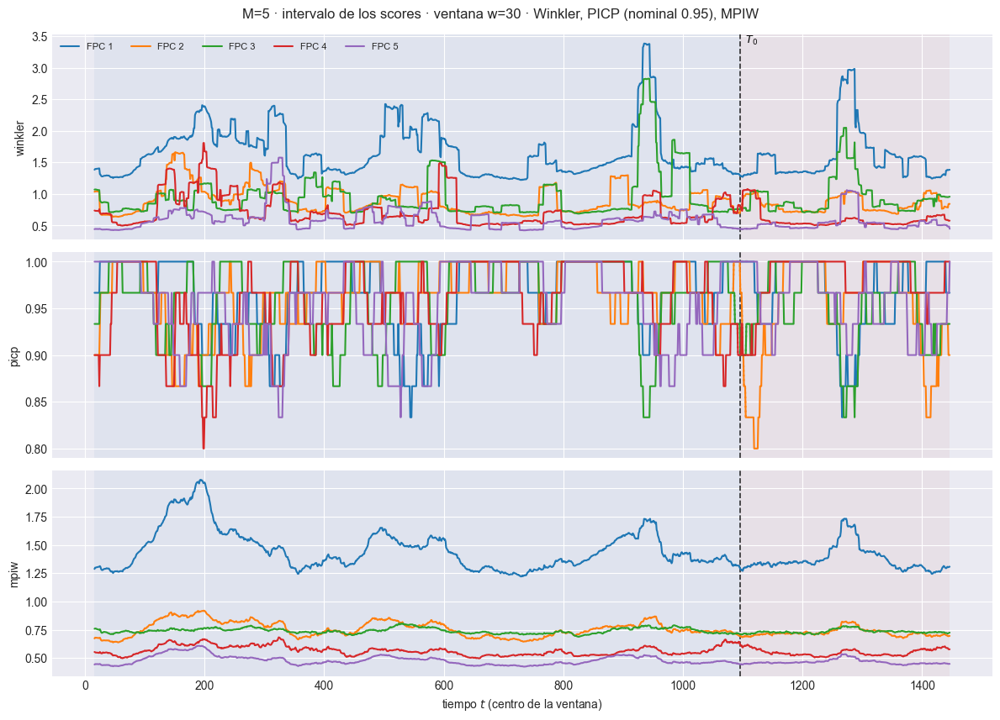

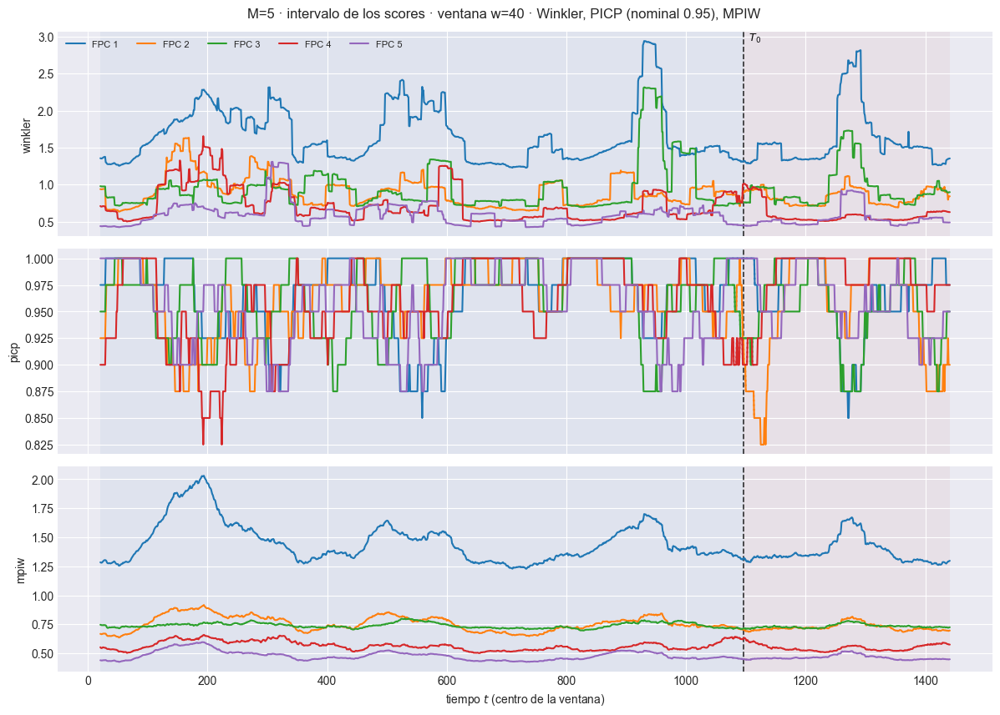

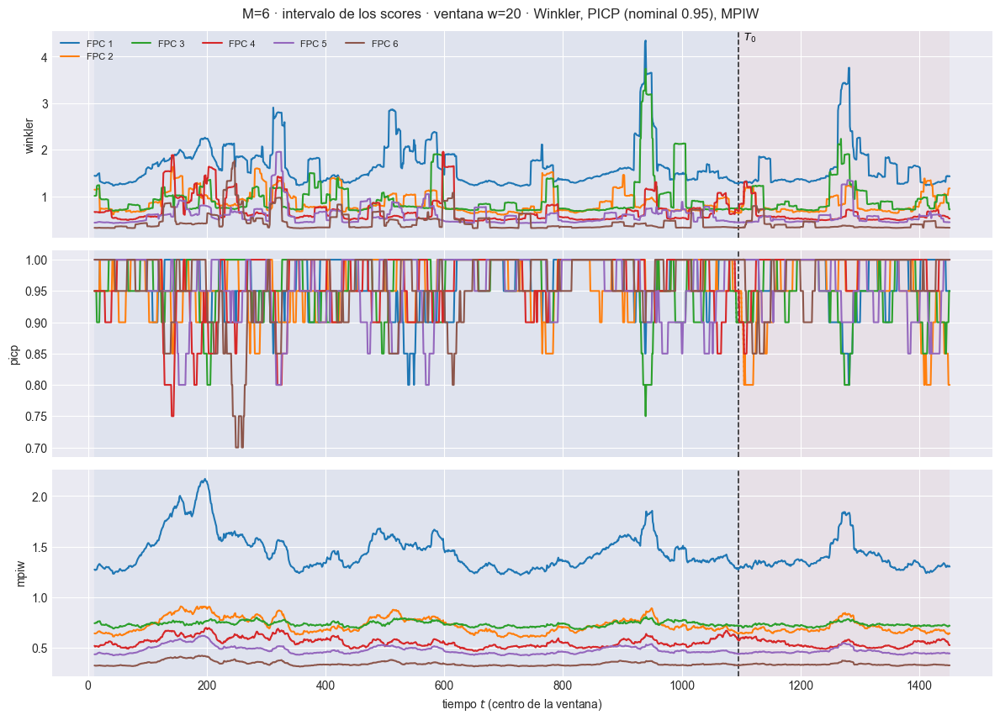

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.7272  w=30 test=0.6808
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.6326  w=30 test=0.626
[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m06\93_ventana_scores_intervalo_w30.png


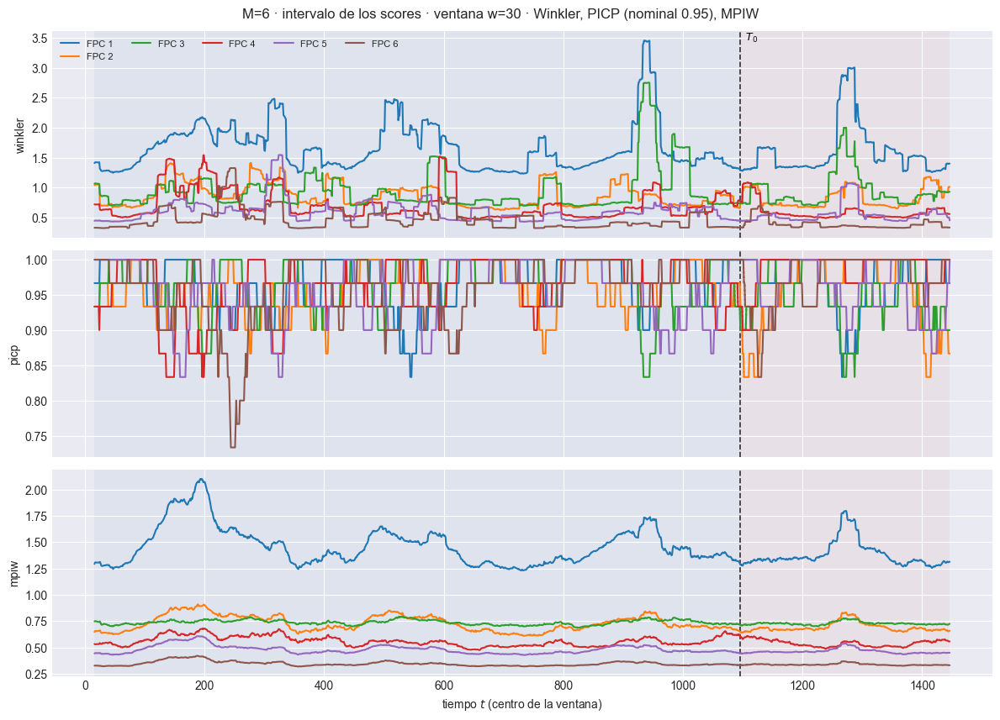

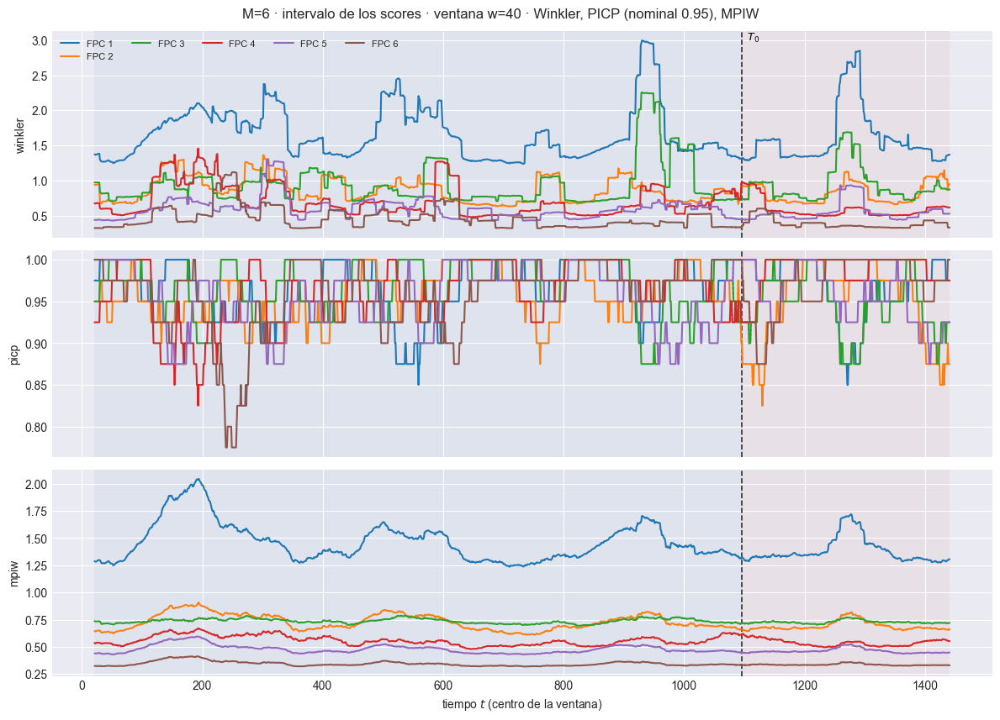

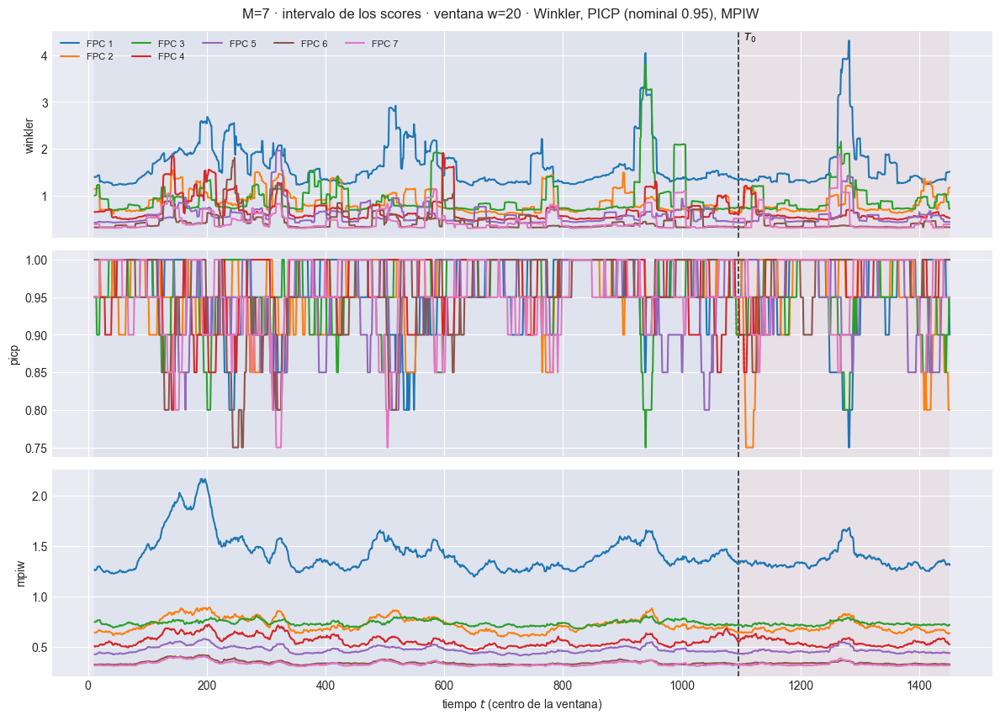

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.696  w=30 test=0.6177
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.5581  w=30 test=0.5393
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m07\93_ventana_scores_intervalo_w30.png


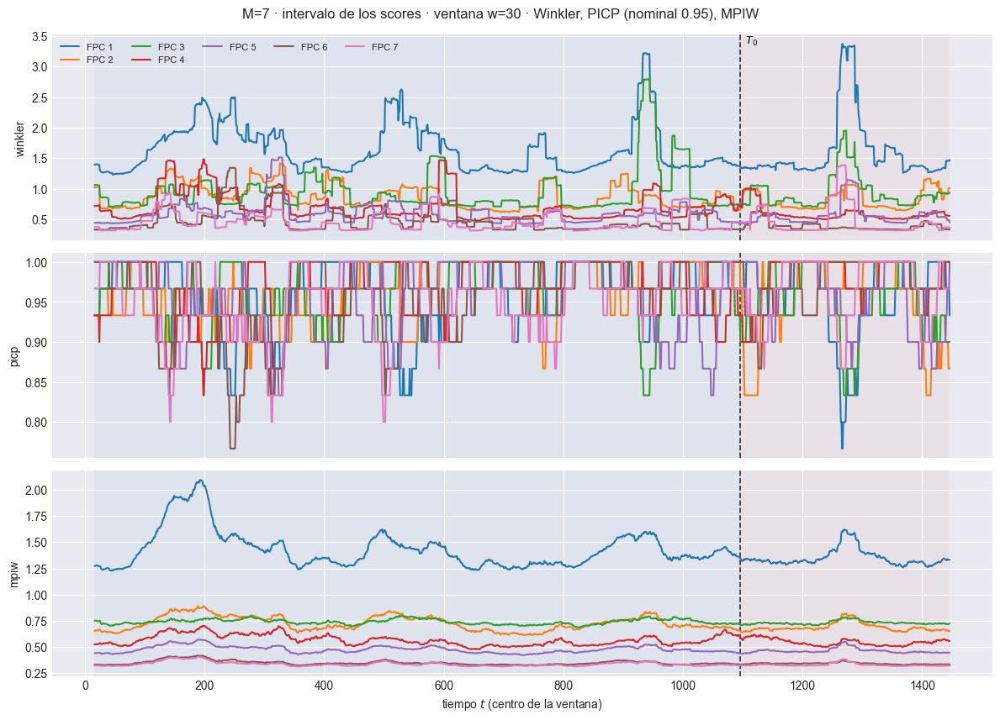

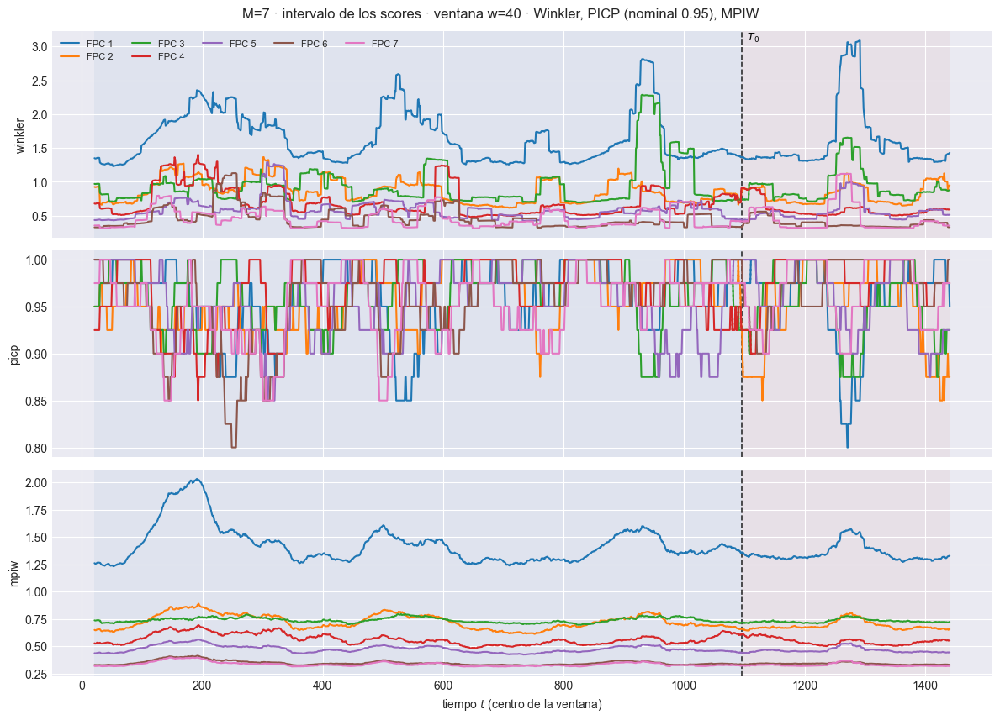

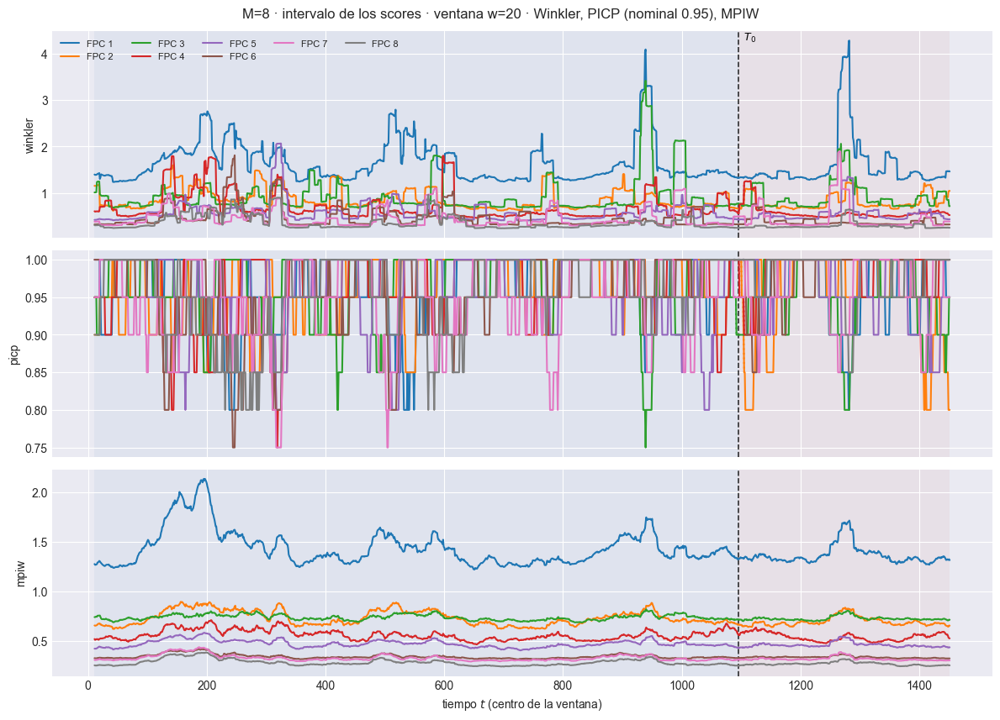

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.6549  w=30 test=0.5572
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.5135  w=30 test=0.4981
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m08\93_ventana_scores_intervalo_w30.png


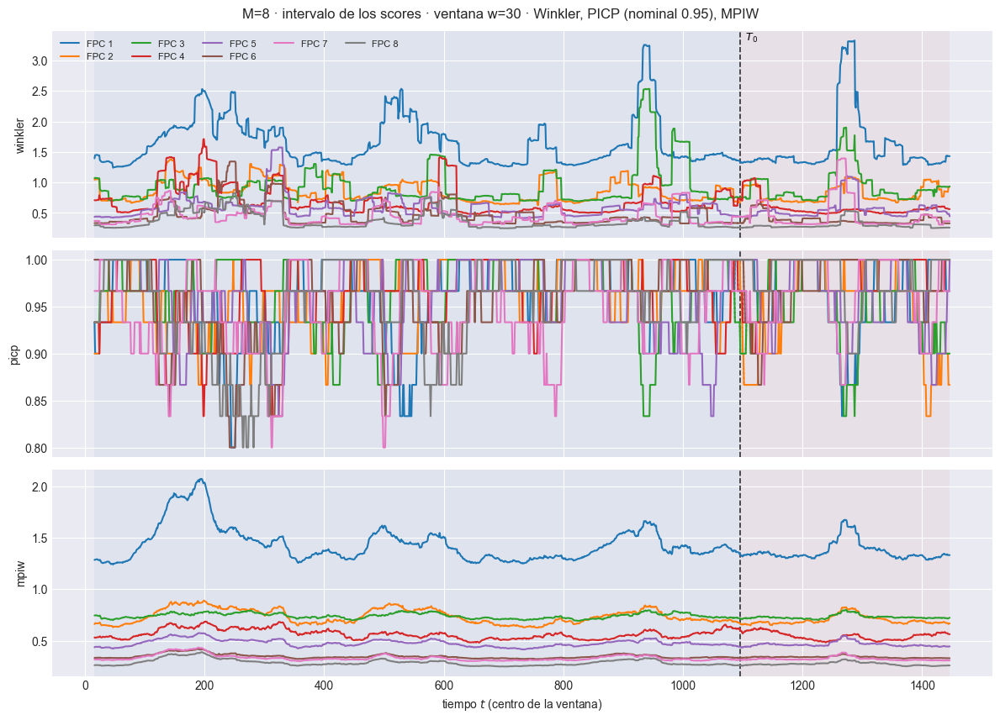

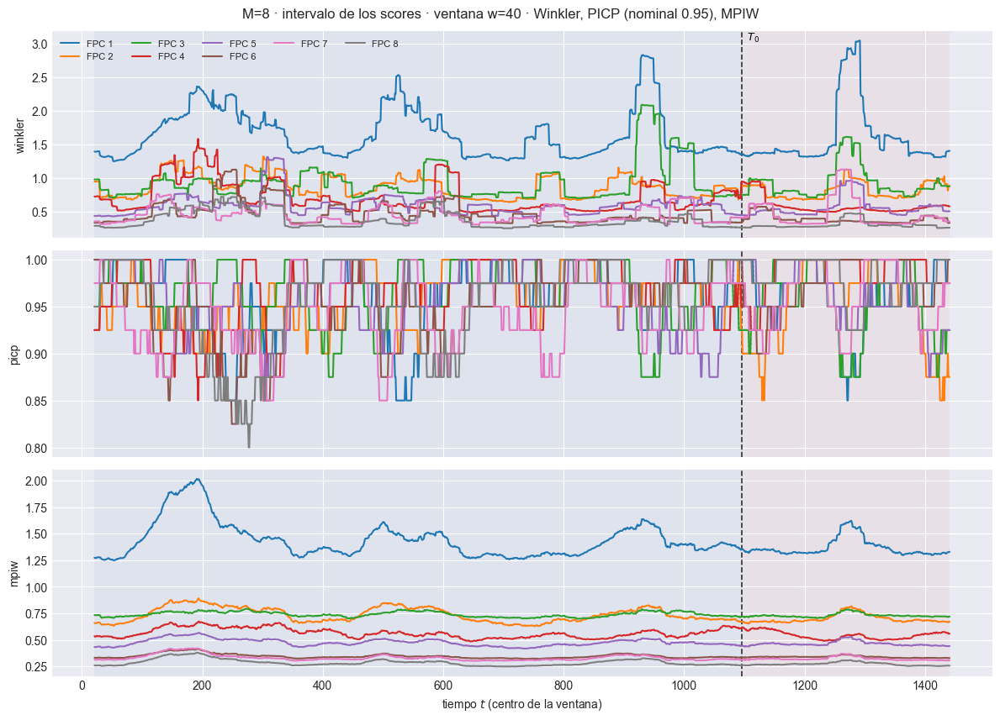

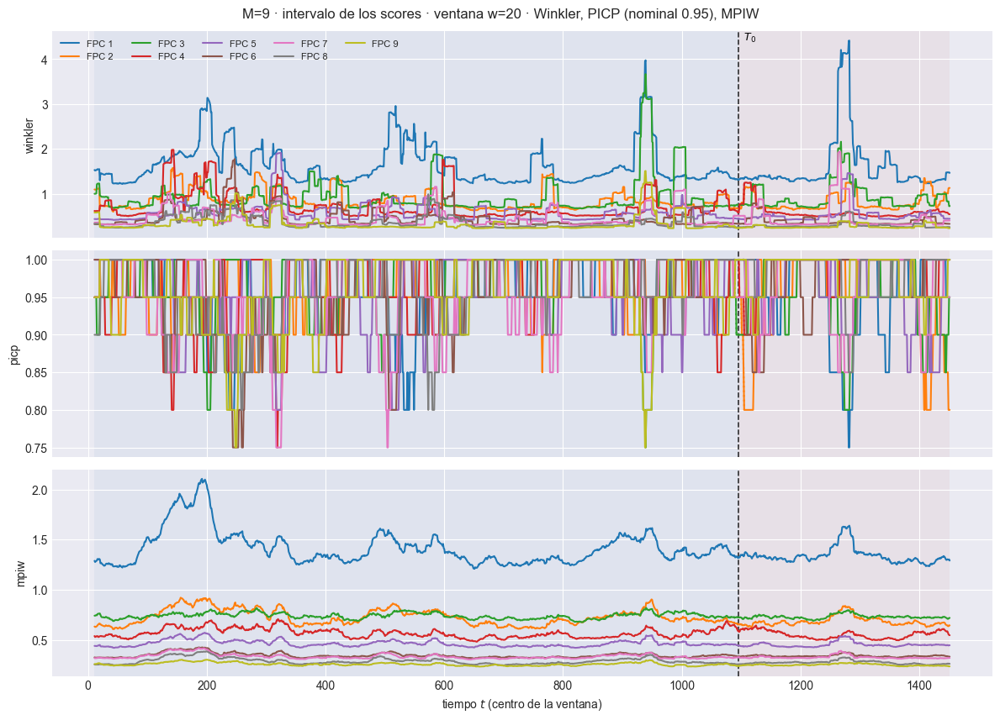

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.5927  w=30 test=0.5165
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.2s eta=0.0s  mpiw: w=30 train=0.4557  w=30 test=0.4471
[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m09\93_ventana_scores_intervalo_w30.png


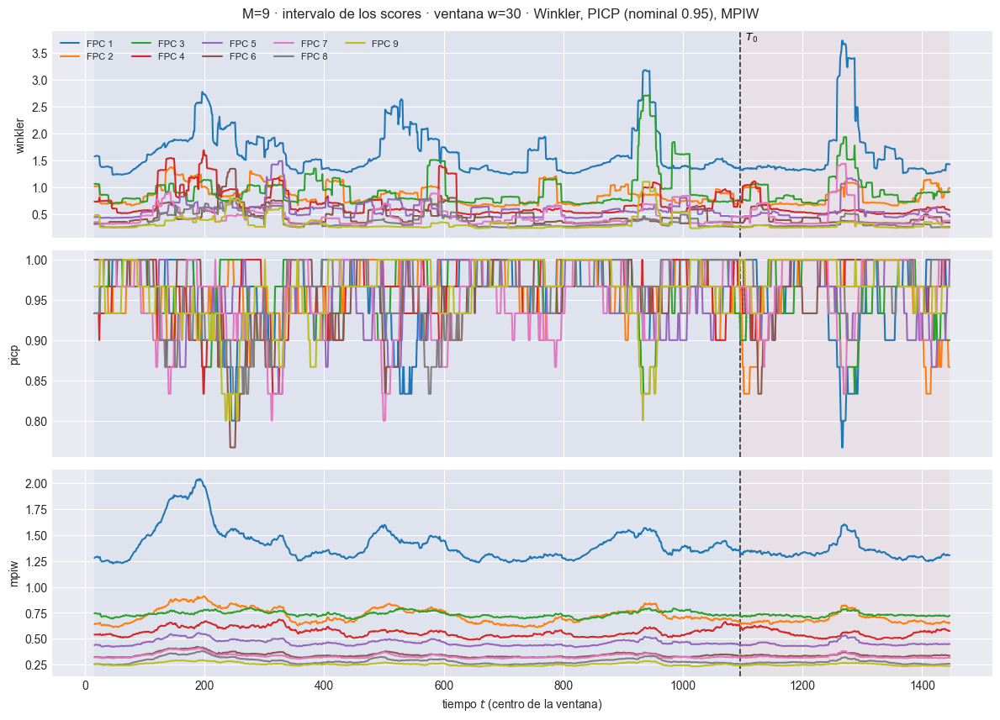

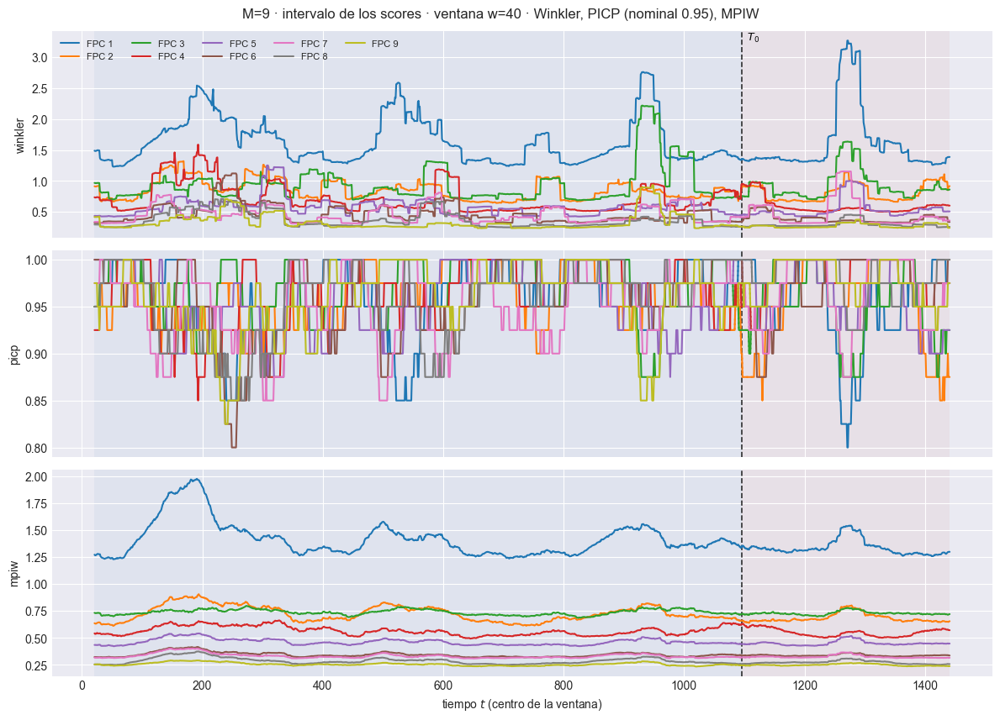

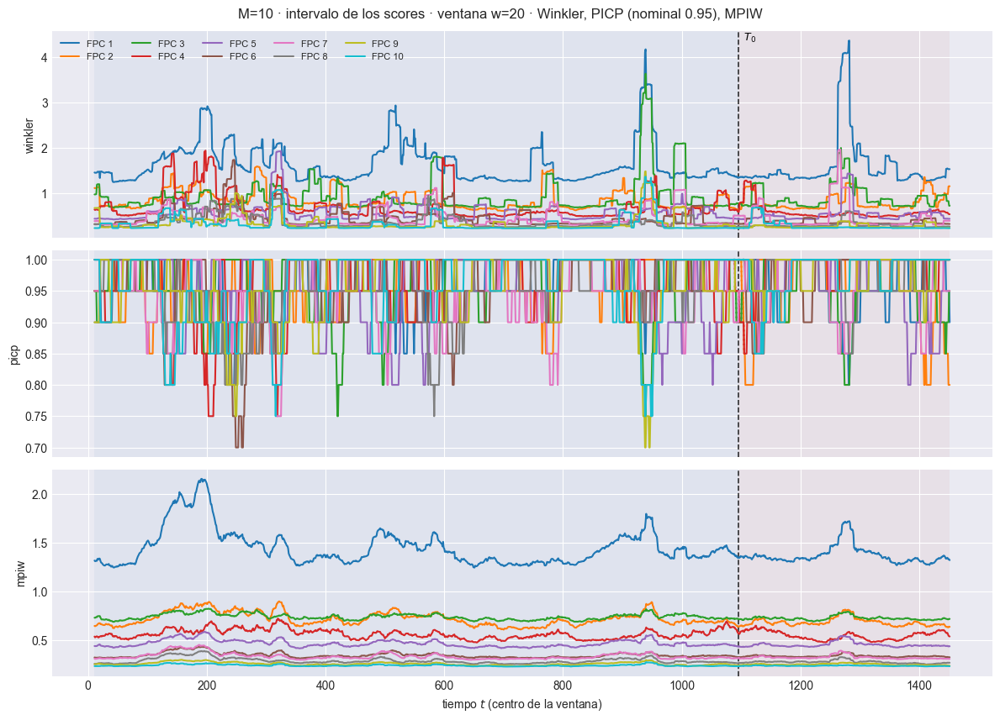

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.1s eta=0.1s  winkler: w=30 train=0.5557  w=30 test=0.489
  2/3 (66.7%) t=0.1s eta=0.1s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.2s eta=0.0s  mpiw: w=30 train=0.4239  w=30 test=0.4057
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_precio_v02_m10\93_ventana_scores_intervalo_w30.png


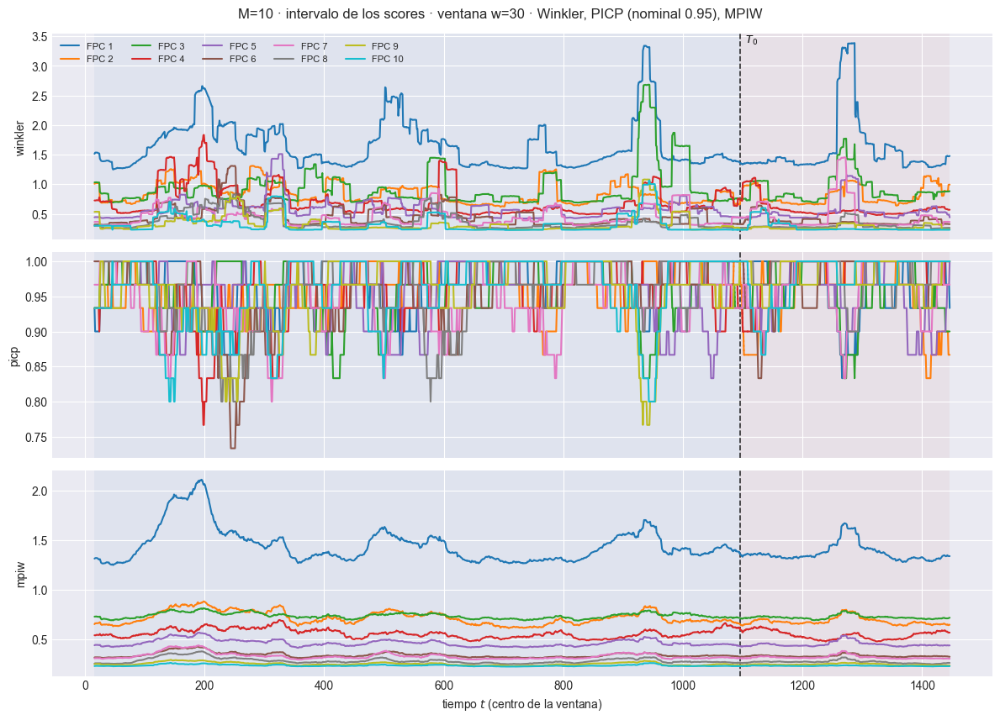

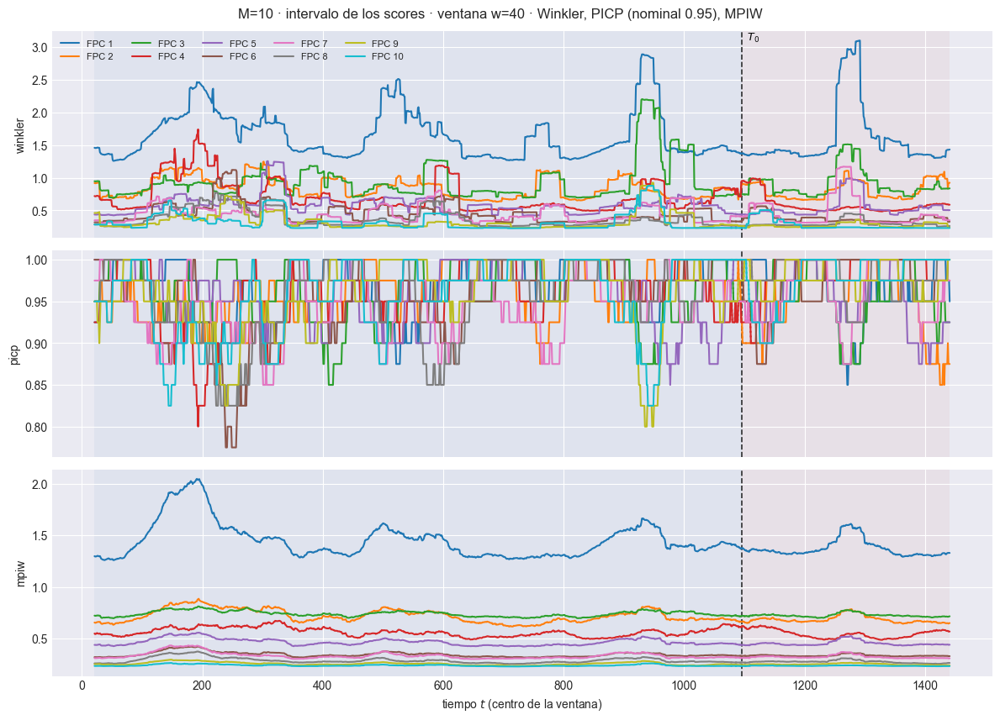

In [17]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente, con la diagonal $y=x$. Tres cosas se leen de golpe:

- **la nube pegada a la diagonal** es predicción; la nube **horizontal**
  —$\hat\xi$ casi constante mientras $\xi$ varía— es el modelo prediciendo la
  media incondicional, que es lo que pasa cuando la componente no tiene
  dinámica que capturar;
- **la pendiente** de la recta ajustada: menor que 1 es encogimiento hacia la
  media, que es el comportamiento esperado de un predictor bayesiano y no un
  defecto;
- **las barras** son el intervalo de credibilidad de una submuestra, de modo
  que se ve si los puntos que se salen de la diagonal están cubiertos.

Los puntos de train y de test van con marcador distinto: si la nube de test se
descuelga de la diagonal mientras la de train no, es deriva del bloque de
prueba y no error de ajuste.


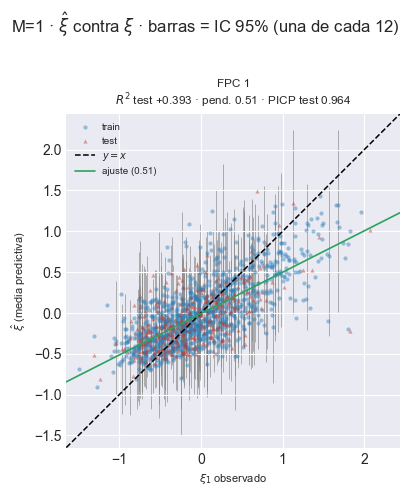

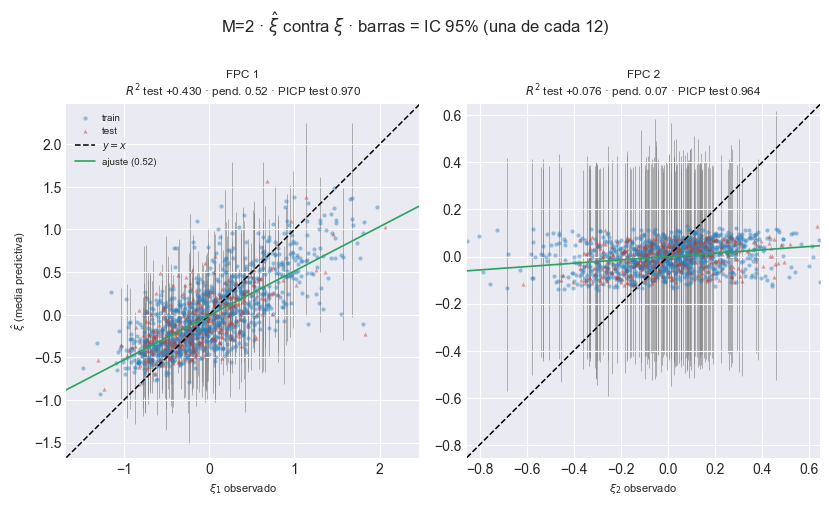

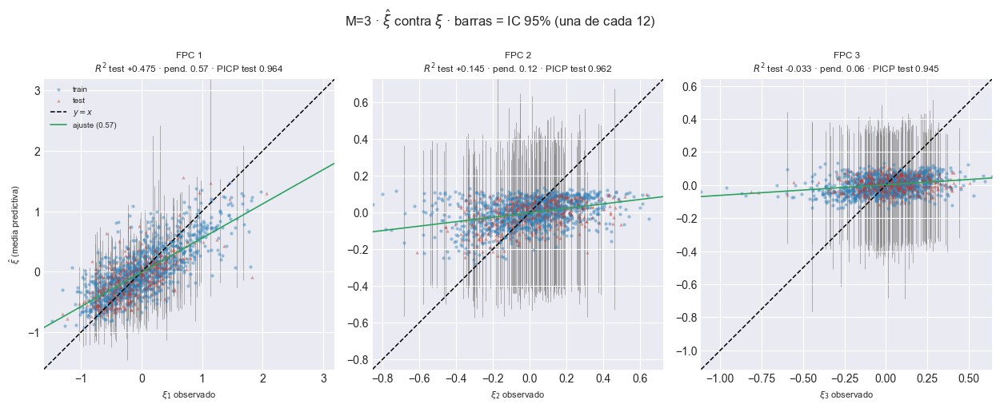

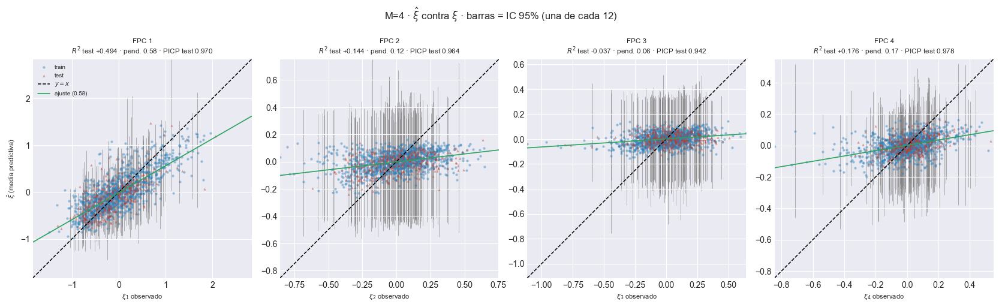

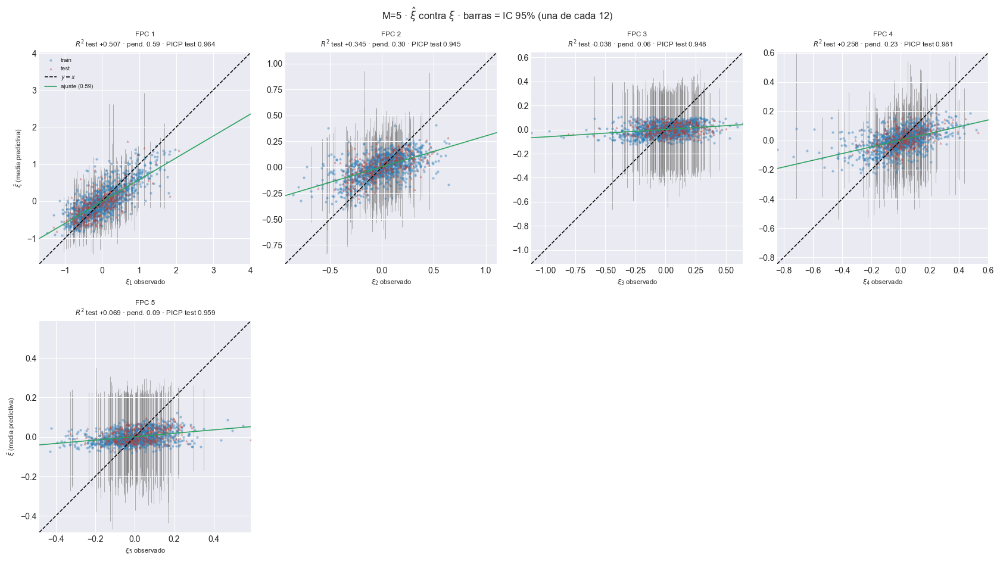

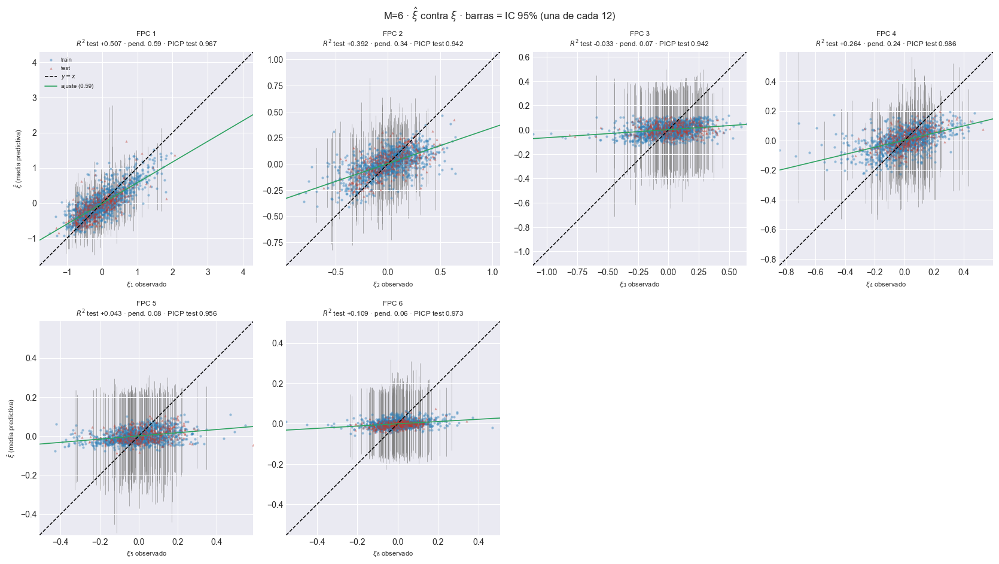

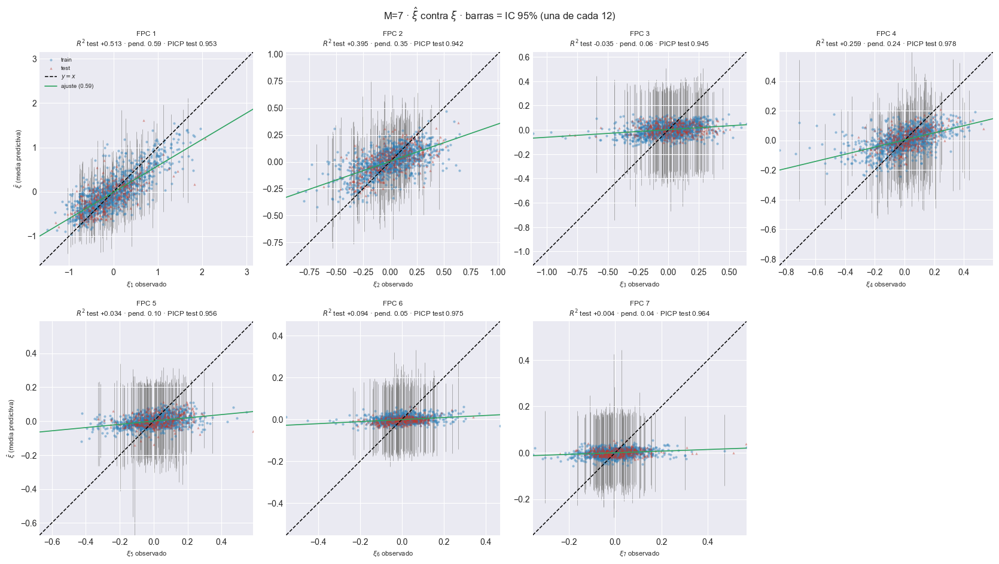

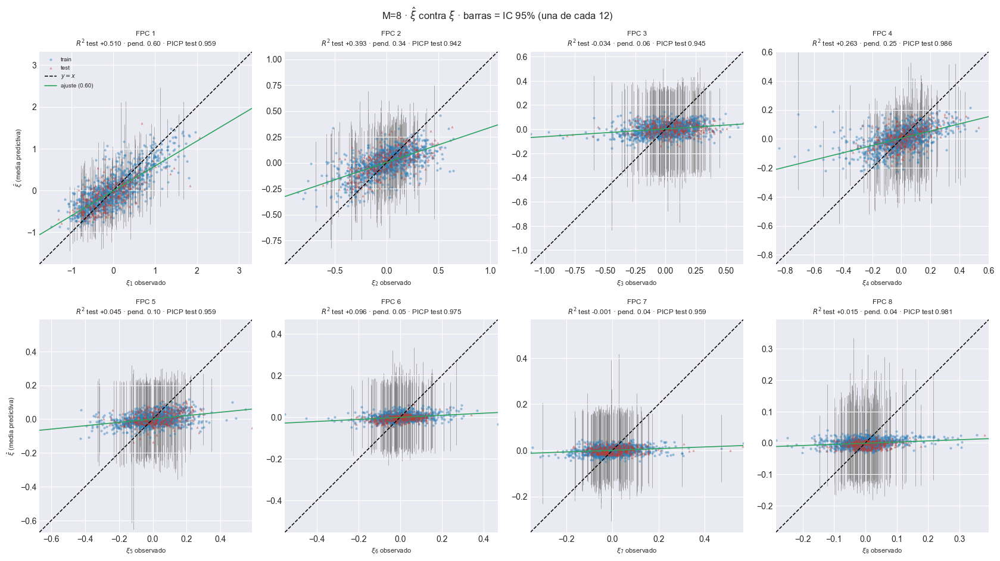

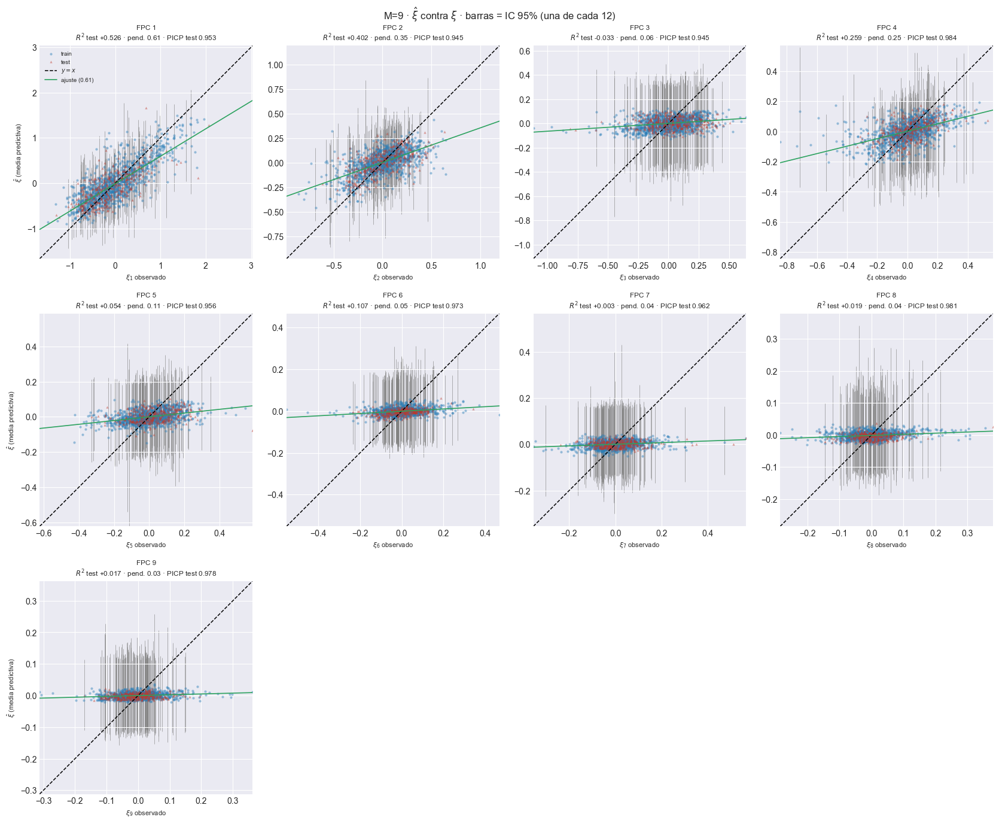

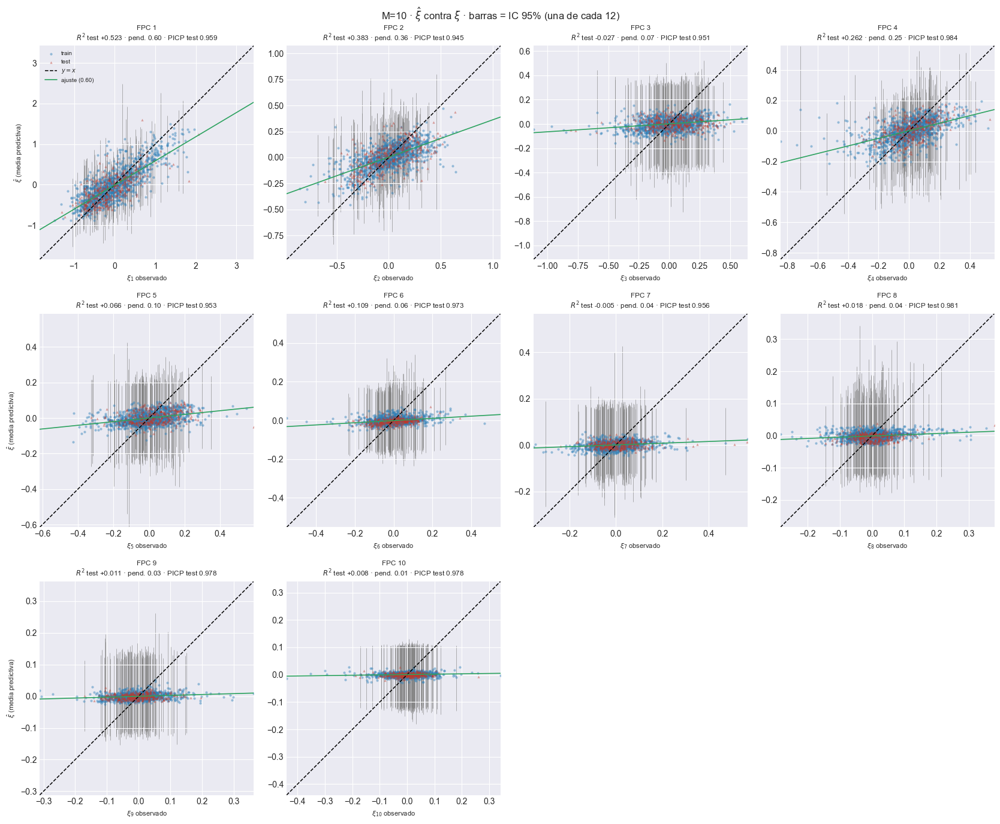

In [18]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()